# Scenario lab - transition levers for EMT Madrid

**IE Sustainability Datathon (Kearney) · supplementary notebook · not a deliverable**

> **Retrofit is supplementary.** Nothing in this notebook enters `File_1-4.csv` or the report's base case; it runs on notebook 01's exports and File 4 inputs (`data_derived/nb01_params.json`), so both notebooks use the same fleet, bus life, charger cost and deliveries.

This notebook tests transition strategies that the brief's two mandatory scenarios cannot express.
`File_4.csv` is fixed at **20 rows - 2026-2035 x scenario {0, 1}** and the final compliance cell in
notebook 01 asserts exactly that, so a third strategy can never live in the deliverable. Following the
README rule - *supplementary analyses are printed in the notebook, never written into `File_1-4.csv`* -
everything here stays on screen.

**The question.** EMT runs 1,748 CNG buses at a mean age of 6.6 years. Reaching 100% zero-emission
means retiring most of them long before the end of their life. **Retrofitting** a CNG bus to
battery-electric keeps the vehicle and replaces the driveline. Where is that worth doing - and what
does it cost once the bus has to be replaced anyway?

**Retrofit is modelled as a conditional complement, not a strategy.** Three constraints decide where
it can apply at all:

- **Range.** A repower carries a pack sized to the gas-tank envelope, about 280 kWh, which works out
  near **150 km** of duty - roughly half a new BEV's 300 km, not the 70% an earlier draft of this
  notebook assumed. That fits the shortest-duty lines and nothing else.
- **Age.** A conversion is worth doing between about **5 and 11 years** old: younger throws away a
  fresh driveline, older cannot earn back the cost before the body is finished.
- **Time.** No CNG-to-battery kit is homologated today, so nothing converts before **2028** and a
  series programme starts in 2029.

So the honest framing is: *young CNG buses, on short-duty lines, from 2029*, alongside a new-bus
programme that does the rest. Every retrofit scenario is compared against a **buy-only control that
reaches a zero-emission fleet in the same year**, because comparing plans that finish in different
years rewards whichever finishes later and calls it cheaper. The headline figures are **cash capex**
and **cost per zero-emission bus-year**; residual value at end-2035 is reported, never used to rank.

**What the model does.** One pure function, `simulate(scenario)`, returns a year-by-year table.
The flat historical pace and S1 are two entries in a registry; retrofit strategies are more entries. Every lever lives in
the scenario dict, so each one is a sensitivity.

**Depot-level charging, since 23 Nov 2026.** Sections 5 and 6 of notebook 01 now give every line a
primary depot and every depot a connection estimate, so section 7 reports **per-depot** managed power
by scenario and year against those connections - where Sanchinarro's evidenced 8 MW actually bites.
Three of the five connections are still proxies from charging-point counts, so readiness is
indicative, exactly as section 6 labels it.

> **The gating question is unresolved: no CNG-to-battery kit is evidenced for a city bus.** Every
> programme found converts diesel; the only CNG approval traced is for an intercity coach. Costs and
> lives below are sourced from diesel retrofit programmes and EMT's own contracts, and are listed in
> the assumptions register in section 7. Read the R scenarios as *what would have to be true*.

## 0 · Setup

Inputs come from notebook 01 through `data_derived/` - the same pattern notebook 02 uses for
`benchmark_gtfs_intermediate.csv`. The brief's fixed parameters are **read out of notebook 01's own
parameter cell** rather than copied, so there is only ever one copy of the brief's numbers
(README rule 1).

To produce the inputs: open notebook 01, run it through section 4, then run this once:

```python
line_out = line_table[["line_id","daily_km","peak_buses","km_per_bus_day","bus_type",
                       "energy_kwh_bus_day","charging_strategy","co2_avoided_t_year"]].copy()
line_out.insert(0, "route_id", line_table.index)
line_out.to_csv(os.path.join(DERIVED, "line_table.csv"), index=False, encoding="utf-8")
blk.to_csv(os.path.join(DERIVED, "blocks.csv"), index=False, encoding="utf-8")
# trade and model matter: a retrofit kit is developed per vehicle family, so the retro_models lever
# needs them. They come straight from emt_fleet_history.csv, so no new source is involved.
f25[["vehicleId","fuelType","size","age_years","trade","model"]].to_csv(
    os.path.join(DERIVED, "fleet_2025.csv"), index=False, encoding="utf-8")
json.dump(dict(BASELINE_2025=BASELINE_2025, REF_DATE=REF_DATE, SUPPLY_DATE=SUPPLY_DATE,
               ZE_2020=int(ZE_2020), S0_PACE_UNADJUSTED=float(S0_PACE_UNADJUSTED)),
          open(os.path.join(DERIVED, "baseline.json"), "w"), indent=1)

# Sections 5 and 6: the line-to-depot mapping and the connection estimates, for section 7 here.
(pd.DataFrame({"route_id": DEPOT_OF.index, "line_id": lines.line_id.reindex(DEPOT_OF.index).values,
               "depot_name": DEPOT_OF.values,
               "depot_km": [round(DIST.at[r, DEPOT_OF[r]], 2) for r in DEPOT_OF.index],
               "depot_pure_nearest": pure.reindex(DEPOT_OF.index).values,
               "source": "notebook 01 section 5"})
   .to_csv(os.path.join(DERIVED, "depot_lines.csv"), index=False, encoding="utf-8"))
(DEPOT_CONN.merge(CONN_EVIDENCE.drop(columns=["evidence", "url"]), on="depot_name")
   .assign(capacity_buses=lambda d: d.depot_name.map(CAP.round(0).astype(int)),
           source="notebook 01 sections 5-6")
   .to_csv(os.path.join(DERIVED, "depots.csv"), index=False, encoding="utf-8"))
```

Section 7 here is skipped, with a note, if those two files are absent.

If `f25` in notebook 01 carries no `trade`/`model`, join them on `vehicleId` from
`data_raw/emt_fleet_history.csv` (take the latest row per vehicle). This notebook runs without them
and says so, with every model treated as convertible.

In [1]:
# Environment: runs as-is in Google Colab (Python 3.10+).
%pip install -q pandas numpy matplotlib

import os, json, math, datetime as dt
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)

BASE = "/content/datathon" if os.path.exists("/content") else os.path.abspath("..")
RAW, DERIVED, OUT = (os.path.join(BASE, d) for d in ("data_raw", "data_derived", "outputs"))
RUN_DATE = dt.date.today().isoformat()

# Categorical palette: fixed slot order, never cycled (light chart surface).
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, GRID = "#0b0b0b", "#52514e", "#dcdcd8"
plt.rcParams.update({
    "figure.dpi": 120, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "font.size": 9,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})
# Print where we are without echoing an absolute local path into the committed output.
print(f"Run date {RUN_DATE} | pandas {pd.__version__} | "
      f"base {'/content/datathon (Colab)' if BASE.startswith('/content') else 'repo root'}")

Note: you may need to restart the kernel to use updated packages.


Run date 2026-11-24 | pandas 3.1.1 | base repo root


**Helpers.** Same contract as notebook 01: `assume()` labels every value **V** verified · **D** derived ·
**P** proxy · **A** assumption, and `check()` prints a visible PASS/FAIL line.

In [2]:
ASSUMPTIONS, CHECKS = [], []

def assume(variable, value, label, evidence, impact="", sensitivity=""):
    assert label in {"V", "D", "P", "A"}, "label must be V, D, P or A"
    ASSUMPTIONS.append(dict(variable=variable, value=value, label=label, evidence=evidence,
                            impact=impact, sensitivity=sensitivity))
    return value

def check(name, ok, detail=""):
    ok = bool(ok)
    CHECKS.append(dict(check=name, result="PASS" if ok else "FAIL", detail=detail))
    print(f"CHECK {'PASS' if ok else 'FAIL'} | {name}" + (f" | {detail}" if detail else ""))
    return ok
print("Helpers ready: assume() labels values V/D/P/A, check() prints PASS/FAIL")


Helpers ready: assume() labels values V/D/P/A, check() prints PASS/FAIL


**Brief parameters.** Read out of notebook 01's parameter cell, never copied.

In [3]:
# The brief's fixed parameters are read out of notebook 01's own parameter cell, never copied here:
# one source of truth for every number in brief section 4.5 (README rule 1).
def load_P_from_main_notebook():
    path = os.path.join(BASE, "notebooks", "01_Madrid_Electrification_Main.ipynb")
    for c in json.load(open(path))["cells"]:
        src = "".join(c["source"])
        if c["cell_type"] == "code" and "P = dict(" in src:
            g = {"assume": assume, "pd": pd, "np": np, "display": lambda *a, **k: None}
            exec(src, g)
            return g["P"]
    raise RuntimeError("parameter cell 'P = dict(...)' not found in notebook 01 - has section 0 moved?")

P = load_P_from_main_notebook()
check("Brief parameters loaded from notebook 01 section 0",
      {"kwh_km", "range_km", "cng_kg_km", "bus_price_eur", "service_days", "charge_eff"} <= set(P),
      f"{len(P)} parameters")
print({k: P[k] for k in ("kwh_km", "range_km", "cng_kg_km", "bus_price_eur", "charge_eff", "service_days")})

CHECK PASS | Brief parameters loaded from notebook 01 section 0 | 11 parameters
{'kwh_km': {'Standard': 1.3, 'Articulated': 1.85}, 'range_km': {'Standard': 300, 'Articulated': 240}, 'cng_kg_km': {'Standard': 0.45, 'Articulated': 0.65}, 'bus_price_eur': {'Standard': 615000, 'Articulated': 800000}, 'charge_eff': 0.9, 'service_days': 365}


**Inputs from notebook 01.** Line model, vehicle blocks, 2025 fleet, baseline, depots and File 4 parameters, checked against File 2.

In [4]:
# Inputs from notebook 01 (git-ignored intermediates; the markdown above says how to regenerate them).
NEEDED = {
    "line_table.csv": "section 4 line model",
    "blocks.csv":     "section 4 per-block km",
    "fleet_2025.csv": "section 3 fleet at 31 Dec 2025",
    "baseline.json":  "section 3 BASELINE_2025",
    "nb01_params.json": "section 8 File 4 inputs",
}
missing = [f for f in NEEDED if not os.path.exists(os.path.join(DERIVED, f))]
if missing:
    raise FileNotFoundError(
        "Missing notebook 01 intermediates in data_derived/: " + ", ".join(missing) +
        "\nRun notebook 01 through section 4, then the export snippet in the markdown cell above.")

lines_in = pd.read_csv(os.path.join(DERIVED, "line_table.csv"), dtype={"route_id": str, "line_id": str})
blocks   = pd.read_csv(os.path.join(DERIVED, "blocks.csv"), dtype={"route_id": str, "block_id": str})
fleet25  = pd.read_csv(os.path.join(DERIVED, "fleet_2025.csv"), dtype={"vehicleId": str})
meta     = json.load(open(os.path.join(DERIVED, "baseline.json")))
B25, REF_DATE = meta["BASELINE_2025"], meta["REF_DATE"]

# Sections 5-6 of notebook 01 (depot allocation and connection MW). Optional: section 7 here says so
# and skips if they are not exported yet.
DEPOT_FILES = ("depot_lines.csv", "depots.csv")
HAS_DEPOTS = all(os.path.exists(os.path.join(DERIVED, f)) for f in DEPOT_FILES)
if HAS_DEPOTS:
    depot_lines = pd.read_csv(os.path.join(DERIVED, "depot_lines.csv"),
                              dtype={"route_id": str, "line_id": str})
    depots = pd.read_csv(os.path.join(DERIVED, "depots.csv"))
    print(f"Depot inputs: {len(depots)} depots, {len(depot_lines)} lines mapped "
          f"| provenance: {depots.source.iloc[0]}")
else:
    print("NOTE  no depot_lines.csv / depots.csv in data_derived/: section 7 (per-depot power) is "
          "skipped. Run the export snippet in the section 0 markdown after notebook 01 section 6.")

PEAK_TOTAL = int(lines_in.peak_buses.sum())
SPARE_2025 = B25["fleet_total"] - PEAK_TOTAL

print(f"Reference day {REF_DATE} | lines {len(lines_in)} | daily km {lines_in.daily_km.sum():,.0f}"
      f" | peak buses {PEAK_TOTAL:,}")
print(f"Fleet {B25['fleet_total']:,} = {B25['n_bev']} BEV + {B25['n_h2']} H2 + {B25['n_cng']} CNG"
      f" | spare over peak: {SPARE_2025}")
print(f"Blocks {len(blocks):,} | over range at today's ranges: {int(blocks.over_range.sum())}")
print(f"Bus type mix: {lines_in.bus_type.value_counts().to_dict()}")
display(lines_in.head(5))
check("Fleet identity at 31 Dec 2025", B25["n_bev"] + B25["n_h2"] + B25["n_cng"] == B25["fleet_total"])
check("Every line has a positive peak_buses and daily_km",
      (lines_in.peak_buses > 0).all() and (lines_in.daily_km > 0).all())
_ = check("Spare buses over peak demand is positive", SPARE_2025 > 0, f"{SPARE_2025} buses")
NB01 = json.load(open(os.path.join(DERIVED, "nb01_params.json")))
F2 = pd.read_csv(os.path.join(OUT, "File_2.csv"), dtype={"line_id": str})
check("Inputs match File 2: peak buses and daily km", PEAK_TOTAL == int(F2.peak_buses.sum()) and abs(lines_in.daily_km.sum() - F2.daily_km.sum()) < 1,
      f"{PEAK_TOTAL:,} peak buses, {lines_in.daily_km.sum():,.1f} km a day")
check("Inputs match notebook 01's File 4 parameters", NB01["fleet"] == B25["fleet_total"] and NB01["peak_buses"] == PEAK_TOTAL)
print(f"Reserve: {SPARE_2025} spare buses = {SPARE_2025 / PEAK_TOTAL:.1%} of peak buses (SPARE_RATIO here) "
      f"= {SPARE_2025 / B25['fleet_total']:.1%} of the fleet (notebook 01's r): one number, two denominators")


Depot inputs: 5 depots, 234 lines mapped | provenance: notebook 01 sections 5-6
Reference day 2026-11-17 | lines 234 | daily km 341,431 | peak buses 2,034
Fleet 2,210 = 452 BEV + 10 H2 + 1748 CNG | spare over peak: 176
Blocks 2,106 | over range at today's ranges: 74
Bus type mix: {'Standard': 225, 'Articulated': 9}


,route_id,line_id,daily_km,peak_buses,km_per_bus_day,bus_type,energy_kwh_bus_day,charging_strategy,co2_avoided_t_year
0,001,1,1392.458105,11,126.587100,Standard,164.563231,Depot,541.942587
1,002,2,1990.403987,16,124.400249,Standard,161.720324,Depot,774.662219
2,003,3,1777.251381,14,126.946527,Standard,165.030485,Depot,691.703547
3,004,4,1592.927612,11,144.811601,Standard,188.255081,Depot,619.965015
4,005,5,1575.084799,10,157.508480,Standard,204.761024,Depot,613.020619


CHECK PASS | Fleet identity at 31 Dec 2025
CHECK PASS | Every line has a positive peak_buses and daily_km
CHECK PASS | Spare buses over peak demand is positive | 176 buses
CHECK PASS | Inputs match File 2: peak buses and daily km | 2,034 peak buses, 341,431.4 km a day
CHECK PASS | Inputs match notebook 01's File 4 parameters
Reserve: 176 spare buses = 8.7% of peak buses (SPARE_RATIO here) = 8.0% of the fleet (notebook 01's r): one number, two denominators


## 1 · Levers

Every lever is a named value that `simulate()` can override, so any of them can be swept. Each one
carries its label - **V** verified · **D** derived · **P** proxy · **A** assumption - and its source.

Retrofit costs and lives are now **proxies from real diesel retrofit programmes** (e-troFit,
Wrightbus NewPower, KleanDrive, Empa) and from EMT's own contracts and amortisation policy, not
placeholders. The four open research questions were checked on 23 Nov 2026 (answers in section 8).
The first is load-bearing and the answer is negative: **no CNG-to-battery kit exists for a city bus
on any of EMT's models.** The whole retrofit family is therefore "what would have to be true"
rather than a plan.

In [5]:
# ---- Sources -------------------------------------------------------------------------------------
# Every retrofit figure below is conditional on a kit existing for EMT's chassis, and none does (finding (1) below).
SRC = dict(
    etrofit_price="https://www.electrive.net/2021/08/03/retrofitting-im-ersten-leben-ein-diesel-im-zweiten-ein-elektrobus/",
    etrofit_kwh="https://www.eurotransport.de/fahrzeuge/lkw/elektrobus-e-trofit-ruestet-um/",
    wrightbus="https://wrightbus.com/en-gb/new-power",
    wrightbus_age="https://www.autocar.co.uk/car-news/technology/wrightbus-launches-electrification-drive-diesel-buses",
    wrightbus_first="https://bus-news.com/wrightbuss-newpower-to-convert-32-first-bus-vehicles-to-electric-drives/",
    kleandrive="https://www.electrive.com/2026/02/12/repower-revolution-how-kleandrive-plans-to-electrify-britains-buses-one-subframe-at-a-time/",
    empa="https://www.electrive.com/2026/07/16/study-e-retrofits-could-accelerate-bus-fleet-electrification-by-15-years/",
    retrofleet="https://www.sustainable-bus.com/news/retrofleet-why-choose-retrofit-to-convert-fleets-and-save-money/",
    emt_cng_life="https://diario.madrid.es/?p=124394",
    emt_amort="https://diario.madrid.es/?p=17529",
    emt_200gas="https://diario.madrid.es/?p=72588",
    emt_sanchinarro="https://diario.madrid.es/blog/notas-de-prensa/emt-madrid-instalara-114-pantografos-para-electrificar-el-centro-de-operaciones-de-sanchinarro/",
    emt_linea6="https://diario.madrid.es/blog/notas-de-prensa/emt-madrid-fletara-dos-servicios-especiales-y-una-lanzadera-durante-las-obras-de-la-linea-6-de-metro/",
    emt_1222="https://diario.madrid.es/?p=46197",
    tcrp109="https://www.nap.edu/read/22409/chapter/2",
    bath="https://researchportal.bath.ac.uk/en/publications/charging-forward-how-bus-availability-drives-the-economics-of-fle/",
    apta_spare="https://apta.com/wp-content/uploads/APTA-Impacts-of-Spare-Ratio-Full-Report-03-2025.pdf",
    transbus_retrofit="https://www.transbus.org/dossiers/retrofit-autobus-autocars.html",
    lightning="https://www.electrive.com/2024/02/27/gillig-acquires-select-lightning-emotors-assets-in-receivership",
    pepper="https://transformative-mobility.org/wp-content/uploads/2023/06/TUMIVolt_Charging-Station_Webinar14_E-Bus-Retrofitting_Reisenauer.pdf",
    pniec="https://www.miteco.gob.es/content/dam/miteco/es/energia/files-1/pniec-2023-2030/PNIEC_2024_240924.pdf",
    redata="https://apidatos.ree.es/es/datos/generacion/no-renovables-detalle-emisiones-CO2?start_date=2023-01-01T00:00&end_date=2025-12-31T23:59&time_trunc=year",
    climate_analytics="https://1p5ndc-pathways.climateanalytics.org/countries/spain/sectors/power",
    ted_2026_27="https://ted.europa.eu/es/notice/809938-2025/pdf",
    emt_2033="https://www.elespanol.com/eventos/2026/wake-up-spain/20260416/alfonso-sanchez-emt-toda-flota-cero-emisiones-coste-euros/1003744209190_0.amp.html",
    delijn="https://www.electrive.com/2025/12/11/de-lijn-secures-up-to-500-electric-buses/",
    leipzig="https://www.daimlertruck.com/en/newsroom/pressrelease/daimler-buses-receives-a-complete-order-e-bus-depot-and-e-buses-for-regionalbus-leipzig-gmbh-53199837",
)

# ---- Retrofit technology and cost ---------------------------------------------------------------
# Research (1), checked 23 Nov 2026 -- THE GATING QUESTION. No CNG-to-battery kit exists for a city bus
#   on any of EMT's models (Citaro NGT, Urbanway / Citelis CNG, Citywide CNG, Lion's City CNG). Every
#   approved French kit is for the Crossway or Intouro coach ({transbus_retrofit}); Retrofleet only says
#   gas city buses are "not excluded" in future ({retrofleet}); e-troFit, Pepper Motion, Wrightbus
#   NewPower and KleanDrive convert diesel buses. The one diesel-or-CNG repower programme (Lightning
#   eMotors, US) ended in receivership ({lightning}). Read the R scenarios as "what would have to be
#   true", not as a plan.
RETRO_KIT_TODAY = assume(
    "CNG-to-battery kit available today for EMT's city-bus models", False, "V",
    f"No approved or announced kit for a CNG city bus: the approved French kits are coach kits "
    f"({SRC['transbus_retrofit']}), Retrofleet's gas approval is the Crossway coach ({SRC['retrofleet']}), "
    f"the other programmes convert diesel, and the only CNG repower programme closed ({SRC['lightning']}). "
    "Absence of evidence, searched in English, French, Spanish and German",
    "whether the R scenarios are a plan or a what-if (recorded, not a model input)")
RETRO_COST = assume(
    "Retrofit cost per bus (EUR)", {"Standard": 350_000, "Articulated": 450_000}, "P",
    f"e-troFit quotes EUR 300-360k per solo bus including conversion ({SRC['etrofit_price']}); "
    f"Wrightbus NewPower is marketed at about half the price of a new BEV ({SRC['wrightbus']}); "
    f"KleanDrive under 50% ({SRC['kleandrive']}); Empa about half ({SRC['empa']}). "
    "Articulated = Standard x 1.28, the ratio of EMT's new-bus prices (A)",
    "capex_meur, net capex, EUR/tCO2", "swept: 250k / 350k / 450k")

RETRO_PILOT_N = assume(
    "Conversions charged at the first-of-a-kind premium", 10, "A",
    "First-of-a-kind engineering, chassis integration and homologation of a reforma de importancia "
    "are one-off costs carried by the first units, not by the series",
    "capex in the pilot year")

RETRO_PILOT_PREMIUM = assume(
    "First-of-a-kind cost premium on those conversions", 0.30, "A",
    "Engineering and type approval for a vehicle family that has never been converted",
    "capex in the pilot year")

RETRO_BATTERY_KWH = assume(
    "Battery fitted in a retrofit (kWh)", {"Standard": 280, "Articulated": 450}, "A",
    f"e-troFit fits up to 320 kWh in a solo bus ({SRC['etrofit_kwh']}). A repower is constrained by "
    "the gas-tank envelope and axle loads, so it carries less than a purpose-built BEV",
    "retrofit range, and therefore which lines can take one", "swept: 250 / 280 / 320")

USABLE_SHARE = assume(
    "Share of nameplate kWh usable in service", 0.75, "D",
    "The brief's own convention: a 400 km nominal range is modelled as 300 km usable in P['range_km'], "
    "so the same 75% is applied to a retrofit's pack rather than inventing a second convention",
    "retrofit range")

RETRO_KWH_MULT = assume(
    "Retrofit energy use as a share of a new BEV's", 1.05, "A",
    "A converted bus is heavier and less aerodynamically optimised than a purpose-built BEV. Applied "
    "to consumption AND to range: the same inefficiency that raises kWh/km shortens the range",
    "electricity_mwh, co2_t, retrofit range")

RETRO_ALLOW_ARTICULATED = assume(
    "Articulated buses may be retrofitted", False, "A",
    "No articulated CNG conversion kit is evidenced anywhere. Articulated lines therefore need new "
    "BEVs. True only as a sensitivity",
    "whether the 77 articulated peak buses can be retrofitted", "swept: False / True")

RETRO_MIN_AGE = assume(
    "Youngest CNG bus worth retrofitting (age at conversion, years)", 5, "A",
    f"Wrightbus targets 5-9-year-old vehicles ({SRC['wrightbus_age']}): converting a near-new CNG "
    "driveline throws away a fresh asset and worsens stranded value",
    "size of the eligible pool")

RETRO_MAX_AGE = assume(
    "Oldest CNG bus worth retrofitting (age at conversion, years)", 11, "D",
    "Breakeven: EUR 350k over a new bus at EUR 615k across 12 years needs about 7 years of "
    "post-retrofit life to pay back. With an 18-year structural cap that means converting by age 11",
    "size of the eligible pool, post-retrofit life", "swept: 8 / 11 / 14")

RETRO_LIFE_EXT = assume(
    "Years of service a retrofit adds", 8, "P",
    f"Wrightbus claims 10 years ({SRC['wrightbus']}); the First Bus order is described as 6-9 years "
    f"({SRC['wrightbus_first']}); KleanDrive 5-10 years ({SRC['kleandrive']})",
    "when retrofitted buses retire and have to be replaced again", "swept: 6 / 8 / 10")

RETRO_LIFE_CAP = assume(
    "Maximum total age of a retrofitted bus (years)", 18, "A",
    f"European city buses average about 20 years ({SRC['empa']}); Madrid duty is heavier, so the "
    "structure is capped below that. A retrofit cannot extend life past this age",
    "post-retrofit life of older conversions", "swept: 16 / 18 / 20")

RETRO_DOWNTIME_M = assume(
    "Months a bus is out of service per retrofit", 1.5, "P",
    f"Wrightbus quotes about 3 weeks ({SRC['wrightbus']}); e-troFit up to 4 weeks "
    f"({SRC['etrofit_kwh']}); plus commissioning and driver familiarisation",
    "buses in the shop, and therefore the rotation cover needed")

# No CNG city-bus kit exists yet: e-troFit needs a 3-6 month analysis phase per vehicle model, and
# Spanish homologation of a reforma de importancia is decided case by case. So nothing before 2028.
RETRO_RAMP = assume(
    "Retrofit throughput schedule (conversions per year)",
    {2026: 0, 2027: 0, 2028: 10, **{y: 150 for y in range(2029, 2036)}}, "A",
    "Pilot in 2028, series from 2029. No kit, no homologation and no shop capacity exist today; a "
    "programme cannot start in 2026. Optimistic variant: pilot 2027, series 2028",
    "how many buses can be converted at all", "swept: series 75 / 150 / 300; start 2027 / 2028 / 2029")

# ---- Fleet and operations -----------------------------------------------------------------------
BUS_LIFE = assume(
    "CNG bus service life (years)", 13, "P",
    f"EMT cut its bus amortisation period from 15 to 13 years ({SRC['emt_amort']}), and says its CNG "
    f"buses last about 10 years in Madrid service ({SRC['emt_cng_life']}). 13 is the accounting life",
    "how many CNG buses retire naturally before 2035, and how many are scrapped early",
    "swept: 10 / 13 / 15")

BEV_LIFE = assume(
    "New BEV depreciation life (years)", 12, "A",
    "Used only to value buses still in service at end-2035. Not a scrapping rule: no BEV bought in "
    "this horizon reaches the end of its life inside it",
    "residual_value_2035_meur", "swept: 12 / 15")

CHARGER_CAPEX = assume(
    "Charging infrastructure per point (EUR)", NB01["charger_eur"], "D",
    "Notebook 01 section 8 (D4): Sanchinarro award, EUR 12,581,413.59 for 114 pantographs including grid connection works "
    "and canopy = EUR 110k per point. One point per ZE bus",
    "capex_meur")

CNG_BUS_PRICE = assume(
    "CNG bus purchase price (EUR)", 310_000, "D",
    f"EMT bought 200 gas buses for EUR 62 m in 2022 ({SRC['emt_200gas']})",
    "stranded_value_meur only")

CNG_AMORT_YEARS = assume(
    "CNG bus amortisation period (years)", 13, "P",
    f"EMT's own amortisation period after the 2017 change ({SRC['emt_amort']})",
    "stranded_value_meur only")

EMBODIED_SAVED_T = assume(
    "Embodied CO2e avoided per retrofit (t)", 58, "V",
    f"Empa, via {SRC['empa']}: keeping the body and chassis avoids the embodied emissions of a new "
    "bus. Reported in its own column and NEVER added to co2_t, which is tailpipe and grid only",
    "embodied_co2_saved_t (reported separately)")

# Grid: the DEFAULT is the brief's own 2025 factor held flat, so the flat-pace run and S1 here stay comparable with
# File_4 in notebook 01. A declining path is a sensitivity, not the base case.
GRID_DEFAULT = assume(
    "Grid CO2 intensity 2026-2035 (gCO2/kWh)", float(P["grid_gco2_kwh"]), "D",
    "The brief's value in P['grid_gco2_kwh'], held flat. Using a declining path in the base case "
    "would make these scenarios incomparable with File_4, which assumes the flat factor",
    "co2_t, EUR/tCO2")

# Research (2), checked 23 Nov 2026: the PNIEC gives a 2030 factor (mainland only); no official 2035
#   projection exists. 2025's 108.4 is Red Electrica's national factor, 0.1084 t/MWh ({redata}).
GRID_2035_SENS = assume(
    "Grid CO2 intensity in 2035 under a declining path (gCO2/kWh)", 37.1, "D",
    f"PNIEC 2023-2030, Annex D, Fig. D.4 (Red Electrica, mainland, 2030 target scenario): 0.02948 t/MWh "
    f"({SRC['pniec']}). Scaled to the national basis of the 108.4 by REData's 2025 national / mainland "
    f"ratio, 0.1084 / 0.0861 = 1.259, giving 37.1 ({SRC['redata']}). Held flat to 2035: the last nuclear "
    "reactors close in 2031-2035 (PNIEC Annex A) and no official 2035 value exists. The linear path "
    "from 2025 reaches it in 2035, five years after the PNIEC target year. Low case about 19: a straight "
    f"line to about 0 in 2040 (ELP 2050; Climate Analytics' 1.5C benchmark, {SRC['climate_analytics']}). "
    "Sensitivity only",
    "co2_t in later years", "flat 108.4 against a decline to 37.1 (about 19 as a low case)")

# ---- Reserve, shop cover and delivery -----------------------------------------------------------
SPARE_RATIO = assume(
    "Operating reserve as a share of peak buses", round(SPARE_2025 / PEAK_TOTAL, 4), "D",
    f"EMT's own 2025 reserve, computed from the data: ({B25['fleet_total']:,} fleet - {PEAK_TOTAL:,} "
    f"peak) / {PEAK_TOTAL:,} peak. It already absorbs maintenance, breakdowns, reinforcements and "
    f"special services: the 2025 Line 6 closure used 60 buses, about 3% of peak, inside this fleet "
    f"({SRC['emt_linea6']}). Industry range 10-20%, FTA ceiling 20% for fleets of 50+ ({SRC['tcrp109']})",
    "whether the retrofit shop can be covered at all")

SPARE_RATIO_BEV = assume(
    "Operating reserve needed for zero-emission buses", round(SPARE_2025 / PEAK_TOTAL, 4), "A",
    f"Base case: the same reserve as today. Lower e-bus availability may need more - fleet size rises "
    f"18-23% per 10-point availability shortfall against diesel ({SRC['bath']}), and US agencies ask "
    f"for higher ZEV spare ratios ({SRC['apta_spare']}). Applied to the ZE share of the fleet",
    "extra_buses_for_reserve and their capex (reported, never added to fleet_total)",
    "swept: today's ratio / 0.13 / 0.15")

SHOP_COVER = assume(
    "How buses in the retrofit shop are covered", "rotation_cng", "A",
    "Buses in the shop are NOT taken from the operating reserve: that reserve is already committed to "
    "maintenance and reinforcements. Instead the oldest CNG buses due to retire stay in service one "
    "more year as rotation cover, one for each bus in the shop, until the programme ends",
    "retired_this_year, rotation_cng_buses")

# Research (3), checked 23 Nov 2026: no EMT tender for 2028 onward exists yet; the CEO's 2033 target
#   implies about 270 buses a year; 12 m e-buses take 12-15 months from order to delivery.
BEV_DELIVERY_REF = assume(
    "New BEVs EMT could plausibly take delivery of (buses/year)",
    {**{int(k): v for k, v in NB01["s0_deliveries"].items()}, 2028: 300}, "D",
    f"2026-27: EMT budgets, 70 and 65 e-buses (notebook 01 section 8, D3). From 2028: "
    f"EMT's demonstrated peak intake of about 300 new buses a year - 296 in 2021 ({SRC['emt_200gas']}), "
    f"1,222 across 2016-2020, about 244/yr ({SRC['emt_1222']}). No EMT tender for 2028 onward was found: "
    f"the latest covers 90 standard e-buses for 2026-27 ({SRC['ted_2026_27']}). EMT's 2033 all-zero-"
    f"emission target ({SRC['emt_2033']}) implies about 1,615 buses over 2028-33, about 270/yr. Order to "
    f"delivery is 12-15 months ({SRC['delijn']}, {SRC['leipzig']}), so a 2028 delivery needs a 2027 tender. "
    "DIAGNOSTIC ONLY: it flags years, it does not constrain the model",
    "a verdict reason, nothing else", "swept: 200 / 300 / 400 from 2028")

RETRO_MODELS = assume(
    "CNG models a kit is assumed to exist for", None, "A",
    "None means every model. A real kit is developed per vehicle family, so restricting conversions to "
    "one family is the honest sensitivity",
    "size of the eligible pool", "swept: all models / Mercedes CIT-GNC only")

# Research (4), checked 23 Nov 2026: can a conversion take a fast charge? By plug, yes, but slowly.
#   Every published kit charges at up to 150 kW DC over CCS2 and none offers a pantograph ({pepper},
#   {wrightbus}, {etrofit_kwh}); no European conversion tops up in service. Notebook 01 gives new buses
#   opportunity charging on the 11 lines over 300 km. Besides pack size this is the only lever that
#   moves the share of the network a conversion can serve, so it stays a lever, at zero by default.
RETRO_TOPUP_KWH = assume(
    "Mid-route top-up a converted bus can take (kWh/day)", 0.0, "A",
    "Base case: none, because no kit exists for EMT's buses. Published kits accept at most 150 kW DC "
    f"over CCS2 and no pantograph ({SRC['pepper']}, {SRC['wrightbus']}); no European conversion tops up "
    "in service. At 150 kW and an assumed 90% charger efficiency, 60 kWh is about 27 minutes at the "
    "terminus a day and 120 kWh about 53 minutes",
    "retrofit range, and therefore the share of the network a conversion can serve",
    "swept: 0 / 60 / 120 kWh")

def retro_range_km(battery_kwh, kwh_mult, allow_art, topup_kwh=0.0):
    # Usable kWh divided by consumption, both at the retrofit's own penalty. A mid-route top-up is
    # energy delivered into the pack during the shift, so it is added as usable kWh, not derated
    # again. Articulated gets 0 km when no kit is assumed, which keeps articulated lines out of the
    # retrofit pool entirely.
    r = {s: (battery_kwh[s] * USABLE_SHARE + topup_kwh) / (P["kwh_km"][s] * kwh_mult)
         for s in P["kwh_km"]}
    if not allow_art:
        r["Articulated"] = 0.0
    return r

RETRO_RANGE = retro_range_km(RETRO_BATTERY_KWH, RETRO_KWH_MULT, RETRO_ALLOW_ARTICULATED,
                             RETRO_TOPUP_KWH)
_implied = {s: RETRO_BATTERY_KWH[s] * USABLE_SHARE / (P["kwh_km"][s] * RETRO_KWH_MULT) / P["range_km"][s]
            for s in P["range_km"]}

print(f"New bus range km        {P['range_km']}")
print(f"Retrofit range km       { {k: round(v) for k, v in RETRO_RANGE.items()} }"
      f"   (Articulated 0 = no kit assumed)")
print(f"Implied range multiple  { {k: round(v, 2) for k, v in _implied.items()} }"
      f"   <- was a 0.70 input before; it is now derived from {RETRO_BATTERY_KWH} kWh")
print(f"New bus price EUR       {P['bus_price_eur']}")
print(f"Retrofit cost EUR       {RETRO_COST}  (+{RETRO_PILOT_PREMIUM:.0%} on the first {RETRO_PILOT_N})")
print(f"Grid gCO2/kWh           {GRID_DEFAULT} flat (default) | {GRID_2035_SENS} by 2035 (sensitivity)")
print(f"Reserve                 {SPARE_RATIO:.1%} of peak = {SPARE_2025} buses today")
_fit = lines_in[(lines_in.km_per_bus_day <= lines_in.bus_type.map(RETRO_RANGE))]
print(f"\nLines a retrofit could serve at {RETRO_RANGE['Standard']:.0f} km: {len(_fit)} of {len(lines_in)}"
      f" | {int(_fit.peak_buses.sum()):,} peak buses | {_fit.daily_km.sum()/lines_in.daily_km.sum():.0%} of daily km")
print(f"Retrofits the ramp would deliver by 2035: {sum(RETRO_RAMP.values()):,}"
      f"  -> deployable ceiling is {int(_fit.peak_buses.sum()):,} buses")

# What part of the network each range can reach. A line's CO2 is its daily km, so pct_co2 -- not the
# share of lines or of buses -- is the ceiling on what a conversion programme can ever deliver. The
# middle band is the whole argument: ordinary work for a new bus, out of reach for a conversion.
# Each line is judged against the ranges of its own bus type, so an articulated line never counts as
# convertible (no kit, range 0). km_from / km_to label the Standard-bus edges.
_retro_km = lines_in.bus_type.map(RETRO_RANGE)
_new_km = lines_in.bus_type.map(P["range_km"])
_rows = []
for _label, _lo, _hi, _mask in [
        ("retrofit or new bus", 0.0, RETRO_RANGE["Standard"], lines_in.km_per_bus_day <= _retro_km),
        ("new bus only", RETRO_RANGE["Standard"], P["range_km"]["Standard"],
         (lines_in.km_per_bus_day > _retro_km) & (lines_in.km_per_bus_day <= _new_km)),
        ("neither, as delivered", P["range_km"]["Standard"], float("inf"), lines_in.km_per_bus_day > _new_km)]:
    _f = lines_in[_mask]
    _rows.append(dict(band=_label, km_from=round(_lo), km_to=(round(_hi) if _hi < 1e9 else None),
                      lines=len(_f), peak_buses=int(_f.peak_buses.sum()),
                      pct_buses=round(100 * _f.peak_buses.sum() / PEAK_TOTAL, 1),
                      pct_km=round(100 * _f.daily_km.sum() / lines_in.daily_km.sum(), 1),
                      pct_co2=round(100 * _f.co2_avoided_t_year.sum()
                                    / lines_in.co2_avoided_t_year.sum(), 1)))
BANDS = pd.DataFrame(_rows)
print("\nWhat each range can reach. pct_co2 is the ceiling on what a conversion can deliver:")
display(BANDS)
_ = check("The conversion band matches the line-by-line count above", int(BANDS.lines.iloc[0]) == len(_fit),
          f"{int(BANDS.lines.iloc[0])} lines, {int(BANDS.peak_buses.iloc[0]):,} peak buses")
_ = check("The three range bands cover the whole network",
          int(BANDS.lines.sum()) == len(lines_in) and abs(BANDS.pct_co2.sum() - 100) < 0.3,
          f"{int(BANDS.peak_buses.sum()):,} of {PEAK_TOTAL:,} peak buses, "
          f"{BANDS.pct_co2.iloc[0]:.1f}% of the CO2 inside a conversion's range")

New bus range km        {'Standard': 300, 'Articulated': 240}
Retrofit range km       {'Standard': 154, 'Articulated': 0}   (Articulated 0 = no kit assumed)
Implied range multiple  {'Standard': 0.51, 'Articulated': 0.72}   <- was a 0.70 input before; it is now derived from {'Standard': 280, 'Articulated': 450} kWh
New bus price EUR       {'Standard': 615000, 'Articulated': 800000}
Retrofit cost EUR       {'Standard': 350000, 'Articulated': 450000}  (+30% on the first 10)
Grid gCO2/kWh           108.4 flat (default) | 37.1 by 2035 (sensitivity)
Reserve                 8.6% of peak = 176 buses today

Lines a retrofit could serve at 154 km: 97 of 234 | 834 peak buses | 31% of daily km
Retrofits the ramp would deliver by 2035: 1,060  -> deployable ceiling is 834 buses

What each range can reach. pct_co2 is the ceiling on what a conversion can deliver:


,band,km_from,km_to,lines,peak_buses,pct_buses,pct_km,pct_co2
0,retrofit or new bus,0,154.0,97,834,41.0,31.4,30.9
1,new bus only,154,300.0,128,1155,56.8,63.6,64.2
2,"neither, as delivered",300,NaN,9,45,2.2,5.0,4.9


CHECK PASS | The conversion band matches the line-by-line count above | 97 lines, 834 peak buses
CHECK PASS | The three range bands cover the whole network | 2,034 of 2,034 peak buses, 30.9% of the CO2 inside a conversion's range


**The eligible pool.** A conversion is only worth doing inside a window: old enough that the
remaining CNG life being thrown away is small, young enough to earn the cost back before the body is
finished. Size and vehicle family gate it too - no articulated kit is evidenced, and a kit is
developed per model, not per fleet. The window moves with time, so the pool is recomputed every year.

In [6]:
# ---- The eligible retrofit pool, from the real age distribution ---------------------------------
cng25 = fleet25[fleet25.fuelType == "GN"].copy()

HAS_MODEL = {"trade", "model"} <= set(cng25.columns)
if not HAS_MODEL:
    cng25["trade"], cng25["model"] = "unknown", "unknown"
    print("NOTE  fleet_2025.csv has no trade/model column: re-run the export snippet in section 0 to\n"
          "      enable the retro_models lever. Running with every model eligible.")

def retire_year(age, life):
    # A bus retires in the year it reaches `life` years of age.
    return 2025 + max(int(math.ceil(life - age)), 0)

cng25["retire_default"] = cng25.age_years.apply(lambda a: retire_year(a, BUS_LIFE))

def eligible(df, year, min_age, max_age, allow_art, models):
    # The retrofit window moves with time: a bus too young in 2028 may be eligible in 2031, and a bus
    # inside the window today ages out of it. Size and model gate it too.
    age_now = df.age_years + (year - 2025)
    m = (age_now >= min_age) & (age_now <= max_age)
    if not allow_art:
        m &= df["size"] == "Standard"
    if models:
        m &= df.model.isin(models)
    return df[m]

print(f"CNG at 31 Dec 2025: {len(cng25):,} | mean age {cng25.age_years.mean():.1f} y | "
      f"oldest {cng25.age_years.max():.1f} y | newest {cng25.age_years.min():.1f} y")
print(f"Retire naturally by 2035 at a {BUS_LIFE}-year life: "
      f"{int((cng25.retire_default <= 2035).sum()):,} | still running in 2035: "
      f"{int((cng25.retire_default > 2035).sum()):,}")

pool = pd.DataFrame([
    dict(year=y,
         eligible=len(eligible(cng25, y, RETRO_MIN_AGE, RETRO_MAX_AGE, RETRO_ALLOW_ARTICULATED, RETRO_MODELS)),
         still_cng=int((cng25.retire_default > y).sum()),
         ramp=RETRO_RAMP.get(y, 0))
    for y in range(2026, 2036)]).set_index("year")
print(f"\nEligible pool by year (age {RETRO_MIN_AGE}-{RETRO_MAX_AGE}, "
      f"{'Standard only' if not RETRO_ALLOW_ARTICULATED else 'any size'}), against the ramp:")
display(pool.T)

if HAS_MODEL:
    mix = (eligible(cng25, 2029, RETRO_MIN_AGE, RETRO_MAX_AGE, RETRO_ALLOW_ARTICULATED, None)
           .groupby(["trade", "model"]).size().sort_values(ascending=False).rename("buses"))
    print("Eligible in 2029 by vehicle family -- a kit is developed per family, not per fleet:")
    display(mix.to_frame().T)

print(f"=> reaching zero CNG by 2035 means scrapping about "
      f"{int((cng25.retire_default > 2035).sum()):,} buses early, or retrofitting the eligible ones")
check("Every CNG bus has a size and an age",
      cng25["size"].notna().all() and cng25.age_years.notna().all())
_ = check("The eligible pool is smaller than the CNG fleet (age window and size bite)",
          pool.eligible.max() < len(cng25),
          f"peak eligible {pool.eligible.max():,} of {len(cng25):,} CNG")

CNG at 31 Dec 2025: 1,748 | mean age 6.6 y | oldest 15.1 y | newest 2.4 y
Retire naturally by 2035 at a 13-year life: 1,636 | still running in 2035: 112

Eligible pool by year (age 5-11, Standard only), against the ramp:


year,2026,2027,2028,2029,2030,2031,2032,2033,2034,2035
eligible,1153,1414,1335,984,753,520,422,112,0,0
still_cng,1623,1623,1623,1580,1349,984,753,520,416,112
ramp,0,0,10,150,150,150,150,150,150,150


Eligible in 2029 by vehicle family -- a kit is developed per family, not per fleet:


trade,MERCEDES,SCANIA,SOLARIS,SCANIA
model,CIT-GNC,N280 GNC,URBINO12-G,280GNC-AER
buses,380,337,250,17


=> reaching zero CNG by 2035 means scrapping about 112 buses early, or retrofitting the eligible ones
CHECK PASS | Every CNG bus has a size and an age
CHECK PASS | The eligible pool is smaller than the CNG fleet (age window and size bite) | peak eligible 1,414 of 1,748 CNG


## 2 · The model

`simulate(scenario)` walks 2026 to 2035 one year at a time. In each year:

1. **Retrofit** up to the scenario's throughput from the eligible pool - inside the age window, the
   right size, a model a kit exists for - oldest eligible first, so the buses closest to retirement
   are the ones saved. The first conversions carry a first-of-a-kind premium.
2. **Cover the shop.** Buses under conversion are *not* taken from the operating reserve, which is
   already committed to maintenance and reinforcements. The oldest CNG buses due to retire stay in
   service one more year instead, one for each bus in the shop.
3. **Retire** the CNG buses that reach `bus_life`; each one forces a replacement purchase.
4. **Retire retrofitted buses** that reach `conv_year + min(life_ext, life_cap - age_at_conversion)`.
   A retrofit buys years, not a new bus: when they run out the bus is replaced by a new BEV.
5. **Scrap early** as many of the oldest remaining CNG buses as the scenario's extra procurement
   replaces, which is what holds the fleet at its 2025 size. Their unamortised value is reported as
   stranded value.
6. **Allocate** the zero-emission fleet to lines in the scenario's priority order - biggest CO2
   saving first by default, since that ordering costs the same as any other and avoids more -
   matching bus size.
   Retrofits go to lines whose duty fits their shorter range; new BEVs take the rest.
7. **Account** energy, fuel, CO2 and capex from the lines actually converted - never from a fleet
   share - plus residual value at end-2035, embodied CO2 avoided, and the reserve and delivery
   diagnostics.

Step 6 is what makes "which lines first" a result rather than an input: a line converts only when
enough buses of the right size exist to cover its whole peak requirement.

**Cash against net capex.** `capex_meur` is cash out of the door, and it is the headline together with
**cost per zero-emission bus-year** - that cash divided by zero-emission buses in service summed over
the horizon, a denominator that needs no cut-off convention. `residual_value_2035_meur` values every
bus still in service at the end of the horizon - new BEVs straight-line over `bev_life`, retrofits over
their remaining post-retrofit life, chargers excluded - and `net_capex_meur` sums to gross less that
residual. It is reported but does **not** rank the scenarios: the sign of a retrofit-against-buying
comparison flips with the cut-off year, which section 4 shows directly, so the cut-off cannot be left
to choose the answer.


In [7]:
YEARS = list(range(2026, 2036))

# Default levers. simulate() takes a scenario dict that overrides any of these, so every lever is a
# sensitivity and nothing is hard-coded per scenario.
DEFAULTS = dict(
    name="unnamed",
    retrofit_per_year=0, new_bev_per_year=0, allocation_policy="co2_first",
    retro_order="oldest_eligible_first",
    retro_cost=RETRO_COST, retro_battery_kwh=RETRO_BATTERY_KWH, retro_kwh_mult=RETRO_KWH_MULT,
    retro_topup_kwh=RETRO_TOPUP_KWH,
    allow_articulated=RETRO_ALLOW_ARTICULATED, retro_models=RETRO_MODELS,
    retro_min_age=RETRO_MIN_AGE, retro_max_age=RETRO_MAX_AGE,
    retro_life_ext=RETRO_LIFE_EXT, retro_life_cap=RETRO_LIFE_CAP,
    pilot_n=RETRO_PILOT_N, pilot_premium=RETRO_PILOT_PREMIUM,
    downtime_months=RETRO_DOWNTIME_M, shop_cover=SHOP_COVER,
    bus_life=BUS_LIFE, bev_life=BEV_LIFE, charger_capex=CHARGER_CAPEX,
    cng_price=CNG_BUS_PRICE, cng_amort=CNG_AMORT_YEARS, embodied_saved_t=EMBODIED_SAVED_T,
    grid_2035=GRID_DEFAULT, spare_ratio=SPARE_RATIO, spare_ratio_bev=SPARE_RATIO_BEV,
    delivery_ref=BEV_DELIVERY_REF,
)

# Counterfactual: the whole network run on CNG for a year. co2_avoided is measured against this.
CO2_ALL_CNG_T = float((lines_in.daily_km * lines_in.bus_type.map(P["cng_kg_km"])
                       * P["service_days"] * P["cng_kgco2_per_kg"] / 1000).sum())
print(f"Counterfactual, whole network on CNG: {CO2_ALL_CNG_T:,.0f} tCO2 a year")

def per_year(v, year):
    # A lever may be a flat number or a {year: number} schedule.
    return int(v.get(year, 0)) if isinstance(v, dict) else int(v)

def step_value(d, year):
    # A {year: value} reference where the latest year at or before `year` applies from then on.
    keys = [k for k in d if k <= year]
    return d[max(keys)] if keys else 0

def grid_g(year, L):
    # Default: L["grid_2035"] == P["grid_gco2_kwh"], so this is flat and comparable with File_4.
    f = min(max((year - 2025) / 10.0, 0.0), 1.0)
    return P["grid_gco2_kwh"] + (L["grid_2035"] - P["grid_gco2_kwh"]) * f

# What the network actually needs, by bus size. New purchases close the articulated gap first: the
# 2025 register mix (3.9% articulated) is a fleet share, not a demand share, and applying it to
# purchases leaves the articulated lines a few buses short for years.
DEMAND_BY_SIZE = lines_in.groupby("bus_type").peak_buses.sum().to_dict()

def split_by_size(n, std_share):
    art = int(round(n * (1 - std_share)))
    return {"Standard": n - art, "Articulated": art}

def allocate(pool, policy, retro_range):
    # Assign the zero-emission fleet to whole lines in priority order, matching bus size.
    # pool: {("retro"|"new", size): count}. A line converts only when the pool covers all of its
    # peak_buses, so partial conversions never appear.
    #
    # Two passes, because a retrofit's shorter range makes the pools non-interchangeable: lines whose
    # duty a retrofit cannot cover get first claim on new buses, then the lines that fit take
    # retrofits first. Serving everything in one pass lets short lines spend new buses that only the
    # long lines can use, which strands retrofits in the yard.
    if policy == "shortest_duty_first":
        order = lines_in.sort_values("km_per_bus_day")
    elif policy == "co2_first":
        order = lines_in.sort_values("co2_avoided_t_year", ascending=False)
    elif policy == "fewest_buses_first":
        order = lines_in.sort_values("peak_buses")
    else:
        raise ValueError(f"unknown allocation policy {policy!r}")

    fits = order.km_per_bus_day <= order.bus_type.map(retro_range)
    pool, rows = dict(pool), []
    for phase in (order[~fits], order[fits]):
        for L in phase.itertuples():
            size, need = L.bus_type, int(L.peak_buses)
            take_r = min(need, pool.get(("retro", size), 0)) if L.km_per_bus_day <= retro_range[size] else 0
            take_n = min(need - take_r, pool.get(("new", size), 0))
            if take_r + take_n < need:
                continue                 # cannot cover this line yet; try the next one
            pool[("retro", size)] = pool.get(("retro", size), 0) - take_r
            pool[("new", size)] = pool.get(("new", size), 0) - take_n
            rows.append(dict(route_id=L.route_id, line_id=L.line_id, bus_type=size, peak_buses=need,
                             daily_km=L.daily_km, km_per_bus_day=L.km_per_bus_day,
                             n_retro=take_r, n_new=take_n))
    cols = ["route_id", "line_id", "bus_type", "peak_buses", "daily_km", "km_per_bus_day",
            "n_retro", "n_new"]
    return (pd.DataFrame(rows) if rows else pd.DataFrame(columns=cols)), pool

def account(conv, year, L, retro_range):
    # Energy, fuel, CO2 and scheduling diagnostics for one year, from the lines actually converted.
    done = set(conv.route_id)
    not_conv = lines_in[~lines_in.route_id.isin(done)]

    if len(conv):
        base_kwh = conv.bus_type.map(P["kwh_km"])
        # A line may be served by both pools, so weight kWh/km by how many buses of each.
        w_kwh = (conv.n_retro * base_kwh * L["retro_kwh_mult"] + conv.n_new * base_kwh) / conv.peak_buses
        kwh_day = float((conv.daily_km * w_kwh).sum())           # energy at the wheel
    else:
        kwh_day = 0.0
    elec_co2_t = kwh_day / P["charge_eff"] * grid_g(year, L) / 1000 * P["service_days"] / 1000

    cng_t = float((not_conv.daily_km * not_conv.bus_type.map(P["cng_kg_km"])).sum()) * P["service_days"] / 1000
    cng_co2_t = cng_t * P["cng_kgco2_per_kg"]

    # Scheduling: a line carrying any retrofit is limited by the retrofit range.
    if len(conv):
        eff = np.where(conv.n_retro > 0, conv.bus_type.map(retro_range), conv.bus_type.map(P["range_km"]))
        strat = np.select([conv.km_per_bus_day <= eff, conv.km_per_bus_day <= 2.0 * eff],
                          ["Depot", "Opportunity"], "Not_feasible")
        rng = dict(zip(conv.route_id, eff))
        b = blocks[blocks.route_id.isin(rng)]
        over = int((b.block_km > b.route_id.map(rng)).sum())
    else:
        strat, over = np.array([]), 0

    return dict(
        lines_converted=len(conv),
        buses_on_ze_lines=int(conv.peak_buses.sum()) if len(conv) else 0,
        km_share_converted=round(float(conv.daily_km.sum() / lines_in.daily_km.sum()), 4) if len(conv) else 0.0,
        electricity_mwh=round(kwh_day * P["service_days"] / 1000, 1),
        cng_t=round(cng_t, 1),
        co2_t=round(elec_co2_t + cng_co2_t, 1),
        co2_avoided_t=round(CO2_ALL_CNG_T - (elec_co2_t + cng_co2_t), 1),
        night_mwh_day=round(kwh_day / 1000, 1),
        peak_mw_managed=round(kwh_day / 1000 / (P["window_h"] * P["charge_eff"]), 1),
        lines_depot=int((strat == "Depot").sum()),
        lines_opportunity=int((strat == "Opportunity").sum()),
        lines_not_feasible=int((strat == "Not_feasible").sum()),
        blocks_over_range=over,
    )

def simulate_detail(sc):
    # One scenario -> (year-by-year table, detail dict). Pure: reads globals, mutates none.
    L = {**DEFAULTS, **sc}
    rr = retro_range_km(L["retro_battery_kwh"], L["retro_kwh_mult"], L["allow_articulated"],
                        L["retro_topup_kwh"])

    def post_life(age_at_conv):
        # A retrofit adds life_ext years, but never past the structural cap.
        return max(0.0, min(L["retro_life_ext"], L["retro_life_cap"] - age_at_conv))

    cng = cng25[["vehicleId", "size", "age_years", "model"]].copy()
    cng["retire_year"] = cng.age_years.apply(lambda a: retire_year(a, L["bus_life"]))
    cng["state"] = "cng"
    for c in ("conv_year", "age_at_conv", "post_life", "retro_retire_year"):
        cng[c] = np.nan

    ze0 = split_by_size(B25["n_bev"] + B25["n_h2"], B25["std_share"])
    bought = {"Standard": 0, "Articulated": 0}
    buys, convs = [], []       # (year, size, n) and (year, size, post_life) for residual value
    pilot_done, cum_retro, stranded_cum = 0, 0, 0.0
    out, conv_years = [], []

    for y in YEARS:
        cap_r, cap_n = per_year(L["retrofit_per_year"], y), per_year(L["new_bev_per_year"], y)
        age_now = cng.age_years + (y - 2025)

        # 1. retrofit from the eligible pool. The pool cannot overlap the buses retiring this year:
        #    retro_max_age (11) is below bus_life (13), so the two sets are disjoint by construction.
        elig = cng[(cng.state == "cng") & (age_now >= L["retro_min_age"]) & (age_now <= L["retro_max_age"])]
        if not L["allow_articulated"]:
            elig = elig[elig["size"] == "Standard"]
        if L["retro_models"]:
            elig = elig[elig.model.isin(L["retro_models"])]
        k = min(cap_r, len(elig))
        if L["retro_order"] == "oldest_eligible_first":
            take = elig.nlargest(k, "age_years")       # convert the buses closest to retirement first
        elif L["retro_order"] == "youngest_first":
            take = elig.nsmallest(k, "age_years")
        else:
            raise ValueError(f"unknown retro_order {L['retro_order']!r}")

        if len(take):
            ages = take.age_years + (y - 2025)
            posts = ages.apply(post_life)
            cng.loc[take.index, "state"] = "retrofit"
            cng.loc[take.index, "conv_year"] = y
            cng.loc[take.index, "age_at_conv"] = ages
            cng.loc[take.index, "post_life"] = posts
            cng.loc[take.index, "retro_retire_year"] = [y + math.ceil(p) for p in posts]
            convs += list(zip([y] * len(take), take["size"], posts))

        # 2. shop occupancy, covered by rotation CNG buses rather than by the operating reserve
        shop = len(take) * L["downtime_months"] / 12.0
        rot_idx = pd.Index([])
        if L["shop_cover"] == "rotation_cng" and shop > 0:
            due = cng.index[(cng.state == "cng") & (cng.retire_year <= y)]
            if len(due):
                rot_idx = cng.loc[due].nlargest(min(int(math.ceil(shop)), len(due)), "age_years").index
                cng.loc[rot_idx, "retire_year"] = y + 1      # stays in service one more year as cover

        # 3. natural retirement; each retiring bus forces a replacement purchase
        due = cng.index[(cng.state == "cng") & (cng.retire_year <= y)]
        cng.loc[due, "state"] = "retired"
        n_retired = len(due)

        # 4. retrofitted buses reaching the end of their extended life, replaced by new BEVs
        rr_idx = cng.index[(cng.state == "retrofit") & (cng.retro_retire_year <= y)]
        cng.loc[rr_idx, "state"] = "retrofit_retired"
        n_retro_retired = len(rr_idx)

        # 5. extra procurement scraps the oldest remaining CNG buses early
        rest = cng[cng.state == "cng"]
        early = rest.nlargest(min(cap_n, len(rest)), "age_years")
        cng.loc[early.index, "state"] = "scrapped_early"
        stranded = float(sum(L["cng_price"] * max(0.0, (L["cng_amort"] - (a + (y - 2025))) / L["cng_amort"])
                             for a in early.age_years))
        stranded_cum += stranded

        # 6. buy: replace everything that left the fleet, closing the articulated gap first
        n_retro_active = int((cng.state == "retrofit").sum())
        n_cng = int((cng.state == "cng").sum())
        retro_sizes = cng.loc[cng.state == "retrofit", "size"].value_counts().to_dict()
        n_buy = n_retired + len(early) + n_retro_retired
        art_supply = ze0["Articulated"] + bought["Articulated"] + int(retro_sizes.get("Articulated", 0))
        buy_art = min(n_buy, max(DEMAND_BY_SIZE.get("Articulated", 0) - art_supply, 0))
        bought["Articulated"] += buy_art
        bought["Standard"] += n_buy - buy_art
        bought_split = {"Standard": n_buy - buy_art, "Articulated": buy_art}
        buys += [(y, s, n) for s, n in bought_split.items() if n]

        pool = {("new", s): ze0[s] + bought[s] for s in ("Standard", "Articulated")}
        pool.update({("retro", s): int(retro_sizes.get(s, 0)) for s in ("Standard", "Articulated")})

        # 7. allocate to lines, then account
        conv, left = allocate(pool, L["allocation_policy"], rr)

        n_bev = B25["n_bev"] + sum(bought.values()) + n_retro_active
        fleet_total = n_bev + B25["n_h2"] + n_cng

        # capex. Conversions carry the first-of-a-kind premium on the first pilot_n units.
        n_prem = max(0, min(len(take), L["pilot_n"] - pilot_done))
        pilot_done += n_prem
        capex = 0.0
        for i, s in enumerate(take["size"]):
            capex += L["retro_cost"][s] * (1 + L["pilot_premium"] if i < n_prem else 1)
        for s, n in bought_split.items():
            capex += n * P["bus_price_eur"][s]
        # One charging point per NET new zero-emission bus. A bus replacing a retired retrofit
        # inherits its point; a bus replacing a CNG bus needs a new one.
        capex += max(0, len(take) + n_buy - n_retro_retired) * L["charger_capex"]
        cum_retro += len(take)

        # reserve diagnostics: reported, never applied to fleet_total (see section 1)
        ze_share = (n_bev + B25["n_h2"]) / fleet_total
        spare_required = PEAK_TOTAL * (L["spare_ratio"] * (n_cng / fleet_total)
                                       + L["spare_ratio_bev"] * ze_share)
        spare_available = fleet_total - PEAK_TOTAL
        extra_reserve = max(0, int(math.ceil(spare_required - spare_available)))

        row = dict(scenario=L["name"], year=y, fleet_total=fleet_total, n_bev=n_bev,
                   n_h2=B25["n_h2"], n_cng=n_cng, n_bev_retrofit=n_retro_active,
                   n_bev_new=n_bev - n_retro_active,
                   ze_share_pct=round(100 * (n_bev + B25["n_h2"]) / fleet_total, 1),
                   retrofits_this_year=len(take), retrofits_cum=cum_retro,
                   retrofits_retired_this_year=n_retro_retired,
                   bought_this_year=n_buy, retired_this_year=n_retired,
                   scrapped_early_this_year=len(early),
                   early_scrapped_cum=int((cng.state == "scrapped_early").sum()),
                   stranded_value_meur=round(stranded / 1e6, 2),
                   stranded_value_cum_meur=round(stranded_cum / 1e6, 2),
                   embodied_co2_saved_t=round(cum_retro * L["embodied_saved_t"], 1),
                   buses_in_shop=round(shop, 1), rotation_cng_buses=len(rot_idx),
                   spare_required=int(round(spare_required)), spare_available=spare_available,
                   extra_buses_for_reserve=extra_reserve,
                   reserve_capex_meur=round(extra_reserve * P["bus_price_eur"]["Standard"] / 1e6, 1),
                   delivery_ref=step_value(L["delivery_ref"], y),
                   over_delivery_ref=n_buy > step_value(L["delivery_ref"], y),
                   idle_retro=int(sum(v for (k, _), v in left.items() if k == "retro")),
                   idle_new=int(sum(v for (k, _), v in left.items() if k == "new")),
                   lines_unconverted=len(lines_in) - len(conv),
                   capex_meur=round(capex / 1e6, 2))
        row.update(account(conv, y, L, rr))
        out.append(row)
        if len(conv):
            conv_years.append(conv.assign(year=y))   # kept for the per-depot join in section 7

    df = pd.DataFrame(out)
    df["capex_cum_meur"] = df.capex_meur.cumsum().round(1)

    # Residual value of the fleet still in service at end-2035. Chargers are excluded: they stay
    # with the depot and are not resaleable rolling stock.
    residual = 0.0
    for (yy, s, n) in buys:
        residual += n * P["bus_price_eur"][s] * max(0.0, 1 - (2035 - yy + 1) / L["bev_life"])
    for (yy, s, post) in convs:
        if post > 0:
            residual += L["retro_cost"][s] * min(1.0, max(0.0, (yy + post - 2035) / post))
    df["residual_value_2035_meur"] = 0.0
    df.loc[df.index[-1], "residual_value_2035_meur"] = round(residual / 1e6, 1)
    # net_capex_meur sums to gross capex minus residual, so summing either column is meaningful.
    df["net_capex_meur"] = df.capex_meur
    df.loc[df.index[-1], "net_capex_meur"] = round(df.capex_meur.iloc[-1] - residual / 1e6, 2)

    # The replacement wave beyond the horizon, for BOTH asset types: a conversion comes back after
    # its extended life, a new bus after bev_life. Reported so that no single cut-off year decides the
    # comparison -- stopping at 2035 flatters retrofit, stopping at 2040 buries it.
    live = cng[cng.state == "retrofit"]
    wave = pd.DataFrame(0.0, index=pd.Index(range(2036, 2056), name="year"),
                        columns=["conversions", "new_buses", "capex_meur"])
    for sz, grp in live.groupby("size"):
        for yy, n in grp.retro_retire_year.value_counts().items():
            if int(yy) in wave.index:
                wave.loc[int(yy), "conversions"] += int(n)
                wave.loc[int(yy), "capex_meur"] += int(n) * P["bus_price_eur"][sz] / 1e6
    for (yy, s, n) in buys:
        due = yy + L["bev_life"]
        if due in wave.index:
            wave.loc[due, "new_buses"] += n
            wave.loc[due, "capex_meur"] += n * P["bus_price_eur"][s] / 1e6
    wave = wave.astype({"conversions": int, "new_buses": int}).round({"capex_meur": 1})
    detail = dict(
        name=L["name"], levers=L, retro_range=rr, fleet=cng, residual_meur=residual / 1e6,
        wave=wave, retrofits_total=cum_retro,
        converted_lines=(pd.concat(conv_years, ignore_index=True) if conv_years
                         else pd.DataFrame(columns=["route_id", "n_retro", "n_new", "year"])),
        min_post_life=float(cng.post_life.min()) if cng.post_life.notna().any() else float("nan"),
        max_total_age=float((cng.age_at_conv + cng.post_life).max()) if cng.post_life.notna().any() else float("nan"),
    )
    return df, detail

def simulate(sc):
    return simulate_detail(sc)[0]

Counterfactual, whole network on CNG: 154,921 tCO2 a year


## 3 · Scenarios

The brief's two scenarios appear here in simplified form. **Flat 77/yr (unadjusted pace)** extends the 2021-25 pace at a flat rate; it is **not** File 4's S0, which adds EMT's budgeted 2026-27 deliveries and replaces every bus reaching 13 years with an e-bus from 2030 (notebook 01 §8). Both File 4 scenarios are shown as reference rows in section 4. **S1 is the mandated target, and notebook
01's compliance cell requires 100% zero-emission from 2030** - not 2035 - which is what makes it so
demanding: every CNG bus has to go in five years.

The `R` scenarios are the retrofit family, and each is read against a **buy-only control that reaches
a zero-emission fleet in the same year**, found by bisection rather than hard-coded. Comparing plans
that finish in different years rewards whichever finishes later and calls it cheaper, which is what an
earlier version of this notebook did. `R0 control` is kept as a reference row - it isolates the
mechanism, running R1's new-bus plan with no conversions - but it finishes in 2035, so it is not the
comparison.

- **R0 control** - 180 new BEVs a year, no retrofit. R1's plan without the programme.
- **B&lt;year&gt; buy &lt;n&gt;/yr** - the slowest pure-purchase programme that still finishes in that year.
- **R1 retrofit complement** - 180 new a year plus the base ramp (pilot 2028, 150/yr from 2029).
- **R2 retrofit high** - 100 new a year, 300 conversions a year once in series.
- **R3 optimistic start** - R1 brought forward a year: pilot 2027, series 2028.
- **R4 R1, duty order** - R1 with conversions sent to the shortest-duty lines rather than the biggest
  CO2 savers. That was the default until this revision; it costs the same and avoids less.
- **R5 R1, 320 kWh pack** - R1 with the largest pack e-troFit quotes for a solo bus, which is the one
  change that materially widens the share of the network a conversion can serve.


In [8]:
S0_PACE = int(round(meta["S0_PACE_UNADJUSTED"]))
S1_RATE = math.ceil(B25["n_cng"] / 5)        # 2026-2030 inclusive: every CNG bus gone by 2030

# Ramp variants. The base ramp (section 1) is pilot 2028, series 150/yr from 2029.
RAMP_HIGH       = {2028: 10, **{y: 300 for y in range(2029, 2036)}}
RAMP_OPTIMISTIC = {2027: 10, **{y: 150 for y in range(2028, 2036)}}

# ---- The retrofit family ------------------------------------------------------------------------
# R4 and R5 isolate the two things that move the result most: which lines the conversions are sent to,
# and how big a pack the kit can carry.
RETRO_RUNS = [
    dict(name="R1 retrofit complement", new_bev_per_year=180, retrofit_per_year=RETRO_RAMP),
    dict(name="R2 retrofit high",       new_bev_per_year=100, retrofit_per_year=RAMP_HIGH),
    dict(name="R3 optimistic start",    new_bev_per_year=180, retrofit_per_year=RAMP_OPTIMISTIC),
    dict(name="R4 R1, duty order",      new_bev_per_year=180, retrofit_per_year=RETRO_RAMP,
         allocation_policy="shortest_duty_first"),
    dict(name="R5 R1, 320 kWh pack",    new_bev_per_year=180, retrofit_per_year=RETRO_RAMP,
         retro_battery_kwh={"Standard": 320, "Articulated": RETRO_BATTERY_KWH["Articulated"]}),
]

def finish_year(sc):
    # The year a scenario first reaches a fully zero-emission fleet, or None if never inside horizon.
    hit = simulate(sc).pipe(lambda g: g.loc[g.ze_share_pct >= 100, "year"])
    return int(hit.min()) if len(hit) else None

def buy_only_rate_for(target_year, lo=None, hi=None):
    # The slowest pure-purchase programme that still finishes by target_year, found by bisection:
    # the finish year falls monotonically as the purchase rate rises, because the zero-emission share
    # depends on fleet counts alone. This is what makes a retrofit run comparable -- its control has
    # to arrive in the SAME year, or the comparison is just rewarding whoever finishes later.
    lo, hi = (S0_PACE if lo is None else lo), (S1_RATE if hi is None else hi)
    while lo < hi:
        mid = (lo + hi) // 2
        fy = finish_year(dict(name=f"probe {mid}", new_bev_per_year=mid, retrofit_per_year=0))
        if fy is not None and fy <= target_year:
            hi = mid
        else:
            lo = mid + 1
    return lo

CONTROL_OF, _ctrl = {}, {}
for _sc in RETRO_RUNS:
    _fy = finish_year(_sc)
    if _fy is None:
        continue
    if _fy not in _ctrl:
        _rate = buy_only_rate_for(_fy)
        _ctrl[_fy] = dict(name=f"B{_fy} buy {_rate}/yr", new_bev_per_year=_rate, retrofit_per_year=0)
    CONTROL_OF[_sc["name"]] = _ctrl[_fy]["name"]

SCENARIOS = ([dict(name="Flat 77/yr (unadjusted pace)", new_bev_per_year=S0_PACE, retrofit_per_year=0),
              dict(name="S1 all ZE by 2030", new_bev_per_year=S1_RATE, retrofit_per_year=0),
              dict(name="R0 control",        new_bev_per_year=180,     retrofit_per_year=0)]
             + [_ctrl[k] for k in sorted(_ctrl)] + RETRO_RUNS)

print(f"Flat pace {S0_PACE} buses/yr (unadjusted 2021-25 pace, notebook 01 §3; not File 4's S0) | S1 needs {S1_RATE}/yr to clear {B25['n_cng']:,} CNG "
      f"buses by 2030 -- {S1_RATE/S0_PACE:.1f}x the historical pace")
print("R0 control is 180 new buses a year with no retrofit: it isolates the mechanism, but it finishes "
      "in a later year than the R runs, so it is a reference row and not the comparison.")
print("Matched-date controls, found by bisection so no purchase rate is hard-coded:")
for _n, _c in CONTROL_OF.items():
    print(f"  {_n:26s} -> {_c}")

res     = {s["name"]: simulate_detail(s) for s in SCENARIOS}
runs    = pd.concat([v[0] for v in res.values()], ignore_index=True)
details = {k: v[1] for k, v in res.items()}
RETRO_NAMES = [s["name"] for s in RETRO_RUNS]
CONTROL_NAMES = [c["name"] for c in _ctrl.values()]
# Runs whose ramp starts in 2028. R3 deliberately starts a year earlier, so it is excluded here.
RETRO_2028 = [s["name"] for s in RETRO_RUNS
              if min(y for y, n in s["retrofit_per_year"].items() if n) >= 2028]

def _finish_of(g):
    hit = g.loc[g.ze_share_pct >= 100, "year"]
    return int(hit.min()) if len(hit) else None

FINISH = {n: _finish_of(g) for n, g in runs.groupby("scenario", sort=False)}

check("Fleet identity holds in every scenario-year",
      (runs.n_bev + runs.n_h2 + runs.n_cng == runs.fleet_total).all())
check("Fleet total stays at the 2025 size", (runs.fleet_total == B25["fleet_total"]).all(),
      f"{sorted(runs.fleet_total.unique())}")
check("ze_share_pct matches the fleet mix",
      np.allclose(runs.ze_share_pct, (100 * (runs.n_bev + runs.n_h2) / runs.fleet_total).round(1),
                  atol=0.051))
check("CNG count never increases", (runs.groupby("scenario").n_cng.diff().fillna(0) <= 0).all())
check("Retrofits never exceed the CNG fleet that existed in 2025", runs.retrofits_cum.max() <= len(cng25))
check("Converted lines never exceed the network", runs.lines_converted.max() <= len(lines_in))

# The matched-date controls are the whole point of this section: same finish year, no conversions.
check("Every retrofit run has a buy-only control that finishes the same year",
      all(FINISH[n] == FINISH[c] for n, c in CONTROL_OF.items()),
      "; ".join(f"{n.split()[0]} and {c.split()[0]} both {FINISH[n]}" for n, c in CONTROL_OF.items()))
check("The controls convert nothing",
      runs[runs.scenario.isin(CONTROL_NAMES)].retrofits_cum.max() == 0,
      f"{len(CONTROL_NAMES)} controls: {', '.join(CONTROL_NAMES)}")

# The brief's own constraint, unchanged by anything in this notebook.
s1 = runs[runs.scenario == "S1 all ZE by 2030"]
check("S1 still reaches 100% ZE in 2030", float(s1.loc[s1.year == 2030, "ze_share_pct"].iloc[0]) >= 100,
      f"{s1.loc[s1.year == 2030, 'ze_share_pct'].iloc[0]}% in 2030")
check("Grid factor defaults to the brief's flat value", GRID_DEFAULT == float(P["grid_gco2_kwh"]),
      f"{GRID_DEFAULT} gCO2/kWh flat 2026-2035")
check("No retrofits before 2028 under the base ramp",
      runs[(runs.scenario.isin(RETRO_2028)) & (runs.year <= 2027)].retrofits_this_year.sum() == 0,
      "no kit, no homologation, no shop capacity before 2028")

# Retrofit life: every conversion must stay inside the structural cap, and in the base run must earn
# back its cost (about 7 years of post-retrofit life).
for n in RETRO_NAMES:
    d = details[n]
    check(f"{n}: no retrofit exceeds the {RETRO_LIFE_CAP}-year age cap",
          d["max_total_age"] <= RETRO_LIFE_CAP + 1e-9, f"oldest reaches {d['max_total_age']:.1f} y")
_ = check("Base run: every retrofit gets at least 7 years of post-retrofit life",
          details["R1 retrofit complement"]["min_post_life"] >= 7 - 1e-9,
          f"shortest {details['R1 retrofit complement']['min_post_life']:.1f} y "
          f"(breakeven needs about 7)")

# Reserve: the shop must be covered by rotation CNG buses, not by eating into the operating reserve.
base = runs[runs.scenario == "R1 retrofit complement"]
_ = check("Base run: the operating reserve is never drawn below EMT's own ratio",
          (base.spare_available >= PEAK_TOTAL * SPARE_RATIO - 1e-9).all(),
          f"{base.spare_available.min()} spare against {PEAK_TOTAL * SPARE_RATIO:.0f} required")
display(base[["year", "n_cng", "n_bev_retrofit", "n_bev_new", "ze_share_pct", "retrofits_this_year",
              "retrofits_retired_this_year", "rotation_cng_buses", "lines_converted",
              "capex_meur"]])


Flat pace 77 buses/yr (unadjusted 2021-25 pace, notebook 01 §3; not File 4's S0) | S1 needs 350/yr to clear 1,748 CNG buses by 2030 -- 4.5x the historical pace
R0 control is 180 new buses a year with no retrofit: it isolates the mechanism, but it finishes in a later year than the R runs, so it is a reference row and not the comparison.
Matched-date controls, found by bisection so no purchase rate is hard-coded:
  R1 retrofit complement     -> B2032 buy 232/yr
  R2 retrofit high           -> B2032 buy 232/yr
  R3 optimistic start        -> B2031 buy 271/yr
  R4 R1, duty order          -> B2032 buy 232/yr
  R5 R1, 320 kWh pack        -> B2032 buy 232/yr


CHECK PASS | Fleet identity holds in every scenario-year
CHECK PASS | Fleet total stays at the 2025 size | [np.int64(2210)]
CHECK PASS | ze_share_pct matches the fleet mix
CHECK PASS | CNG count never increases
CHECK PASS | Retrofits never exceed the CNG fleet that existed in 2025
CHECK PASS | Converted lines never exceed the network
CHECK PASS | Every retrofit run has a buy-only control that finishes the same year | R1 and B2032 both 2032; R2 and B2032 both 2032; R3 and B2031 both 2031; R4 and B2032 both 2032; R5 and B2032 both 2032
CHECK PASS | The controls convert nothing | 2 controls: B2032 buy 232/yr, B2031 buy 271/yr
CHECK PASS | S1 still reaches 100% ZE in 2030 | 100.0% in 2030
CHECK PASS | Grid factor defaults to the brief's flat value | 108.4 gCO2/kWh flat 2026-2035
CHECK PASS | No retrofits before 2028 under the base ramp | no kit, no homologation, no shop capacity before 2028
CHECK PASS | R1 retrofit complement: no retrofit exceeds the 18-year age cap | oldest reaches 18.0 y

,year,n_cng,n_bev_retrofit,n_bev_new,ze_share_pct,retrofits_this_year,retrofits_retired_this_year,rotation_cng_buses,lines_converted,capex_meur
50,2026,1443,0,757,34.7,0,0,0,64,232.22
51,2027,1263,0,937,42.9,0,0,0,86,130.50
52,2028,1073,10,1117,51.4,10,0,0,114,136.15
53,2029,743,160,1297,66.4,150,0,0,151,199.50
54,2030,413,310,1477,81.3,150,0,0,181,199.50
55,2031,83,460,1657,96.2,150,0,0,234,199.50
56,2032,0,543,1657,100.0,83,0,0,234,38.18
57,2033,0,543,1657,100.0,0,0,0,234,0.00
58,2034,0,543,1657,100.0,0,0,0,234,0.00
59,2035,0,543,1657,100.0,0,0,0,234,0.00


**S1 capex: notebook 01 (File 4) against this notebook.** The two S1 runs differ in method, not data: notebook 01 follows File 2's line plan with 2026 fixed at the 70 delivered, counts only charging points beyond those installed or committed, and adds the committed Sanchinarro and La Elipa projects; this notebook buys an even number of e-buses a year with one point per bus and no depot projects. The bridge shows where the totals part.

In [9]:
_s1 = runs[runs.scenario == "S1 all ZE by 2030"]
_n04 = {"buses bought": int(_s1.bought_this_year.sum()), "chargers": round(_s1.bought_this_year.sum() * CHARGER_CAPEX / 1e6, 1)}
_n04["buses"] = round(_s1.capex_meur.sum() - _n04["chargers"], 1)
_n01 = NB01["s1_capex_meur"]
BRIDGE = pd.DataFrame([
    ("Buses", _n01["_capex_buses"], _n04["buses"], "Notebook 01 renews e-buses at 13 years and buys like for like (articulated where retired)"),
    ("Charging points", _n01["_capex_chargers"], _n04["chargers"], "Notebook 01 counts points beyond the 410 installed and 432 committed; here one per bus"),
    ("Committed depot projects", _n01["_capex_committed"], 0.0, "Sanchinarro EUR 12.6 m and La Elipa EUR 112.1 m: notebook 01 only"),
], columns=["item", "notebook 01 (EUR m)", "notebook 04 (EUR m)", "why they differ"])
BRIDGE["difference"] = (BRIDGE["notebook 01 (EUR m)"] - BRIDGE["notebook 04 (EUR m)"]).round(1)
BRIDGE.loc[len(BRIDGE)] = ["Total", round(BRIDGE["notebook 01 (EUR m)"].sum(), 1), round(BRIDGE["notebook 04 (EUR m)"].sum(), 1), "",
                           round(BRIDGE.difference.sum(), 1)]
display(BRIDGE)
check("S1 capex bridge adds up to notebook 01's File 4 total", abs(BRIDGE.iloc[-1]["notebook 01 (EUR m)"] - _n01["capex_meur"]) < 0.2,
      f"EUR {_n01['capex_meur']} m (notebook 01) vs EUR {round(_s1.capex_meur.sum(), 1)} m (here)")

,item,notebook 01 (EUR m),notebook 04 (EUR m),why they differ,difference
0,Buses,1197.8,1086.1,Notebook 01 renews e-buses at 13 years and buy...,111.7
1,Charging points,149.4,192.3,Notebook 01 counts points beyond the 410 insta...,-42.9
2,Committed depot projects,124.7,0.0,Sanchinarro EUR 12.6 m and La Elipa EUR 112.1 ...,124.7
3,Total,1471.9,1278.4,,193.5


CHECK PASS | S1 capex bridge adds up to notebook 01's File 4 total | EUR 1471.8 m (notebook 01) vs EUR 1278.4 m (here)


True

## 4 · The comparison

One row per scenario: when it gets there, what it costs in cash, what it avoids, and **what stops
it**. The headline is cash capex and cost per zero-emission bus-year. The 2035 residual-value
convention is reported underneath, not used to rank - section 4's cut-off table shows why.


In [10]:
def verdict(g):
    hit = g.loc[g.ze_share_pct >= 100, "year"]
    reasons = []
    if g.idle_retro.max() > 0:
        reasons.append(f"{g.idle_retro.max()} retrofits stranded (no line short enough)")
    if g.lines_unconverted.min() > 0:
        reasons.append(f"{g.lines_unconverted.min()} lines never converted")
    if g.lines_not_feasible.max() > 0:
        reasons.append(f"{g.lines_not_feasible.max()} lines not feasible on range")
    if g.blocks_over_range.max() > 0:
        reasons.append(f"{g.blocks_over_range.max()} blocks over range")
    over = g.loc[g.over_delivery_ref, "year"].tolist()
    if over:
        reasons.append("new-BEV purchases exceed delivery reference in "
                       + ", ".join(str(y) for y in over))
    if g.extra_buses_for_reserve.max() > 0:
        reasons.append(f"reserve short by up to {g.extra_buses_for_reserve.max()} buses")
    if len(hit) == 0:
        reasons.append("100% not reached by 2035")
    gross = g.capex_meur.sum()
    resid = g.residual_value_2035_meur.max()
    net = gross - resid
    co2 = g.co2_avoided_t.sum() / 1000
    # Zero-emission buses in service, summed over the horizon. This is the denominator that needs no
    # cut-off convention: it counts service delivered, not value left on the books.
    ze_bus_years = int((g.n_bev + g.n_h2).sum())
    return dict(
        ze_100_year=("not by 2035" if len(hit) == 0 else int(hit.min())),
        ze_pct_2030=g.loc[g.year == 2030, "ze_share_pct"].iloc[0],
        ze_pct_2035=g.loc[g.year == 2035, "ze_share_pct"].iloc[0],
        capex_meur=round(gross),
        eur_k_per_ze_bus_year=round(gross * 1e6 / ze_bus_years / 1000, 1),
        eur_per_tco2=round(gross * 1e6 / (co2 * 1000)),
        co2_avoided_kt=round(co2),
        early_scrapped=int(g.early_scrapped_cum.max()),
        stranded_value_meur=round(g.stranded_value_cum_meur.max()),
        ze_bus_years=ze_bus_years,
        residual_value_meur=round(resid),
        net_capex_meur=round(net),
        eur_per_tco2_net=round(net * 1e6 / (co2 * 1000)),
        retrofits_2030=int(g.loc[g.year == 2030, "retrofits_cum"].iloc[0]),
        retrofits_2035=int(g.retrofits_cum.max()),
        retrofits_retired=int(g.retrofits_retired_this_year.sum()),
        embodied_co2_saved_kt=round(g.embodied_co2_saved_t.max() / 1000, 1),
        peak_mw_2035=g.loc[g.year == 2035, "peak_mw_managed"].iloc[0],
        blocks_over=int(g.blocks_over_range.max()),
        binding_constraint="; ".join(reasons) if reasons else "none in this model",
    )

summary = pd.DataFrame([dict(scenario=n, **verdict(g))
                        for n, g in runs.groupby("scenario", sort=False)]).set_index("scenario")

CASH = ["ze_100_year", "ze_pct_2030", "capex_meur", "eur_k_per_ze_bus_year", "eur_per_tco2",
        "co2_avoided_kt", "early_scrapped", "stranded_value_meur"]
HORIZON = ["capex_meur", "residual_value_meur", "net_capex_meur", "eur_per_tco2_net"]
FLEET = ["retrofits_2030", "retrofits_2035", "retrofits_retired", "embodied_co2_saved_kt",
         "peak_mw_2035", "blocks_over", "ze_bus_years"]

print("Cash and what it delivers. capex_meur is money out of the door 2026-2035; "
      "eur_k_per_ze_bus_year is that cash divided by zero-emission buses in service summed over the "
      "horizon, which needs no cut-off convention; eur_per_tco2 is on cash too. Opex is absent from all.")
display(summary[CASH])

# C2: File 4's own S0 and S1 as reference rows, read from the CSV notebook 01 wrote (not simulated here)
_f4 = pd.read_csv(os.path.join(OUT, "File_4.csv"))
F4_REF = pd.DataFrame([dict(scenario=f"File 4 {'S1' if s else 'S0'} (reference)",
                            ze_100_year=(int(g.loc[g.ze_share_pct >= 100, "year"].min()) if (g.ze_share_pct >= 100).any() else "not by 2035"),
                            ze_pct_2030=float(g.loc[g.year == 2030, "ze_share_pct"].iloc[0]), capex_meur=round(float(g.capex_meur.sum()), 2),
                            co2_avoided_kt=round(g.co2_avoided_t.sum() / 1000)) for s, g in _f4.groupby("scenario")]).set_index("scenario")
print("File 4 reference rows (notebook 01 §8; different model from the runs above):")
display(F4_REF)
_ref = NB01["file4_ref"]
check("File 4 reference rows equal the CSV and notebook 01's export (2030 share and summed capex)",
      all(abs(F4_REF.iloc[s].ze_pct_2030 - _ref[str(s)]["ze_pct_2030"]) < 1e-6 and abs(F4_REF.iloc[s].capex_meur - _ref[str(s)]["capex_meur"]) < 0.01
          for s in (0, 1)), "; ".join(f"{i}: {r.ze_pct_2030} % in 2030, EUR {r.capex_meur} m" for i, r in F4_REF.iterrows()))

print("Horizon convention, reported but NOT the headline. net capex credits whatever life is still "
      "unused at end-2035, which makes the answer depend on where the counting stops -- see the "
      "cut-off table below. It also rewards deferral: the flat-pace run posts the lowest EUR/tCO2 of all and never "
      "reaches a zero-emission fleet.")
display(summary[HORIZON])

print("Fleet and emissions. embodied_co2_saved_kt is reported separately and is never inside "
      "co2_avoided_kt.")
display(summary[FLEET])

print("\nBinding constraint:")
for n, r in summary.iterrows():
    print(f"  {n:24s} {r.binding_constraint}")

# What retrofit adds against a buy-only plan that reaches a zero-emission fleet in the SAME year.
DELTA = ["capex_meur", "eur_k_per_ze_bus_year", "eur_per_tco2", "co2_avoided_kt", "early_scrapped",
         "stranded_value_meur", "net_capex_meur", "blocks_over"]
matched = pd.DataFrame(
    [pd.Series({"against": c, "finish_year": FINISH[n],
                **(summary.loc[n, DELTA] - summary.loc[c, DELTA]).to_dict()}, name=n)
     for n, c in CONTROL_OF.items()])
print("\nAgainst the buy-only control that finishes the same year. Negative = retrofit better:")
display(matched.round(1))

_cheaper = [n for n, c in CONTROL_OF.items()
            if summary.loc[n, "capex_meur"] <= summary.loc[c, "capex_meur"]]
print(f"Retrofit runs cheaper in cash than their matched control: {len(_cheaper)} of {len(CONTROL_OF)}"
      f" -- {', '.join(n.split()[0] for n in _cheaper) or 'none'}")
print("Every buy-only plan costs about the same in total whatever its speed: the fleet is fixed at "
      f"{B25['fleet_total']:,} buses and {B25['n_cng']:,} of them are CNG, so the same number of new "
      "buses has to be bought either way. Speed changes the timing and the write-off, not the bill. "
      "Retrofit is the only lever here that changes how many new buses are bought at all:")
display(summary.loc[["R0 control"] + CONTROL_NAMES + RETRO_NAMES,
                    ["ze_100_year", "capex_meur", "retrofits_2035", "early_scrapped"]]
        .assign(new_buses_bought=lambda d: [int(runs[runs.scenario == n].bought_this_year.sum())
                                            for n in d.index]))
_ = check("R0 and R1 differ only by the retrofit programme",
          summary.loc["R0 control", "retrofits_2035"] == 0
          and summary.loc["R1 retrofit complement", "retrofits_2035"] > 0,
          f"R1 converts {summary.loc['R1 retrofit complement', 'retrofits_2035']} buses, R0 none")


Cash and what it delivers. capex_meur is money out of the door 2026-2035; eur_k_per_ze_bus_year is that cash divided by zero-emission buses in service summed over the horizon, which needs no cut-off convention; eur_per_tco2 is on cash too. Opex is absent from all.


,ze_100_year,ze_pct_2030,capex_meur,eur_k_per_ze_bus_year,eur_per_tco2,co2_avoided_kt,early_scrapped,stranded_value_meur
scenario,,,,,,,,
Flat 77/yr (unadjusted pace),not by 2035,44.0,1253,98.4,1356,924,770,17
S1 all ZE by 2030,2030,100.0,1278,66.9,1037,1233,1623,160
R0 control,2035,67.3,1278,82.0,1179,1084,1623,76
B2031 buy 271/yr,2031,87.9,1278,70.8,1077,1187,1623,135
B2032 buy 232/yr,2032,79.0,1278,74.2,1109,1152,1623,115
R1 retrofit complement,2032,81.3,1136,66.5,1003,1132,1080,76
R2 retrofit high,2032,76.8,1032,63.0,962,1073,600,27
R3 optimistic start,2031,88.1,1124,63.8,973,1155,1013,82
"R4 R1, duty order",2032,81.3,1136,66.5,1029,1103,1080,76


File 4 reference rows (notebook 01 §8; different model from the runs above):


,ze_100_year,ze_pct_2030,capex_meur,co2_avoided_kt
scenario,,,,
File 4 S0 (reference),not by 2035,39.0,1390.63,381
File 4 S1 (reference),2030,100.0,1471.84,723


CHECK PASS | File 4 reference rows equal the CSV and notebook 01's export (2030 share and summed capex) | File 4 S0 (reference): 39.0 % in 2030, EUR 1390.63 m; File 4 S1 (reference): 100.0 % in 2030, EUR 1471.84 m
Horizon convention, reported but NOT the headline. net capex credits whatever life is still unused at end-2035, which makes the answer depend on where the counting stops -- see the cut-off table below. It also rewards deferral: the flat-pace run posts the lowest EUR/tCO2 of all and never reaches a zero-emission fleet.


,capex_meur,residual_value_meur,net_capex_meur,eur_per_tco2_net
scenario,,,,
Flat 77/yr (unadjusted pace),1253,639,614,664
S1 all ZE by 2030,1278,334,944,766
R0 control,1278,514,764,705
B2031 buy 271/yr,1278,389,890,750
B2032 buy 232/yr,1278,430,848,736
R1 retrofit complement,1136,335,800,707
R2 retrofit high,1032,303,729,679
R3 optimistic start,1124,304,820,710
"R4 R1, duty order",1136,335,800,725


... (3 outputs left out)

,against,finish_year,capex_meur,eur_k_per_ze_bus_year,eur_per_tco2,co2_avoided_kt,early_scrapped,stranded_value_meur,net_capex_meur,blocks_over
R1 retrofit complement,B2032 buy 232/yr,2032,-142.0,-7.7,-106.0,-20.0,-543.0,-39.0,-48.0,210.0
R2 retrofit high,B2032 buy 232/yr,2032,-246.0,-11.2,-147.0,-79.0,-1023.0,-88.0,-119.0,254.0
R3 optimistic start,B2031 buy 271/yr,2031,-154.0,-7.0,-104.0,-32.0,-610.0,-53.0,-70.0,235.0
"R4 R1, duty order",B2032 buy 232/yr,2032,-142.0,-7.7,-80.0,-49.0,-543.0,-39.0,-48.0,120.0
"R5 R1, 320 kWh pack",B2032 buy 232/yr,2032,-142.0,-7.7,-108.0,-18.0,-543.0,-39.0,-48.0,185.0


Retrofit runs cheaper in cash than their matched control: 5 of 5 -- R1, R2, R3, R4, R5
Every buy-only plan costs about the same in total whatever its speed: the fleet is fixed at 2,210 buses and 1,748 of them are CNG, so the same number of new buses has to be bought either way. Speed changes the timing and the write-off, not the bill. Retrofit is the only lever here that changes how many new buses are bought at all:


,ze_100_year,capex_meur,retrofits_2035,early_scrapped,new_buses_bought
scenario,,,,,
R0 control,2035,1278,0,1623,1748
B2032 buy 232/yr,2032,1278,0,1623,1748
B2031 buy 271/yr,2031,1278,0,1623,1748
R1 retrofit complement,2032,1136,543,1080,1205
R2 retrofit high,2032,1032,932,600,816
R3 optimistic start,2031,1124,610,1013,1148
"R4 R1, duty order",2032,1136,543,1080,1205
"R5 R1, 320 kWh pack",2032,1136,543,1080,1205


CHECK PASS | R0 and R1 differ only by the retrofit programme | R1 converts 543 buses, R0 none


**The replacement wave beyond 2035.** When each asset type needs replacing again.

In [11]:
# The replacement wave beyond the horizon, for BOTH asset types. A retrofit buys years, not a bus:
# every converted bus comes back for replacement after its extended life. A new bus comes back too,
# just later. Both are shown because the sign of the comparison depends on where the counting stops.
CUTOFFS = (2035, 2040, 2045)
_names = list(dict.fromkeys(CONTROL_NAMES + list(CONTROL_OF)))
_rows = []
for n in _names:
    g, w = runs[runs.scenario == n], details[n]["wave"]
    inside = g.capex_meur.sum()
    r = dict(scenario=n, conversions_due=int(w.conversions.sum()), new_buses_due=int(w.new_buses.sum()))
    for c in CUTOFFS:
        r[f"cash_to_{c}"] = round(inside + w.loc[:c, "capex_meur"].sum())
    _rows.append(r)
horizon = pd.DataFrame(_rows).set_index("scenario")
print("Cash spent from 2026 to each cut-off, replacing every bus at the end of the life this model "
      "gives it, at today's prices (the 452 buses EMT already runs fall due in every plan alike and "
      "are excluded):")
display(horizon)

print("Same pair, three cut-offs -- this is why net capex at 2035 is reported and not used as the "
      "headline:")
for n, c in CONTROL_OF.items():
    print(f"  {n:26s} against {c:18s} "
          + " | ".join(f"to {y}: {horizon.loc[n, f'cash_to_{y}'] - horizon.loc[c, f'cash_to_{y}']:+,.0f} m"
                       for y in CUTOFFS))

wave = pd.concat([details[n]["wave"].conversions.rename(n) for n in RETRO_NAMES], axis=1)
wave.index.name = "year"
print("\nRetrofitted buses retiring after the horizon (buses needing replacement again):")
display(wave.T.loc[:, (wave.T != 0).any()])
_r1 = details["R1 retrofit complement"]
print(f"R1 converts {_r1['retrofits_total']} buses by 2035; {int(_r1['wave'].conversions.sum())} of "
      f"them fall due for replacement from 2036, at roughly EUR "
      f"{_r1['wave'].conversions.sum() * P['bus_price_eur']['Standard'] / 1e6:,.0f} m in today's prices. "
      f"Deferring that spend by eight years is a benefit to a cash-constrained operator, not a penalty "
      f"-- this model does not discount, so it shows up as neither.")
_ = check("Every retrofit is accounted for: retired inside the horizon or waiting beyond it",
          all(int(details[n]["wave"].conversions.sum())
              + int(runs[runs.scenario == n].retrofits_retired_this_year.sum())
              == details[n]["retrofits_total"] for n in RETRO_NAMES),
          "wave + retired inside horizon = conversions")


Cash spent from 2026 to each cut-off, replacing every bus at the end of the life this model gives it, at today's prices (the 452 buses EMT already runs fall due in every plan alike and are excluded):


,conversions_due,new_buses_due,cash_to_2035,cash_to_2040,cash_to_2045
scenario,,,,,
B2032 buy 232/yr,0,1748,1278,1794,2365
B2031 buy 271/yr,0,1748,1278,1866,2365
R1 retrofit complement,543,1205,1136,1890,2222
R2 retrofit high,932,816,1032,1878,2119
R3 optimistic start,600,1148,1124,1913,2204
"R4 R1, duty order",543,1205,1136,1890,2222
"R5 R1, 320 kWh pack",543,1205,1136,1890,2222


Same pair, three cut-offs -- this is why net capex at 2035 is reported and not used as the headline:
  R1 retrofit complement     against B2032 buy 232/yr   to 2035: -142 m | to 2040: +96 m | to 2045: -143 m
  R2 retrofit high           against B2032 buy 232/yr   to 2035: -246 m | to 2040: +84 m | to 2045: -246 m
  R3 optimistic start        against B2031 buy 271/yr   to 2035: -154 m | to 2040: +47 m | to 2045: -161 m
  R4 R1, duty order          against B2032 buy 232/yr   to 2035: -142 m | to 2040: +96 m | to 2045: -143 m
  R5 R1, 320 kWh pack        against B2032 buy 232/yr   to 2035: -142 m | to 2040: +96 m | to 2045: -143 m

Retrofitted buses retiring after the horizon (buses needing replacement again):


year,2036,2037,2038,2039,2040
R1 retrofit complement,10,150,150,150,83
R2 retrofit high,10,300,300,300,22
R3 optimistic start,150,150,150,150,0
"R4 R1, duty order",10,150,150,150,83
"R5 R1, 320 kWh pack",10,150,150,150,83


R1 converts 543 buses by 2035; 543 of them fall due for replacement from 2036, at roughly EUR 334 m in today's prices. Deferring that spend by eight years is a benefit to a cash-constrained operator, not a penalty -- this model does not discount, so it shows up as neither.
CHECK PASS | Every retrofit is accounted for: retired inside the horizon or waiting beyond it | wave + retired inside horizon = conversions


## 5 · Charts

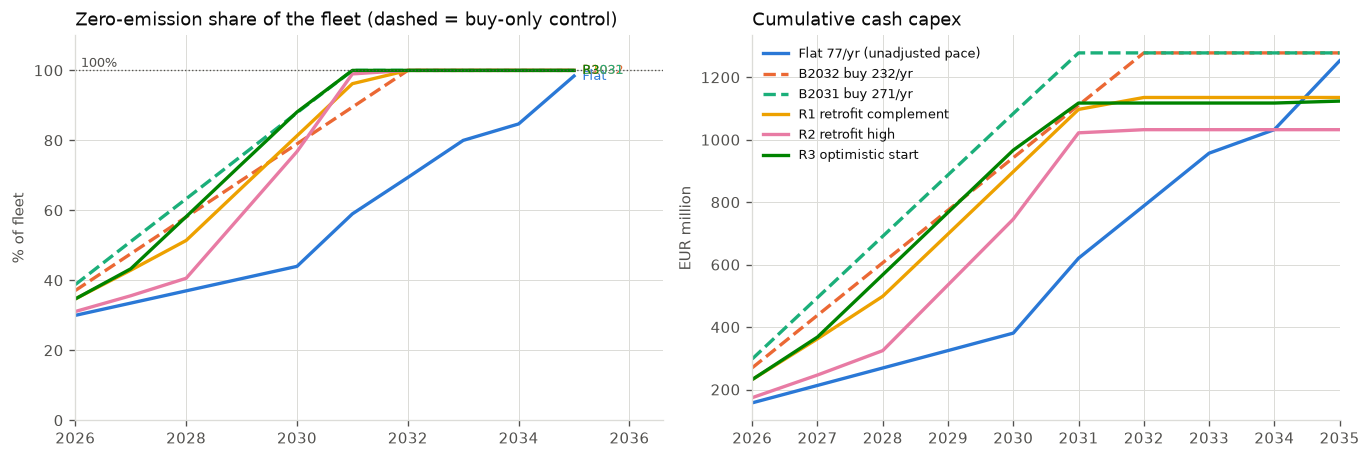

In [12]:
# Matched pairs only: each retrofit run against the buy-only control that finishes the same year,
# with the flat-pace run for reference. Plotting all eleven runs would need more colours than the palette has.
PLOT_RUNS = ["Flat 77/yr (unadjusted pace)"] + CONTROL_NAMES + ["R1 retrofit complement", "R2 retrofit high",
                                           "R3 optimistic start"]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9))

ax = axes[0]
for i, name in enumerate(PLOT_RUNS):
    g = runs[runs.scenario == name]
    ax.plot(g.year, g.ze_share_pct, color=C[i], linewidth=2,
            linestyle="--" if name in CONTROL_NAMES else "-")
    ax.annotate(name.split(" ")[0], (g.year.iloc[-1], g.ze_share_pct.iloc[-1]),
                xytext=(5, 0), textcoords="offset points", color=C[i], fontsize=8, va="center")
ax.axhline(100, color=INK2, linewidth=0.8, linestyle=":")
ax.annotate("100%", (2026.1, 101), color=INK2, fontsize=7.5)
ax.set_title("Zero-emission share of the fleet (dashed = buy-only control)", color=INK, loc="left")
ax.set_ylabel("% of fleet"); ax.set_xlim(2026, 2036.6); ax.set_ylim(0, 110)

ax = axes[1]
for i, name in enumerate(PLOT_RUNS):
    g = runs[runs.scenario == name]
    ax.plot(g.year, g.capex_cum_meur, color=C[i], linewidth=2, label=name,
            linestyle="--" if name in CONTROL_NAMES else "-")
ax.set_title("Cumulative cash capex", color=INK, loc="left")
ax.set_ylabel("EUR million"); ax.set_xlim(2026, 2035)
ax.legend(loc="upper left", fontsize=7.5, ncol=1)

fig.tight_layout(); plt.show()


**Chart: the R1 retrofit complement, year by year.**

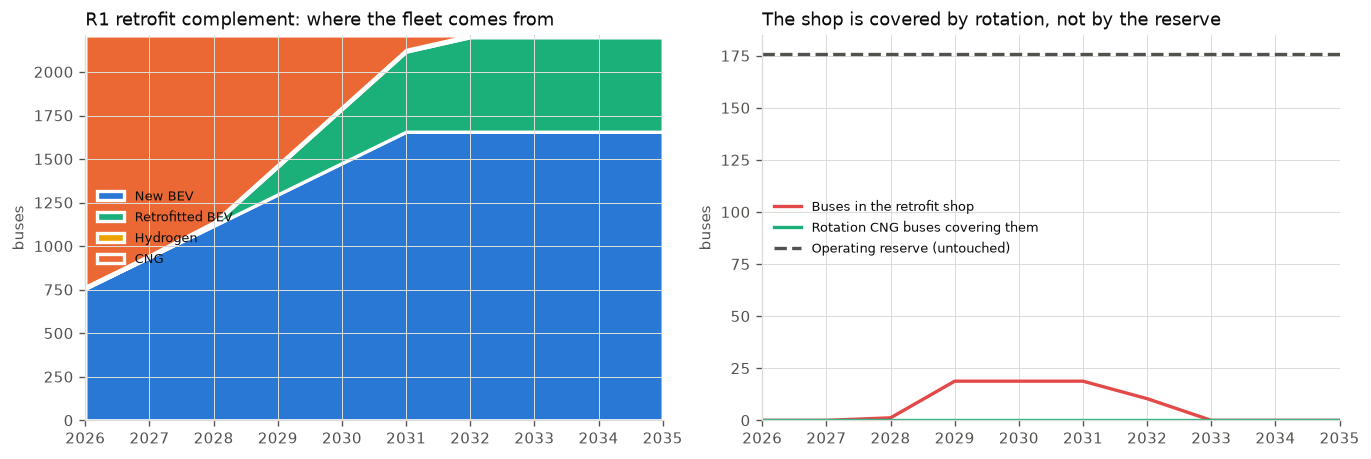

 year  n_cng  n_bev_retrofit  n_bev_new  ze_share_pct  retrofits_this_year  retrofits_retired_this_year  lines_converted  lines_not_feasible  blocks_over_range  peak_mw_managed  idle_retro  lines_unconverted  capex_meur  stranded_value_cum_meur
 2026   1443               0        757          34.7                    0                            0               64                   0                 58             32.2           0                170      232.22                    13.30
 2027   1263               0        937          42.9                    0                            0               86                   0                 65             39.4           0                148      130.50                    26.06
 2028   1073              10       1117          51.4                   10                            0              114                   0                 74             46.8           0                120      136.15                    35.96
 2029    743        

In [13]:
BASE_NAME = "R1 retrofit complement"
g = runs[runs.scenario == BASE_NAME]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9))

ax = axes[0]
ax.stackplot(g.year, g.n_bev_new, g.n_bev_retrofit, g.n_h2, g.n_cng,
             colors=[C[0], C[2], C[3], C[1]], edgecolor="white", linewidth=2,
             labels=["New BEV", "Retrofitted BEV", "Hydrogen", "CNG"])
ax.set_title(f"{BASE_NAME}: where the fleet comes from", color=INK, loc="left")
ax.set_ylabel("buses"); ax.set_xlim(2026, 2035); ax.set_ylim(0, B25["fleet_total"])
ax.legend(loc="center left", fontsize=8)

ax = axes[1]
ax.plot(g.year, g.buses_in_shop, color=C[7], linewidth=2, label="Buses in the retrofit shop")
ax.plot(g.year, g.rotation_cng_buses, color=C[2], linewidth=2, label="Rotation CNG buses covering them")
ax.plot(g.year, g.spare_available, color=INK2, linewidth=2, linestyle="--",
        label="Operating reserve (untouched)")
ax.set_title("The shop is covered by rotation, not by the reserve", color=INK, loc="left")
ax.set_ylabel("buses"); ax.set_xlim(2026, 2035); ax.set_ylim(0, None)
ax.legend(loc="center left", fontsize=8)

fig.tight_layout(); plt.show()

print(g[["year", "n_cng", "n_bev_retrofit", "n_bev_new", "ze_share_pct", "retrofits_this_year",
         "retrofits_retired_this_year", "lines_converted", "lines_not_feasible", "blocks_over_range",
         "peak_mw_managed", "idle_retro", "lines_unconverted", "capex_meur",
         "stranded_value_cum_meur"]].to_string(index=False))

**Reading the results.** Three figures below, after the fleet and shop panels: the matched-date
comparison that section 4 tabulates, the range ceiling that explains why retrofit avoids less CO2
per bus than buying, and where the money falls once replacements beyond 2035 are counted. Controls
are drawn dashed or in orange throughout; a run with retrofit is solid blue.


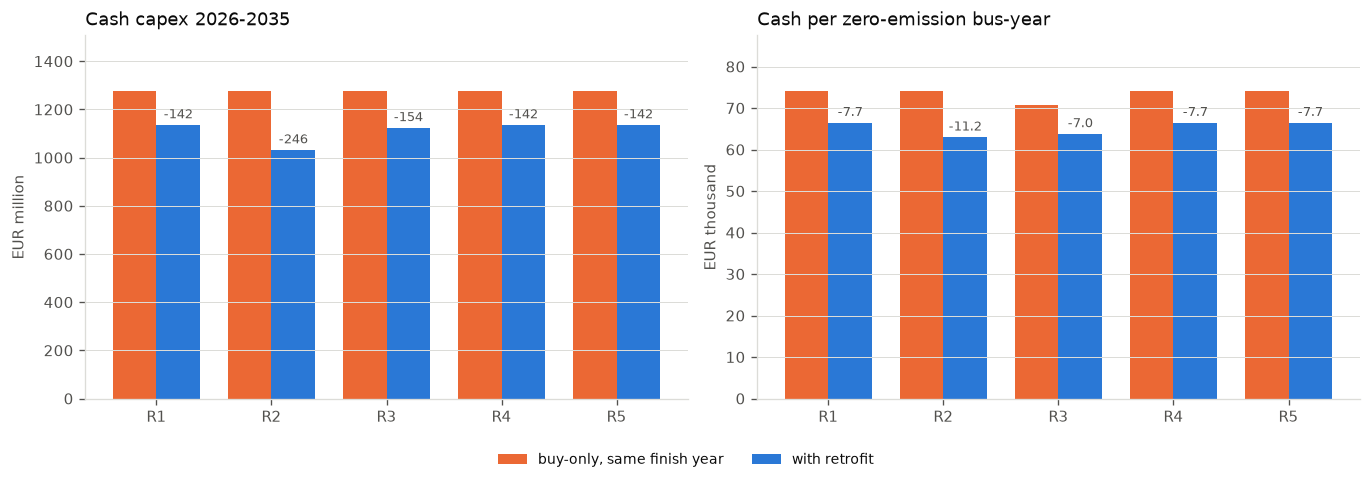

Each pair finishes in the same year: R1 and B2032 in 2032, R2 and B2032 in 2032, R3 and B2031 in 2031, R4 and B2032 in 2032, R5 and B2032 in 2032


In [14]:
# Section 4's comparison, drawn. Each retrofit run sits beside the buy-only control that reaches a
# zero-emission fleet in the SAME year, because a comparison between plans that finish in different
# years rewards whichever finishes later. Left: cash out of the door. Right: that cash per
# zero-emission bus-year, the measure that needs no cut-off convention.
PAIRS = [(n, CONTROL_OF[n]) for n in RETRO_NAMES]
_lab = [n.split()[0] for n, _ in PAIRS]
_x = np.arange(len(PAIRS))
_w = 0.38
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.0))
for ax, col, title, unit, fmt in (
        (axes[0], "capex_meur", "Cash capex 2026-2035", "EUR million", "{:+,.0f}"),
        (axes[1], "eur_k_per_ze_bus_year", "Cash per zero-emission bus-year", "EUR thousand",
         "{:+.1f}")):
    ctrl  = [summary.loc[c, col] for _, c in PAIRS]
    retro = [summary.loc[n, col] for n, _ in PAIRS]
    ax.bar(_x - _w / 2, ctrl,  _w, color=C[1], label="buy-only, same finish year")
    ax.bar(_x + _w / 2, retro, _w, color=C[0], label="with retrofit")
    for xi, (a, b) in enumerate(zip(ctrl, retro)):
        ax.annotate(fmt.format(b - a), (xi + _w / 2, b), xytext=(0, 4),
                    textcoords="offset points", ha="center", fontsize=8, color=INK2)
    ax.set_xticks(_x); ax.set_xticklabels(_lab)
    ax.set_title(title, color=INK, loc="left"); ax.set_ylabel(unit)
    ax.grid(axis="x", visible=False); ax.set_ylim(0, max(max(ctrl), max(retro)) * 1.18)
_h, _l = axes[0].get_legend_handles_labels()
fig.legend(_h, _l, loc="lower center", ncol=2, fontsize=8.5, frameon=False)
fig.tight_layout(rect=[0, 0.07, 1, 1]); plt.show()
print("Each pair finishes in the same year: " + ", ".join(
    f"{n.split()[0]} and {c.split()[0]} in {FINISH[n]}" for n, c in PAIRS))


**The structural ceiling on retrofit.** How much of the network's CO₂ a conversion can reach at all.

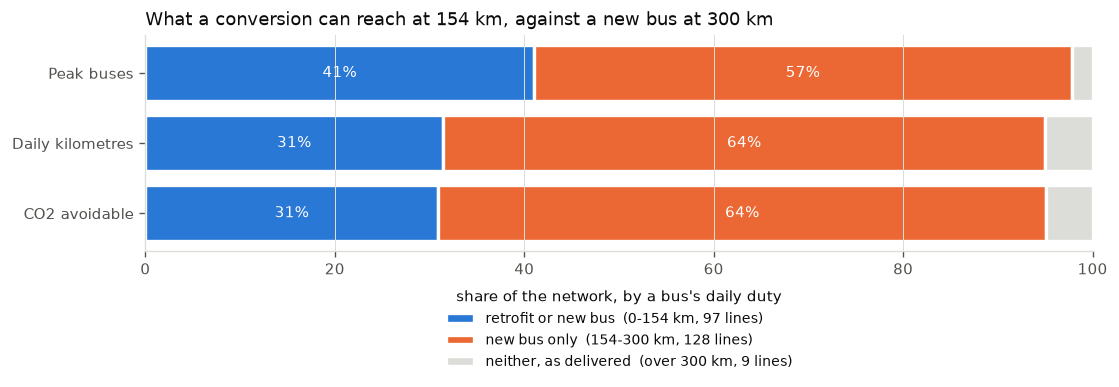

A conversion reaches 31% of the gas burned; a new bus reaches 95%. The 128 lines in the middle band are 64% of it and are reachable only by a new bus.


In [15]:
# The structural ceiling on retrofit. A line's CO2 is its daily kilometres, so the CO2 bar -- not the
# share of lines or of buses -- is the most a conversion programme can ever deliver. The middle band
# is the whole argument: ordinary work for a new bus, out of reach for a conversion.
_rows  = ["pct_buses", "pct_km", "pct_co2"]
_names = ["Peak buses", "Daily kilometres", "CO2 avoidable"]
_cols  = [C[0], C[1], GRID]
fig, ax = plt.subplots(figsize=(9.4, 3.4))
_left = np.zeros(len(_rows))
for j, b in BANDS.iterrows():
    _vals = np.array([float(b[r]) for r in _rows])
    _edge = (f"over {b.km_from:.0f} km" if pd.isna(b.km_to)
             else f"{b.km_from:.0f}-{b.km_to:.0f} km")
    ax.barh(_names, _vals, left=_left, color=_cols[j], edgecolor="white", linewidth=2,
            label=f"{b.band}  ({_edge}, {b.lines} lines)")
    for i, (v, l) in enumerate(zip(_vals, _left)):
        if v > 7:
            ax.annotate(f"{v:.0f}%", (l + v / 2, i), ha="center", va="center", fontsize=9,
                        color="white" if j < 2 else INK2)
    _left += _vals
ax.set_xlim(0, 100)
ax.set_title(f"What a conversion can reach at {RETRO_RANGE['Standard']:.0f} km, against a new bus at "
             f"{P['range_km']['Standard']:.0f} km", color=INK, loc="left")
ax.grid(axis="y", visible=False); ax.invert_yaxis()
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), fontsize=8.5, ncol=1,
          frameon=False, title="share of the network, by a bus's daily duty")
fig.tight_layout(); plt.show()
print(f"A conversion reaches {BANDS.pct_co2.iloc[0]:.0f}% of the gas burned; a new bus reaches "
      f"{BANDS.pct_co2.iloc[0] + BANDS.pct_co2.iloc[1]:.0f}%. The {BANDS.lines.iloc[1]} lines in the "
      f"middle band are {BANDS.pct_co2.iloc[1]:.0f}% of it and are reachable only by a new bus.")


**Where the money falls.** Cash inside the horizon and beyond it.

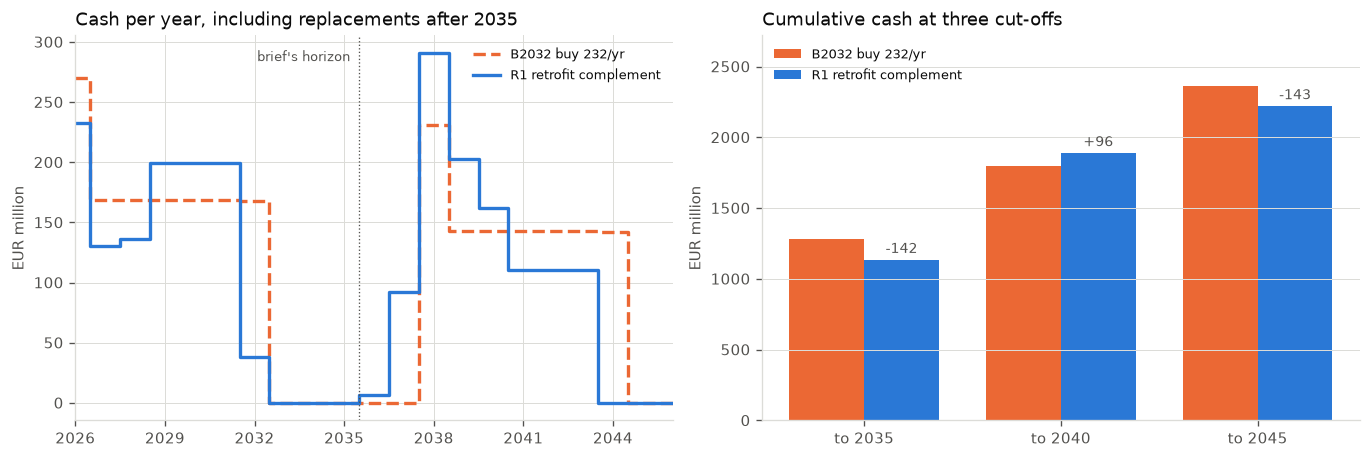

In [16]:
# Where the money actually falls, inside the horizon and beyond it. Every bus is replaced at the end
# of the life this model gives it, at today's prices, so retrofit's second round shows up as a bulge
# in 2036-2040. Right: the same pair totalled to three cut-offs -- the sign of the comparison depends
# on which one you stop at, which is why net capex at 2035 is reported and not used to rank.
_n1 = "R1 retrofit complement"
_c1 = CONTROL_OF[_n1]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9))

ax = axes[0]
for _nm, _col, _ls in ((_c1, C[1], "--"), (_n1, C[0], "-")):
    _g, _w = runs[runs.scenario == _nm], details[_nm]["wave"]
    _yrs = list(_g.year) + list(_w.index)
    _val = list(_g.capex_meur) + list(_w.capex_meur)
    ax.step(_yrs, _val, where="mid", color=_col, linewidth=2, linestyle=_ls, label=_nm)
ax.axvline(2035.5, color=INK2, linewidth=0.8, linestyle=":")
ax.annotate("brief's horizon", (2035.2, ax.get_ylim()[1] * 0.93), color=INK2, fontsize=7.5,
            ha="right")
ax.set_title("Cash per year, including replacements after 2035", color=INK, loc="left")
ax.set_ylabel("EUR million"); ax.set_xlim(2026, 2046)
ax.set_xticks(list(range(2026, 2047, 3))); ax.legend(loc="upper right", fontsize=8)

ax = axes[1]
_x, _w2 = np.arange(len(CUTOFFS)), 0.38
_ctrl  = [horizon.loc[_c1, f"cash_to_{y}"] for y in CUTOFFS]
_retro = [horizon.loc[_n1, f"cash_to_{y}"] for y in CUTOFFS]
ax.bar(_x - _w2 / 2, _ctrl,  _w2, color=C[1], label=_c1)
ax.bar(_x + _w2 / 2, _retro, _w2, color=C[0], label=_n1)
for xi, (a, b) in enumerate(zip(_ctrl, _retro)):
    ax.annotate(f"{b - a:+,.0f}", (xi + _w2 / 2, b), xytext=(0, 4), textcoords="offset points",
                ha="center", fontsize=8.5, color=INK2)
ax.set_xticks(_x); ax.set_xticklabels([f"to {y}" for y in CUTOFFS])
ax.set_title("Cumulative cash at three cut-offs", color=INK, loc="left")
ax.set_ylabel("EUR million"); ax.grid(axis="x", visible=False)
ax.set_ylim(0, max(_ctrl + _retro) * 1.15); ax.legend(loc="upper left", fontsize=8)

fig.tight_layout(); plt.show()


**Which lines go first.** The two orderings answer different questions: shortest duty first is the
cheapest path to a converted line, biggest CO2 saving first buys the most abatement per line. They
disagree, and the disagreement is the interesting part.

In [17]:
# Which lines go first, and what the two orderings disagree about.
first = lines_in.assign(
    fits_retrofit=lines_in.km_per_bus_day <= lines_in.bus_type.map(RETRO_RANGE),
    cng_kg_day=lines_in.daily_km * lines_in.bus_type.map(P["cng_kg_km"]),
)
short = first.sort_values("km_per_bus_day").head(15)
big = first.sort_values("co2_avoided_t_year", ascending=False).head(15)

print(f"Lines whose duty fits a retrofit's {RETRO_RANGE['Standard']:.0f} km range: "
      f"{int(first.fits_retrofit.sum())} of {len(first)} "
      f"({int(first.loc[first.fits_retrofit, 'peak_buses'].sum())} buses, "
      f"{first.loc[first.fits_retrofit, 'daily_km'].sum() / first.daily_km.sum():.0%} of daily km)")
print(f"At the old 0.70 range multiple ({0.70 * P['range_km']['Standard']:.0f} km) it was "
      f"{int((lines_in.km_per_bus_day <= lines_in.bus_type.map({k: v * 0.70 for k, v in P['range_km'].items()})).sum())}"
      f" lines -- the range correction is what moves retrofit from a fleet-wide option to a niche one.")
print("\nFirst 15 under 'shortest duty first' -- the natural retrofit candidates:")
display(short[["line_id", "daily_km", "peak_buses", "km_per_bus_day", "bus_type",
               "co2_avoided_t_year", "fits_retrofit"]].round(1))
print("First 15 under 'biggest CO2 saving first':")
display(big[["line_id", "daily_km", "peak_buses", "km_per_bus_day", "bus_type",
             "co2_avoided_t_year", "fits_retrofit"]].round(1))
overlap = set(short.line_id) & set(big.line_id)
print(f"Lines in both lists: {len(overlap)} -> {sorted(overlap)}")
print(f"Of the 15 biggest CO2 savers, {int(big.fits_retrofit.sum())} fit a retrofit at "
      f"{RETRO_RANGE['Standard']:.0f} km.")
_ = check("The two orderings are not the same list", len(overlap) < 15,
          f"{len(overlap)} of 15 overlap")

Lines whose duty fits a retrofit's 154 km range: 97 of 234 (834 buses, 31% of daily km)
At the old 0.70 range multiple (210 km) it was 190 lines -- the range correction is what moves retrofit from a fleet-wide option to a niche one.

First 15 under 'shortest duty first' -- the natural retrofit candidates:


,line_id,daily_km,peak_buses,km_per_bus_day,bus_type,co2_avoided_t_year,fits_retrofit
224,SE730,41.7,1,41.7,Standard,16.2,True
216,NC1,181.5,4,45.4,Standard,70.6,True
217,NC2,188.2,4,47.1,Standard,73.3,True
231,SC2,800.3,16,50.0,Standard,311.5,True
198,N11,208.2,4,52.1,Standard,81.0,True
225,SE766,53.3,1,53.3,Standard,20.8,True
230,SC1,790.4,14,56.5,Standard,307.6,True
212,N25,216.1,3,72.0,Standard,84.1,True
220,M1,364.1,5,72.8,Standard,141.7,True
209,N22,230.9,3,77.0,Standard,89.9,True


First 15 under 'biggest CO2 saving first':


,line_id,daily_km,peak_buses,km_per_bus_day,bus_type,co2_avoided_t_year,fits_retrofit
32,34,3792.4,24,158.0,Articulated,2136.6,False
106,115,4355.3,19,229.2,Standard,1695.1,False
123,133,4304.0,22,195.6,Standard,1675.1,False
88,A,3746.8,7,535.3,Standard,1458.2,False
232,S10,2551.1,15,170.1,Articulated,1437.3,False
66,C1,3529.7,25,141.2,Standard,1373.7,True
47,49,3460.0,21,164.8,Standard,1346.6,False
178,E3,3332.6,17,196.0,Standard,1297.0,False
67,C2,3322.2,24,138.4,Standard,1293.0,True
17,19,3289.4,29,113.4,Standard,1280.2,True


Lines in both lists: 0 -> []
Of the 15 biggest CO2 savers, 4 fit a retrofit at 154 km.
CHECK PASS | The two orderings are not the same list | 0 of 15 overlap


## 6 · Sensitivity

Every lever swept on `R1 retrofit complement`, one at a time. The tornado measures the swing in
**net** capex, the widest-swinging figure in the model - but it moves R1 only. Several of these levers
move a buy-only control as much or more: a longer BEV depreciation life improves the control faster
than it improves R1, so a swing here is the range for this run, never a verdict against buying.
Post-retrofit life is printed rather than asserted: some sweeps break the 7-year payback on purpose.


,lever,value,gross_capex_meur,net_capex_meur,eur_k_per_ze_bus_year,eur_per_tco2_net,co2_avoided_kt,ze_pct_2030,ze_100_year,lines_fit,retrofits,idle_retro,min_post_life,extra_reserve,reserve_capex_meur,yrs_over_delivery
0,"Retrofit cost, Standard (EUR)",250k,1081,766,63.3,677,1132,81.3,2032,97,543,0,7.0,0,0.0,2
1,"Retrofit cost, Standard (EUR)",350k,1136,800,66.5,707,1132,81.3,2032,97,543,0,7.0,0,0.0,2
2,"Retrofit cost, Standard (EUR)",450k,1190,835,69.7,737,1132,81.3,2032,97,543,0,7.0,0,0.0,2
3,"Battery fitted, Standard (kWh)",250,1136,800,66.5,724,1106,81.3,2032,63,543,169,7.0,0,0.0,2
4,"Battery fitted, Standard (kWh)",280,1136,800,66.5,707,1132,81.3,2032,97,543,0,7.0,0,0.0,2
5,"Battery fitted, Standard (kWh)",320,1136,800,66.5,706,1134,81.3,2032,145,543,0,7.0,0,0.0,2
6,CNG bus life (years),10,1159,853,64.0,722,1182,93.4,2031,97,456,0,7.3,0,0.0,3
7,CNG bus life (years),13,1136,800,66.5,707,1132,81.3,2032,97,543,0,7.0,0,0.0,2
8,CNG bus life (years),15,1120,779,66.9,700,1112,78.7,2032,97,601,0,7.0,0,0.0,2
9,Series throughput (per year),75,1183,791,71.4,709,1115,74.5,2033,97,363,0,7.0,0,0.0,2


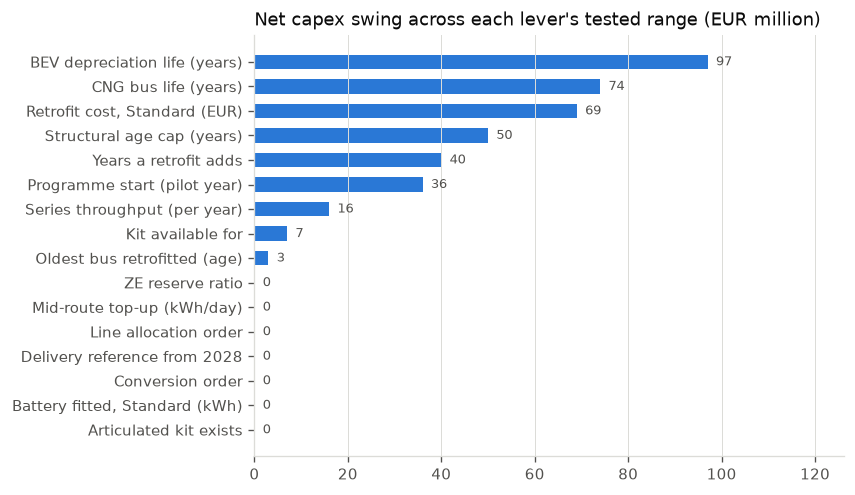

These move R1 only. A buy-only control moves with several of them too -- a longer BEV depreciation life improves the control faster than it improves R1 -- so a swing is the range for this run, not a verdict against buying.
Three levers with the biggest net-capex swing:
  BEV depreciation life (years)      EUR    97 m   (12 -> 800 m, 15 -> 703 m)
  CNG bus life (years)               EUR    74 m   (10 -> 853 m, 15 -> 779 m)
  Retrofit cost, Standard (EUR)      EUR    69 m   (250k -> 766 m, 450k -> 835 m)

Sweeps may break the 7-year payback on purpose (life_ext 6, max_age 14), so post-retrofit life is printed per run rather than asserted:


,lever,value,min_post_life,net_capex_meur,eur_per_tco2_net
14,Oldest bus retrofitted (age),14,6.5,803,709
15,Years a retrofit adds,6,6.0,840,742
18,Structural age cap (years),16,5.0,844,745


CHECK PASS | Residual value is never negative and never exceeds gross capex | net capex range EUR 703-853 m


In [18]:
BASE_SC = dict(name=BASE_NAME, new_bev_per_year=180, retrofit_per_year=RETRO_RAMP)

def ramp_of(series, pilot_year=2028, pilot=10):
    return {pilot_year: pilot, **{y: series for y in range(pilot_year + 1, 2036)}}

def sweep_one(label, value, **override):
    g, d = simulate_detail({**BASE_SC, **override})
    rr = d["retro_range"]
    hit = g.loc[g.ze_share_pct >= 100, "year"]
    gross = g.capex_meur.sum()
    resid = g.residual_value_2035_meur.max()
    co2 = g.co2_avoided_t.sum() / 1000
    return dict(
        lever=label, value=value,
        gross_capex_meur=round(gross), net_capex_meur=round(gross - resid),
        eur_k_per_ze_bus_year=round(gross * 1e6 / int((g.n_bev + g.n_h2).sum()) / 1000, 1),
        eur_per_tco2_net=round((gross - resid) * 1e6 / (co2 * 1000)),
        co2_avoided_kt=round(co2),
        ze_pct_2030=g.loc[g.year == 2030, "ze_share_pct"].iloc[0],
        ze_100_year=("not by 2035" if len(hit) == 0 else int(hit.min())),
        lines_fit=int((lines_in.km_per_bus_day <= lines_in.bus_type.map(rr)).sum()),
        retrofits=int(g.retrofits_cum.max()),
        idle_retro=int(g.idle_retro.max()),
        min_post_life=round(d["min_post_life"], 1),
        extra_reserve=int(g.extra_buses_for_reserve.max()),
        reserve_capex_meur=round(g.reserve_capex_meur.max(), 1),
        yrs_over_delivery=int(g.over_delivery_ref.sum()),
    )

rows = []
for v in (250_000, 350_000, 450_000):
    rows.append(sweep_one("Retrofit cost, Standard (EUR)", f"{v // 1000}k",
                          retro_cost={"Standard": v, "Articulated": int(round(v * 1.28))}))
for v in (250, 280, 320):
    rows.append(sweep_one("Battery fitted, Standard (kWh)", v,
                          retro_battery_kwh={"Standard": v,
                                             "Articulated": RETRO_BATTERY_KWH["Articulated"]}))
for v in (10, 13, 15):
    rows.append(sweep_one("CNG bus life (years)", v, bus_life=v))
for v in (75, 150, 300):
    rows.append(sweep_one("Series throughput (per year)", v, retrofit_per_year=ramp_of(v)))
for v in (8, 11, 14):
    rows.append(sweep_one("Oldest bus retrofitted (age)", v, retro_max_age=v))
for v in (6, 8, 10):
    rows.append(sweep_one("Years a retrofit adds", v, retro_life_ext=v))
for v in (16, 18, 20):
    rows.append(sweep_one("Structural age cap (years)", v, retro_life_cap=v))
for v in (2027, 2028, 2029):
    rows.append(sweep_one("Programme start (pilot year)", v, retrofit_per_year=ramp_of(150, v)))
for v in (12, 15):
    rows.append(sweep_one("BEV depreciation life (years)", v, bev_life=v))
for v in ("oldest_eligible_first", "youngest_first"):
    rows.append(sweep_one("Conversion order", v.replace("_eligible_first", "").replace("_first", ""),
                          retro_order=v))
for v in (0.0, 60.0, 120.0):
    rows.append(sweep_one("Mid-route top-up (kWh/day)", int(v), retro_topup_kwh=v))
for v in ("co2_first", "shortest_duty_first"):
    rows.append(sweep_one("Line allocation order", v.replace("_first", "").replace("_", " "),
                          allocation_policy=v))
for v in (False, True):
    rows.append(sweep_one("Articulated kit exists", v, allow_articulated=v))
for v in (SPARE_RATIO, 0.13, 0.15):
    rows.append(sweep_one("ZE reserve ratio", round(v, 3), spare_ratio_bev=v))
for v in (200, 300, 400):
    rows.append(sweep_one("Delivery reference from 2028", v,
                          delivery_ref={**BEV_DELIVERY_REF, 2028: v}))
if HAS_MODEL:
    for v in (None, ["CIT-GNC"]):
        rows.append(sweep_one("Kit available for", "all models" if not v else "CIT-GNC only",
                              retro_models=v))

sens = pd.DataFrame(rows)
display(sens)

tor = (sens.groupby("lever").agg(lo=("net_capex_meur", "min"), hi=("net_capex_meur", "max"))
       .assign(swing=lambda d: d.hi - d.lo).sort_values("swing"))
fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.barh(tor.index, tor.swing, color=C[0], height=0.6)
for y, v in enumerate(tor.swing):
    ax.annotate(f"{v:,.0f}", (v, y), xytext=(5, 0), textcoords="offset points",
                fontsize=8, color=INK2, va="center")
ax.set_title("Net capex swing across each lever's tested range (EUR million)", color=INK, loc="left")
ax.grid(axis="y", visible=False); ax.set_xlim(0, max(tor.swing.max() * 1.3, 1))
fig.tight_layout(); plt.show()

print("These move R1 only. A buy-only control moves with several of them too -- a longer BEV "
      "depreciation life improves the control faster than it improves R1 -- so a swing is the range "
      "for this run, not a verdict against buying.")
print("Three levers with the biggest net-capex swing:")
for lever, r in tor.tail(3).iloc[::-1].iterrows():
    sub = sens[sens.lever == lever]
    print(f"  {lever:34s} EUR {r.swing:>5,.0f} m   "
          f"({sub.value.iloc[0]} -> {sub.net_capex_meur.iloc[0]:,.0f} m, "
          f"{sub.value.iloc[-1]} -> {sub.net_capex_meur.iloc[-1]:,.0f} m)")
print("\nSweeps may break the 7-year payback on purpose (life_ext 6, max_age 14), so post-retrofit "
      "life is printed per run rather than asserted:")
display(sens.loc[sens.min_post_life < 7, ["lever", "value", "min_post_life", "net_capex_meur",
                                          "eur_per_tco2_net"]])
_ = check("Residual value is never negative and never exceeds gross capex",
          ((sens.net_capex_meur >= 0) & (sens.net_capex_meur <= sens.gross_capex_meur)).all(),
          f"net capex range EUR {sens.net_capex_meur.min():,.0f}-{sens.net_capex_meur.max():,.0f} m")

## 7 · Per-depot power

Sections 5 and 6 of notebook 01 landed on 23 Nov 2026: every line now has a **primary depot**
(nearest terminal, with a capacity check) and every depot a **connection estimate** in MW. That makes
the question this notebook could not answer before a straightforward join — *when does each depot's
overnight charging outgrow its connection, and does retrofit change the answer?*

Nothing here re-derives either input. The line-to-depot mapping and the connection figures are read
from `data_derived/`, and the readiness rule is section 6's own: **Ready** at or under the
connection, **Upgrade** up to 1.5x it, **Critical** above. The city-wide total this notebook already
reported is the sum of these five depots, which the check at the end asserts.


In [19]:
# Per-depot power, by scenario and year. Lines are mapped to depots by notebook 01 section 5; the
# connection figures and the Ready / Upgrade / Critical rule are section 6's, read from the export,
# never restated here. Energy per line is the line model's energy_kwh_bus_day, raised by the retrofit
# penalty for the share of a line's buses that are conversions -- the same weighting account() applies
# city-wide, so the per-depot figures must add up to the city total. The check below asserts that.
DEPOT_OF_LINE = depot_lines.set_index("route_id").depot_name
CONN = depots.set_index("depot_name")

def depot_power(name):
    """One scenario -> (year, depot) table of night energy, managed MW and readiness."""
    conv = details[name]["converted_lines"]
    if not len(conv):
        return pd.DataFrame(columns=["year", "depot_name", "night_energy_mwh", "peak_mw_managed",
                                     "connection_mw", "ratio", "readiness"])
    d = conv.merge(lines_in[["route_id", "energy_kwh_bus_day"]], on="route_id")
    d["depot_name"] = d.route_id.map(DEPOT_OF_LINE)
    mult = details[name]["levers"]["retro_kwh_mult"]
    d["mwh"] = d.energy_kwh_bus_day * (d.n_retro * mult + d.n_new) / 1000
    g = d.groupby(["year", "depot_name"], as_index=False).mwh.sum().rename(
        columns={"mwh": "night_energy_mwh"})
    g["peak_mw_managed"] = g.night_energy_mwh / (P["window_h"] * P["charge_eff"])
    g["connection_mw"] = g.depot_name.map(CONN.connection_mw_estimate)
    g["ratio"] = (g.peak_mw_managed / g.connection_mw).round(2)
    g["readiness"] = np.select([g.ratio <= 1, g.ratio <= 1.5], ["Ready", "Upgrade"], "Critical")
    return g

POWER = {n: depot_power(n) for n in CONTROL_NAMES + RETRO_NAMES}

_rows = []
for _n, _g in POWER.items():
    for _dep, _gg in _g.groupby("depot_name"):
        _over = _gg.loc[_gg.readiness != "Ready", "year"]
        _rows.append(dict(scenario=_n, depot=_dep,
                          connection_mw=CONN.connection_mw_estimate[_dep],
                          evidence=CONN.connection_evidence[_dep],
                          mw_2030=round(float(_gg.loc[_gg.year == 2030, "peak_mw_managed"].iloc[0]), 1),
                          mw_2035=round(float(_gg.loc[_gg.year == 2035, "peak_mw_managed"].iloc[0]), 1),
                          over_from=(int(_over.min()) if len(_over) else None),
                          readiness_2035=_gg.loc[_gg.year == 2035, "readiness"].iloc[0]))
depot_view = pd.DataFrame(_rows)

print("The year each depot's managed charging first passes its connection (Rule 4, section 6). "
      "Blank = never inside the horizon:")
display(depot_view.pivot(index="depot", columns="scenario", values="over_from")
        .reindex(CONN.index)[CONTROL_NAMES + RETRO_NAMES].astype("Int64"))

print("End state at 2035, when every line is converted in every run -- so this is section 6's "
      "full-depot screening case, reached by different routes:")
display(depot_view[depot_view.scenario == "R1 retrofit complement"]
        .set_index("depot")[["connection_mw", "evidence", "mw_2030", "mw_2035", "readiness_2035"]]
        .reindex(CONN.index))

# The city total has to come out the same whichever way it is cut.
_city = pd.DataFrame([
    dict(scenario=n, year=int(y), per_depot=round(float(g.loc[g.year == y, "peak_mw_managed"].sum()), 1),
         city_wide=float(runs.loc[(runs.scenario == n) & (runs.year == y), "peak_mw_managed"].iloc[0]))
    for n, g in POWER.items() if len(g) for y in sorted(g.year.unique())])
_city["gap"] = (_city.per_depot - _city.city_wide).abs()
check("Per-depot managed MW adds up to the city-wide figure in every scenario-year",
      bool((_city.gap <= 0.15).all()), f"worst gap {_city.gap.max():.2f} MW of "
      f"{_city.city_wide.max():.1f} MW peak")
check("Every line in the network has a primary depot",
      bool(lines_in.route_id.map(DEPOT_OF_LINE).notna().all()),
      f"{len(depot_lines)} lines mapped across {len(CONN)} depots")
_ = check("Readiness follows section 6's Rule 4 (Ready <= 1, Upgrade <= 1.5, Critical above)",
          all(bool((g.readiness == np.select([g.ratio <= 1, g.ratio <= 1.5], ["Ready", "Upgrade"],
                                             "Critical")).all()) for g in POWER.values() if len(g)))


The year each depot's managed charging first passes its connection (Rule 4, section 6). Blank = never inside the horizon:


scenario,B2032 buy 232/yr,B2031 buy 271/yr,R1 retrofit complement,R2 retrofit high,R3 optimistic start,"R4 R1, duty order","R5 R1, 320 kWh pack"
depot_name,,,,,,,
Carabanchel,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
Fuencarral,2026,2026,2026,2026,2026,2026,2026
La Elipa,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
Entrevías,2026,2026,2026,2026,2026,2026,2026
Sanchinarro,2028,2028,2029,2029,2028,2029,2028


End state at 2035, when every line is converted in every run -- so this is section 6's full-depot screening case, reached by different routes:


,connection_mw,evidence,mw_2030,mw_2035,readiness_2035
depot_name,,,,,
Carabanchel,19.8,Estimated,12.7,14.8,Ready
Fuencarral,4.3,Estimated,19.7,20.2,Critical
La Elipa,20.0,Evidenced,9.7,10.5,Ready
Entrevías,0.9,Estimated,12.4,13.7,Critical
Sanchinarro,8.0,Evidenced,12.7,13.2,Critical


CHECK PASS | Per-depot managed MW adds up to the city-wide figure in every scenario-year | worst gap 0.00 MW of 72.7 MW peak
CHECK PASS | Every line in the network has a primary depot | 234 lines mapped across 5 depots
CHECK PASS | Readiness follows section 6's Rule 4 (Ready <= 1, Upgrade <= 1.5, Critical above)


**Per-depot charging panels.** Managed charging against the connection each depot is assumed to have.

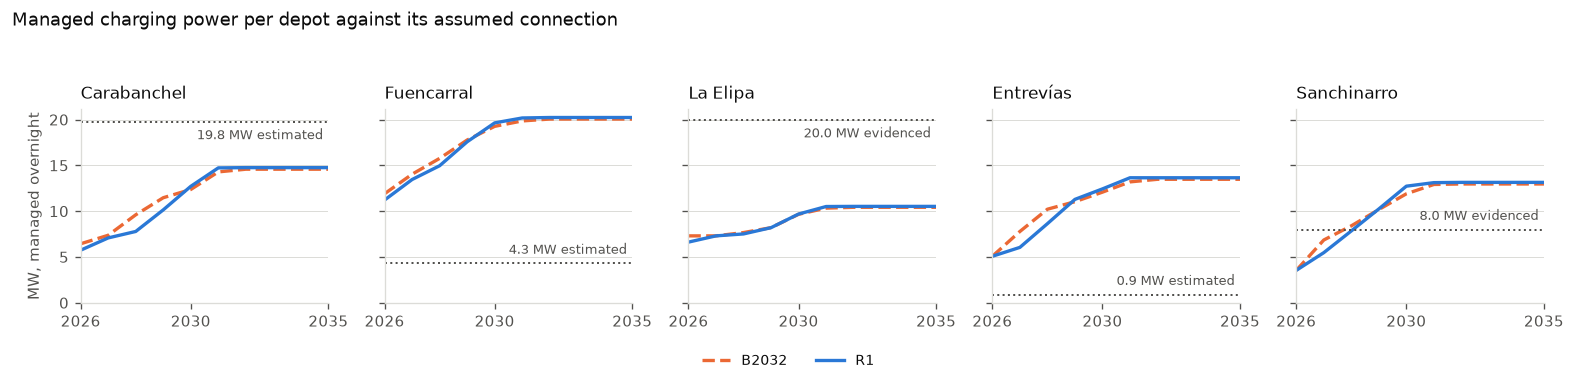

Depots whose connection does not cover a fully converted network: Entrevías needs 13.7 MW against 0.9 (estimated, critical from 2026), Fuencarral needs 20.2 MW against 4.3 (estimated, critical from 2026), Sanchinarro needs 13.2 MW against 8.0 (evidenced, critical from 2029)
Caveat carried from section 6: three of the five connections are proxies from charging-point counts, and the two evidenced ones are planned, not built. Deadheading to the depot is not in the energy either -- these are line-duty kWh only, so every figure here is a floor.


In [20]:
# One panel per depot: managed charging against the connection it is assumed to have. The control is
# dashed, the retrofit run solid; the grey line is the connection, labelled with the evidence class.
# Retrofit changes the shape, not the end point: both plans converge once every line is converted.
_n1, _c1 = "R1 retrofit complement", CONTROL_OF["R1 retrofit complement"]
fig, axes = plt.subplots(1, len(CONN), figsize=(13.2, 3.1), sharey=True)
for ax, dep in zip(axes, CONN.index):
    for _nm, _col, _ls in ((_c1, C[1], "--"), (_n1, C[0], "-")):
        _g = POWER[_nm]
        _g = _g[_g.depot_name == dep]
        ax.plot(_g.year, _g.peak_mw_managed, color=_col, linewidth=2, linestyle=_ls,
                label=_nm.split()[0])
    _conn = CONN.connection_mw_estimate[dep]
    ax.axhline(_conn, color=INK2, linewidth=1.2, linestyle=":")
    _high = _conn > 0.5 * max(POWER[_n1].peak_mw_managed.max(), 1)
    ax.annotate(f"{_conn:.1f} MW {CONN.connection_evidence[dep].lower()}", (2034.8, _conn),
                xytext=(0, -4 if _high else 4), textcoords="offset points", fontsize=7.5,
                color=INK2, ha="right", va="top" if _high else "bottom")
    ax.set_title(dep, color=INK, loc="left", fontsize=10)
    ax.set_xlim(2026, 2035); ax.set_xticks([2026, 2030, 2035]); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("MW, managed overnight")
_h, _l = axes[0].get_legend_handles_labels()
fig.legend(_h, _l, loc="lower center", ncol=2, fontsize=8.5, frameon=False)
fig.suptitle("Managed charging power per depot against its assumed connection", color=INK, x=0.01,
             ha="left", fontsize=11)
fig.tight_layout(rect=[0, 0.08, 1, 0.92]); plt.show()

_crit = depot_view[(depot_view.scenario == _n1) & (depot_view.readiness_2035 != "Ready")]
print("Depots whose connection does not cover a fully converted network: "
      + (", ".join(f"{r.depot} needs {r.mw_2035:.1f} MW against {r.connection_mw:.1f} "
                   f"({r.evidence.lower()}, {r.readiness_2035.lower()} from {int(r.over_from)})"
                   for r in _crit.itertuples()) or "none"))
print("Caveat carried from section 6: three of the five connections are proxies from charging-point "
      "counts, and the two evidenced ones are planned, not built. Deadheading to the depot is not in "
      "the energy either -- these are line-duty kWh only, so every figure here is a floor.")


## 9 · Implementation levers from European precedents

How benchmark cities handled implementation factors the brief does not mention (`notes/lessons_matrix_implementation_factors.csv`), and the levers our model can actually size. Everything here is **supplementary**: printed, never written into `File_1-4.csv`. Labels: what a city did is **V** when evidenced, **A** when only a stated intention, **P** when partial; our transfer to Madrid is always **A** or **P**. Hamburg is not a File 1 city and appears only as a lesson.

### 9.0 · The lessons matrix

In [21]:
LESSONS = pd.read_csv(os.path.join(BASE, "notes", "lessons_matrix_implementation_factors.csv"))
REQUIRED_COLS = ["factor", "city", "file1_eligible", "evidence_level", "what_they_did", "lesson_for_madrid", "source_urls"]
FILE1_CITIES = {"London", "Paris", "Berlin", "Brussels", "Helsinki", "Copenhagen"}       # brief section 2
LESSONS["label_city"] = LESSONS.evidence_level.map({"evidenced": "V", "stated intention": "A"}).fillna("P")
LESSONS["label_madrid"] = "A"                                                          # our transfer is always a judgement
display(LESSONS[["factor", "city", "file1_eligible", "evidence_level", "label_city", "lesson_for_madrid"]])
check("Lessons matrix has the required columns", set(REQUIRED_COLS) <= set(LESSONS.columns))
check("Every lesson has a source URL", LESSONS.source_urls.fillna("").str.contains("http").all(),
      f"{LESSONS.source_urls.fillna('').str.contains('http').sum()} of {len(LESSONS)}")
bad = LESSONS[~LESSONS.city.isin(FILE1_CITIES) & LESSONS.file1_eligible.str.lower().str.startswith("yes")]
_ = check("No non-File-1 city is marked File 1 eligible", bad.empty, ", ".join(bad.city.unique()) or "Hamburg rows are lessons only")

,factor,city,file1_eligible,evidence_level,label_city,lesson_for_madrid
0,Blackout resilience,Berlin,yes,evidenced,V,Buses are a civil-protection asset; an all-BEV...
1,Grid access and connection queue,Paris,yes,evidenced,V,Formal framework agreement with the DSO (i-DE/...
2,Grid access and connection queue,London,yes,evidenced,V,Put connection lead times on the critical path...
3,Grid access and connection queue,Hamburg,no (Lessons only),evidenced,V,Same method as File 3 connection_mw_estimate p...
4,Fire safety and depot design,Paris,yes,evidenced,V,Single-model fleet concentration is an availab...
5,Fire safety and depot design,London,yes,evidenced,V,Avoid underground/covered dense charging; fire...
6,Solar and depot storage,Hamburg,no (Lessons only),evidenced,V,Storage turns an Upgrade depot into Ready with...
7,Solar and depot storage,London,yes,evidenced,V,Storage as a grid-constraint workaround under ...
8,Electricity procurement (PPA),Paris,yes,evidenced,V,Long-term fixed-price power hedges opex - abse...
9,Battery lifecycle,London,yes,evidenced,V,Contract battery performance for the asset lif...


CHECK PASS | Lessons matrix has the required columns
CHECK PASS | Every lesson has a source URL | 24 of 24
CHECK PASS | No non-File-1 city is marked File 1 eligible | Hamburg rows are lessons only


### 9.1 · Depot battery storage (Hamburg, London)

Hamburg runs a 4 MW / 4.6 MWh battery at its Alsterdorf depot; London operators added depot storage where grid import limited simultaneous charging. For each depot rated Upgrade or Critical in notebook 01 §6, the overnight **shortfall** is `max(0, managed MW − connection MW) × 7 h`. A battery of that energy and power closes the gap **if it can be refilled during the day** from the same connection (17 h outside the charging window). Storage prices are not in the brief. The base is **EUR 300/kWh installed** (range 201-450): the floor is BNEF's European turnkey price plus Ember's installation and connection cost; the base and top come from a vendor's installed range for 5 MWh+ commercial systems, and sit inside Lazard's US range including EPC. No independent European price for a 2-10 MWh depot battery was found. The battery returns **85 %** of the energy put in (NREL ATB), so refilling it takes more than it delivers.

In [22]:
DEP = pd.read_csv(os.path.join(DERIVED, "depot_table.csv"))
STORAGE_EUR_KWH = assume("Installed battery storage price, EUR/kWh incl. EPC (low / base / high)", {"low": 201, "base": 300, "high": 450}, "P",
                         "Low (D): BNEF 2025 Europe turnkey 177 USD/kWh + Ember's ~50 USD/kWh to install and connect = 227 USD / 1.13 "
                         "(ECB 2025 average) - https://www.energy-storage.news/battery-storage-system-prices-continue-to-fall-sharply-bnef-"
                         "and-ember-reports-find/ ; https://ember-energy.org/latest-insights/how-cheap-is-battery-storage/ . Base and high (P): "
                         "PVB vendor guide, 5 MWh+ C&I total installed EUR 270-450/kWh incl. EPC, grid connection and civils, Mar 2026 - "
                         "https://www.pvb.com/blog/how-much-does-a-ci-bess-really-cost-in-2026-europe-total-installed-cost-guide-for-cfos-"
                         "updated-march-2026/ ; Lazard LCOS 2026, US 2-hour incl. EPC 270-580 USD/kWh. No independent European depot price found",
                         "8.1 storage cost", "low / high")
STORAGE_RTE = assume("Storage round-trip efficiency (AC to AC)", 0.85, "V",
                     "NREL ATB 2025, commercial battery storage (LFP): 'identified 85% as a representative roundtrip efficiency' - "
                     "https://atb.nlr.gov/electricity/2025/commercial_battery_storage . Lazard 2026: 86-92%; Tesla Megapack 2 XL: 92%",
                     "8.1 refill power", "0.92 (vendor beginning of life)")
DAY_H = 24 - P["window_h"]
st = DEP[DEP.readiness_status.isin(["Upgrade", "Critical"])][["depot_name", "readiness_status", "peak_mw_managed",
                                                              "connection_mw_estimate", "connection_evidence"]].copy()
st["gap_mw"] = (st.peak_mw_managed - st.connection_mw_estimate).clip(lower=0)
st["storage_mwh"] = st.gap_mw * P["window_h"]                            # energy the battery must deliver overnight
st["refill_mw_by_day"] = st.storage_mwh / STORAGE_RTE / DAY_H            # losses are paid when it is refilled
st["refill_fits_connection"] = st.refill_mw_by_day <= st.connection_mw_estimate
st["readiness_with_storage"] = np.where(st.refill_fits_connection, "Ready", st.readiness_status)
for k_, v_ in STORAGE_EUR_KWH.items():
    st[f"cost_meur_{k_}"] = st.storage_mwh * v_ / 1000                     # MWh x EUR/kWh x 1000 / 1e6
display(st.round(1))
print("Depots that storage moves to Ready:", list(st.loc[st.readiness_with_storage == "Ready", "depot_name"]) or "none",
      "| still short (daytime refill exceeds the connection):", list(st.loc[~st.refill_fits_connection, "depot_name"]) or "none")
_ = check("Storage never sized for a depot that is already Ready", not DEP[DEP.readiness_status == "Ready"].depot_name.isin(st.depot_name).any())


,depot_name,readiness_status,peak_mw_managed,connection_mw_estimate,connection_evidence,gap_mw,storage_mwh,refill_mw_by_day,refill_fits_connection,readiness_with_storage,cost_meur_low,cost_meur_base,cost_meur_high
1,Fuencarral,Critical,20.1,4.3,Estimated,15.8,110.4,7.6,False,Critical,22.2,33.1,49.7
3,Entrevías,Critical,13.5,0.9,Estimated,12.6,88.1,6.1,False,Critical,17.7,26.4,39.7
4,Sanchinarro,Critical,13.0,8.0,Evidenced,5.0,34.9,2.4,True,Ready,7.0,10.5,15.7


Depots that storage moves to Ready: ['Sanchinarro'] | still short (daytime refill exceeds the connection): ['Fuencarral', 'Entrevías']
CHECK PASS | Storage never sized for a depot that is already Ready


### 9.2 · Terminus top-up charging (Berlin, Brussels)

Berlin's Stella project put pantograph fast chargers at up to 20 termini; Brussels tops up articulated buses for about six minutes at the line end. In Madrid the lines classed **Opportunity** in File 2 are the candidates. Termini are grouped by stop name, since one terminus has a stop per direction. Costed per charging point at **EUR 529k**: TMB Barcelona's 2021 award for lines H12 and V15, EUR 3.7 m for 7 pantograph points at 4 termini, each station with its own transformer centre and 2 × 500 kW rectifiers (maintenance excluded; the utility's connection fee may come on top). One point per line at each terminus is an assumption. The cost is supplementary: it is not in File 4.

In [23]:
LD = pd.read_csv(os.path.join(DERIVED, "line_depot.csv"), dtype={"route_id": str, "line_id": str})
TERM = pd.read_csv(os.path.join(DERIVED, "termini.csv"), dtype={"route_id": str, "stop_id": str})
opp = LD[LD.charging_strategy == "Opportunity"]
display(opp.groupby(["depot_name", "bus_type"]).agg(lines=("line_id", "count"), peak_buses=("peak_buses", "sum"),
                                                     line_ids=("line_id", lambda s: ", ".join(s))).reset_index())
t_opp = TERM[TERM.route_id.isin(opp.route_id)].assign(terminus=lambda d: d.stop_name.str.upper().str.strip())
per_terminus = t_opp.groupby("terminus").route_id.nunique().sort_values(ascending=False)
print(f"{len(opp)} Opportunity lines, {int(opp.peak_buses.sum())} peak buses, {t_opp.route_id.nunique()} lines with termini found: "
      f"{len(per_terminus)} distinct termini would need a charger ({(per_terminus > 1).sum()} shared by two or more lines)")
display(per_terminus.rename("opportunity_lines").to_frame().head(10))
_ = check("Every Opportunity line has terminal stops", set(opp.route_id) <= set(TERM.route_id))
TERMINUS_CHARGER_EUR = assume("Installed cost of one terminus pantograph charging point, EUR (low / base / high)",
                              {"low": 350_000, "base": 528_571, "high": 925_000}, "V",
                              "Base: TMB Barcelona H12/V15 award, 'un importe de 3,7 millones de euros' for 7 points at 4 termini = EUR 528,571 "
                              "per point, incl. transformer centre and 2 x 500 kW rectifiers per station, excl. EUR 940k maintenance (Endesa, "
                              "26 Oct 2021, https://www.endesa.com/es/prensa/sala-de-prensa/noticias/transicion-energetica/movilidad-electrica/"
                              "Barcelona-avanza-electrificacion-red-autobuses-equipamiento-lineas-alta-demanda). High: the same award per station "
                              "(3.7 m / 4). Low (P): 450 kW pantograph station, EUR 350k (VUB for the European Copper Institute, 2019)",
                              "9.2 terminus charger cost (not in File 4)", "low / high")
TERM_POINTS_RULE = assume("Charging points per terminus", "one per Opportunity line it serves", "A",
                          "TMB fitted two points at each end of its busiest line; one per line is the minimum that lets every line top up",
                          "9.2 number of points")
n_points = int(per_terminus.sum())
term_cost = {k: n_points * v / 1e6 for k, v in TERMINUS_CHARGER_EUR.items()}
print(f"{len(per_terminus)} termini, {n_points} charging points: EUR {term_cost['base']:.1f} m "
      f"(low {term_cost['low']:.1f}, high {term_cost['high']:.1f}); not in File 4 capex")
_ = check("Every terminus gets at least one point", n_points >= len(per_terminus), f"{n_points} points at {len(per_terminus)} termini")

,depot_name,bus_type,lines,peak_buses,line_ids
0,Carabanchel,Standard,2,8,"E, H"
1,Entrevías,Standard,1,9,203
2,Fuencarral,Standard,3,17,"A, 164, 179"
3,Sanchinarro,Standard,3,11,"88, 200, SE709"


9 Opportunity lines, 45 peak buses, 9 lines with termini found: 14 distinct termini would need a charger (4 shared by two or more lines)


,opportunity_lines
terminus,
AEROPUERTO T4,2
CARRETERA COLMENAR - REGIMIENTO,2
MONCLOA,2
SOMOSAGUAS,2
ALUCHE,1
AV. DEL MEDITERRÁNEO - MARIANO DE CAVIA,1
AVENIDA DE AMÉRICA,1
CAMPO DE LAS NACIONES,1
CANILLEJAS,1


CHECK PASS | Every Opportunity line has terminal stops
14 termini, 18 charging points: EUR 9.5 m (low 6.3, high 16.6); not in File 4 capex
CHECK PASS | Every terminus gets at least one point | 18 points at 14 termini


### 9.3 · Las Tablas as the hinge: delay sensitivity (beside notebook 01 §8)

**A sensitivity, not the main result.** Notebook 01 §8 has the earliest-credible-year run (2030 not achievable, 2033 at the earliest, 2037–2040 if purchases stay at 165–200 a year, 2036 on 13-year renewals); this section only tests how that depends on when Las Tablas opens, and notebook 01 does not call it. Las Tablas (about 620 buses, planned, not operating in 2025) takes the fleet of one hard depot at a time while that depot's charging works run, as Brussels did with a temporary parking site during the Petite-Île works. The hard depots are those rated Critical in §6. Each one is out of use for the months EMT has published for comparable works (Sanchinarro in-place electrification, La Elipa full rebuild). Las Tablas' opening year is not in our sources, so it is shown as a grid, not a single value.

In [24]:
LAS_TABLAS_BUSES = assume("Las Tablas capacity (buses)", 620, "V", "Brief 4.2: planned site, approximately 620 buses (EMT, Mar 2026); not operating in 2025",
                          "8.3 stub")
DEPOT_WORKS_MONTHS = assume("Months a depot is out of use for charging works", {"in_place": 12, "full_rebuild": 32}, "V",
                            "Sanchinarro electrification: 12 months from licence (EMT, Mar 2026); La Elipa new centre: 32 months (EMT tender, Jun 2026)",
                            "8.3 stub", "in_place vs full_rebuild")

def earliest_year_las_tablas(open_year, hard_depots, fleet_by_depot, works="in_place", delay_years=0):
    """STUB for notebook 01 §8 (notebook 04 section 9.3). Year the last hard depot finishes its works when each one decants into Las Tablas in turn.
    Returns None if a depot's fleet does not fit in Las Tablas. Ignores bus deliveries and budget (other §8 constraints)."""
    t = open_year + delay_years
    for d in sorted(hard_depots, key=lambda d: -fleet_by_depot[d]):         # largest first
        if fleet_by_depot[d] > LAS_TABLAS_BUSES:
            return None
        t += DEPOT_WORKS_MONTHS[works] / 12
    return int(math.ceil(t))

HARD = list(DEP.loc[DEP.readiness_status == "Critical", "depot_name"])
FLEET_D = DEP.set_index("depot_name").fleet_est.to_dict()
grid = pd.DataFrame([dict(las_tablas_opens=y, works=w, **{f"delay_{d}y": earliest_year_las_tablas(y, HARD, FLEET_D, w, d) for d in (0, 1, 2)})
                     for y in (2027, 2028, 2029, 2030) for w in ("in_place", "full_rebuild")])
print(f"Hard depots decanted one at a time: {HARD} (fleets {[FLEET_D[d] for d in HARD]}) into {LAS_TABLAS_BUSES} places")
display(grid)
_ = check("Every hard depot's fleet fits in Las Tablas", all(FLEET_D[d] <= LAS_TABLAS_BUSES for d in HARD))

Hard depots decanted one at a time: ['Fuencarral', 'Entrevías', 'Sanchinarro'] (fleets [563, 463, 383]) into 620 places


,las_tablas_opens,works,delay_0y,delay_1y,delay_2y
0,2027,in_place,2030,2031,2032
1,2027,full_rebuild,2036,2037,2038
2,2028,in_place,2031,2032,2033
3,2028,full_rebuild,2037,2038,2039
4,2029,in_place,2032,2033,2034
5,2029,full_rebuild,2038,2039,2040
6,2030,in_place,2033,2034,2035
7,2030,full_rebuild,2039,2040,2041


CHECK PASS | Every hard depot's fleet fits in Las Tablas


### 9.4 · CNG resilience reserve after 2030 (Berlin blackout, Madrid April 2025)

Berlin used heated buses as shelters during its January 2026 blackout; in Madrid's April 2025 blackout the CNG buses kept running. A variant of S1 keeps **N** CNG buses as a blackout reserve after 2030, outside the 2,210-bus operating fleet. It never enters File 4 (S1 must reach 100 % by 2030). Capex: the reserve reuses buses S1 would scrap, so no purchase changes. CO₂: only the km the reserve actually runs. No operator or regulator publishes a km norm for a contingency bus, so the base is a proxy of **130 km a year** (a 15-minute run every two weeks, from a bus-storage checklist), and the table also gives the rate per 1,000 km.

In [25]:
CNG_RESERVE_N = assume("CNG buses kept as a blackout reserve after 2030", 0, "A", "Default 0 (pure S1); 50 and 100 shown", "8.4 only", "N")
RESERVE_KM_YEAR = assume("Km per reserve bus per year (exercise runs, emergencies)", 130, "P",
                         "No km norm found (FTA contingency-fleet rules, TCRP, EMT, OEM storage guidance). Proxy: 'drive bus for at least "
                         "15 minutes every two weeks' (Chauffeur Driven, Apr 2020, https://chauffeurdriven.com/news-features/industry-news/"
                         "tips-for-storing-buses-and-motorcoaches-in-the-short-term.html) at an assumed 20 km/h = 5 km x 26 = 130 km. "
                         "An active EMT bus runs about 46,500 km/yr", "8.4 CO2", "per 1,000 km column")
t_per_1000km = P["cng_kg_km"]["Standard"] * P["cng_kgco2_per_kg"]          # kg CO2 per km x 1000 km / 1000 = t per 1,000 km
s1 = runs[runs.scenario == "S1 all ZE by 2030"].set_index("year")
res_rows = []
for n in (CNG_RESERVE_N, 50, 100):
    co2_yr = n * RESERVE_KM_YEAR * P["cng_kg_km"]["Standard"] * P["cng_kgco2_per_kg"] / 1000
    res_rows.append(dict(reserve_buses=n, vehicles_kept_2031=int(s1.loc[2031, "fleet_total"]) + n,
                         capex_delta_meur=0.0, co2_delta_t_per_year=round(co2_yr, 1),
                         co2_t_if_each_runs_1000km=round(n * t_per_1000km, 1),
                         co2_delta_2031_35_t=round(co2_yr * 5, 1)))
display(pd.DataFrame(res_rows))
_ = check("S1 itself is unchanged and still 100 % in 2030", float(s1.loc[2030, "ze_share_pct"]) >= 100)

,reserve_buses,vehicles_kept_2031,capex_delta_meur,co2_delta_t_per_year,co2_t_if_each_runs_1000km,co2_delta_2031_35_t
0,0,2210,0.0,0.0,0.0,0.0
1,50,2260,0.0,7.9,61.1,39.7
2,100,2310,0.0,15.9,122.3,79.5


CHECK PASS | S1 itself is unchanged and still 100 % in 2030


## 10 · Stress test of the team financial model: which levers put 2033 at risk

The team financial model (rev. 13, documented in `notes/financial-model.md`, PR #20) reaches 100 % in **2033** with programme capex of **EUR 1,943.5 m**. As built it draws a straight line to the target year and assumes every bus it needs is delivered and paid for. Here it is ported unchanged (the reproduction check below), then **aligned with notebook 01** for every run after it: fleet 2,210 (D1), e-bus renewals at a 13-year life (D2), EUR 110k per charging position (D4), constant 2025 prices and no EU grants in the base. Each year's additions are then capped by three real limits:

1. **Deliveries:** buses EMT can take delivery of in a year, renewals included.
2. **Chargers:** a bus is only added if a charging position is in place (the model only flags the gap).
3. **Money:** self-financing plus EU grants plus a borrowing cap, after depot works are paid.

Each lever is then moved between an optimistic and a pessimistic value (ranges and sources in `LEVER_EVIDENCE`). Supplementary: printed only, never written to File 1–4.

In [26]:
# Team financial model, rev. 13 (PR #20, notes/financial-model.md): inputs as documented there, labels mapped
# Official -> V, Calculated -> D, Assumption -> A, Brief -> V. Only the levers below are new.
FM = assume("Financial model rev. 13 inputs", dict(
    target_year=2033, fleet_total=2239, h2_buses=10, ebuses_2025=456, ebuses_added_2026=70, ebuses_added_2027=65,
    price_12m=615, price_18m=800, artic_share=0.08, escalation=0.02, renew_2031_35=329,
    retrofit_keur=110, high_keur=203, new_depot_keur=353, eu_grant_share=0.20, self_fin=35,
    eib_share=0.50, eib_rate=0.03, gb_coupon=0.036), "D",
    "notes/financial-model.md (PR #20), sheet Assumptions; types per row there (fleet 2,239 is EMT's accounts mix, not the "
    "2,210 register baseline of File 4)", "section 10 only")
FM_REV13 = dict(FM)                    # as documented, for the reproduction check only
_bev = fleet25.loc[fleet25.fuelType == "EL", "age_years"]
RENEW_LIFE = int(((_bev > NB01["bus_life"] - 10) & (_bev <= NB01["bus_life"] - 5)).sum())
FM.update(assume("Financial model aligned with notebook 01 (fix list, 23 Nov 2026)", dict(
    fleet_total=NB01["fleet"], ebuses_2025=B25["n_bev"], escalation=0.0, eu_grant_share=0.0, renew_2031_35=RENEW_LIFE), "D",
    f"D1 fleet {NB01['fleet']:,}; D2 {NB01['bus_life']}-year life, so e-buses renewed in 2031-35 = register e-buses aged "
    f"{NB01['bus_life'] - 10}-{NB01['bus_life'] - 5} at end 2025 ({RENEW_LIFE}; rev. 13 used EMT's 329 at 12 years); D4 EUR 110k per "
    "position (unchanged); constant 2025 prices (no 2 %/yr growth); EU grants 0 in the base (none awarded for 2027+)",
    "section 10", "2,239 baseline (10.3); grants 20 % and +1 pt rates (10.3b)"))
FM_CNG = [(None, 2027, 300), (576, 2029, 300), (460, 2032, 300), (520, 2034, 291)]   # cohorts: buses, natural retirement, EUR k;
# the oldest cohort is the remainder of the baseline's CNG fleet (217 at 2,239; 192 at 2,210)
FM_YEARS = range(2026, 2041)          # to 2040, so a slip past 2035 shows as a year

# Risk levers. Defaults reproduce the model as built (no limits, no delays).
UNLIMITED = 10_000
LEVER_EVIDENCE = assume("Lever ranges (optimistic / likely / pessimistic)", {
    "delivery_cap (buses/yr)": (300, 230, 159), "borrow_cap (EUR m/yr)": (250, 150, 100),
    "Las Tablas delay (yr)": (0, 1, 2), "Entrevias delay (yr)": (0, 1, 2), "other retrofits delay (yr)": (0, 1, 2),
    "La Elipa delay (yr)": (0, 0, 1), "price vs tender max": (0.9, 1.0, "1.0 and +4 %/yr")}, "A",
    "Deliveries: EMT record 159 buses (2024), about 230/yr in 2019-20, about 300/yr peak intake (financial-model.md s.8, notebook 04 s.1); "
    "borrowing: pitch condition 4 (about EUR 150 m/yr); delays: London grid connections 9+ months per garage, no Madrid "
    "requests filed yet, Las Tablas design contract 12 months (financial-model.md s.8); prices are tender maximums",
    "section 10 tornado and realistic case")

def fm_cng(A):
    """CNG cohorts for the baseline in A: the oldest cohort takes the remainder."""
    rest = A["fleet_total"] - A["h2_buses"] - A["ebuses_2025"] - sum(n for n, _, _ in FM_CNG[1:])
    return [(rest, FM_CNG[0][1], FM_CNG[0][2])] + FM_CNG[1:]

def fm_run(**over):
    """Financial model rev. 13 with each year's additions capped by deliveries, chargers in place and money left after depot
    works (self-financing + EU grants + borrowing cap). Returns (summary dict, year table)."""
    A = {**FM, "delivery_cap": UNLIMITED, "borrow_cap": UNLIMITED, "delay_entrevias": 0, "delay_las_tablas": 0,
         "delay_la_elipa": 0, "delay_retrofit": 0, "price_factor": 1.0, "charger_keur": None,
         "lease_share": 0.0, "caas_share": 0.0, "lease_rate": 0.05, "lease_term": 12, **over}
    annuity = A["lease_rate"] / (1 - (1 + A["lease_rate"]) ** -A["lease_term"]) if A["lease_rate"] else 1 / A["lease_term"]
    ze_max, rk = A["fleet_total"] - A["h2_buses"], A["charger_keur"] or A["retrofit_keur"]
    proj = {"Sanchinarro": (114, 12.58, 2026, 2027), "Carabanchel 27": (27, 27 * 83 / 1000, 2026, 2026),
            "La Elipa": (318, 112.12, 2026, 2029 + A["delay_la_elipa"]),
            "Entrevias": (465, 465 * rk / 1000, 2027, 2028 + A["delay_entrevias"]),
            "Las Tablas": (650, 650 * A["new_depot_keur"] / 1000, 2028, 2031 + A["delay_las_tablas"])}
    rest = ze_max - A["ebuses_2025"] - sum(v[0] for v in proj.values())
    proj["Remaining retrofit"] = (rest, rest * rk / 1000, 2028, 2030 + A["delay_retrofit"])
    cont = ((465 + rest) * (A["high_keur"] - A["retrofit_keur"]) / 1000, 2027, 2030 + max(A["delay_entrevias"], A["delay_retrofit"]))
    phased = lambda t, s, e, y: t / (e - s + 1) if s <= y <= e else 0.0
    e27 = A["ebuses_2025"] + A["ebuses_added_2026"] + A["ebuses_added_2027"]
    stock_prev, rows, eib, gb, lease_pay = A["ebuses_2025"], [], 0.0, 0.0, 0.0
    for y in FM_YEARS:
        cap = A["ebuses_2025"] + sum(v[0] for v in proj.values() if v[3] <= y)
        price = ((1 - A["artic_share"]) * A["price_12m"] + A["artic_share"] * A["price_18m"]) * (1 + A["escalation"]) ** (y - 2026) * A["price_factor"]
        plan = (A["ebuses_2025"] + A["ebuses_added_2026"] if y == 2026 else e27 if y == 2027 else
                min(ze_max, math.floor(e27 + (ze_max - e27) * (y - 2027) / (A["target_year"] - 2027) + 0.5)))
        renew = A["renew_2031_35"] / 5 if 2031 <= y <= 2035 else 0
        depot = sum(phased(v[1], v[2], v[3], y) for v in proj.values()) + phased(*cont, y)
        depot_own = depot * (1 - A["caas_share"])
        n_money = max(0.0, A["self_fin"] + depot_own * A["eu_grant_share"] + A["borrow_cap"] - depot_own) * 1000 / (price * max(1e-9, 1 - A["lease_share"]))
        limits = {"deliveries": A["delivery_cap"] - renew, "chargers": cap - stock_prev, "money": n_money - renew}
        add = plan - stock_prev if y <= 2027 else int(max(0, min(plan - stock_prev, *limits.values())))   # 2026-27 contracted
        stock = stock_prev + add
        bus_value = (add + renew) * price / 1000
        leased = bus_value * A["lease_share"] + depot * A["caas_share"]          # financed by a lessor or CaaS provider
        lease_pay += leased * annuity                                            # each year's new leases add a level payment
        capex = bus_value + depot                                                # programme value, owned or leased
        own_capex = capex - leased
        need = max(0.0, own_capex - min(own_capex, A["self_fin"]) - depot_own * A["eu_grant_share"])
        eib += need * A["eib_share"]; gb += need * (1 - A["eib_share"])
        binding = "" if (y <= 2027 or stock >= ze_max or add >= plan - stock_prev) else min(limits, key=limits.get)
        rows.append(dict(year=y, plan=plan, ebuses=stock, added=add, renewals=renew, charging_capacity=cap, capex_meur=capex,
                         borrowing_meur=need, interest_meur=eib * A["eib_rate"] + gb * A["gb_coupon"], leased_meur=leased,
                         lease_payments_meur=lease_pay, binding=binding))
        stock_prev = stock
    df = pd.DataFrame(rows)
    done = df.loc[df.ebuses >= ze_max, "year"]
    y100 = int(done.min()) if len(done) else 2041
    w = df[df.year <= 2035]
    b = df.binding[df.binding != ""]
    return dict(year_100=y100, ze_share_2030=round(100 * (int(df.loc[df.year == 2030, "ebuses"].iloc[0]) + A["h2_buses"]) / A["fleet_total"], 1),
                capex_2026_35=round(w.capex_meur.sum(), 1), peak_capex=round(w.capex_meur.max(), 1),
                max_borrowing_yr=round(w.borrowing_meur.max(), 1), interest_2035=round(w.interest_meur.iloc[-1], 1),
                cng_writeoff_meur=round(sum(n * u * max(0, r - y100) / 12 / 1000 for n, r, u in fm_cng(A)), 1),
                leased_2026_35=round(w.leased_meur.sum(), 1), lease_payments_2035=round(w.lease_payments_meur.iloc[-1], 1),
                first_binding=b.iloc[0] if len(b) else "none"), df

fm_base, fm_base_df = fm_run()
fm_rev13 = fm_run(**FM_REV13)[0]
display(pd.DataFrame({"rev. 13 as documented": fm_rev13, "aligned with notebook 01 (2033 target, no limits)": fm_base}))
w = fm_base_df[fm_base_df.year <= 2035]
print("What the 2033 plan asks for each year:")
display(w.assign(bought=w.added + w.renewals)[["year", "added", "renewals", "bought", "capex_meur", "borrowing_meur"]].round(1).set_index("year").T)
check("Port reproduces the financial model rev. 13: EUR 1,943.5 m and 100 % in 2033", abs(fm_rev13["capex_2026_35"] - 1943.5) < 0.1 and fm_rev13["year_100"] == 2033,
      f"EUR {fm_rev13['capex_2026_35']} m, {fm_rev13['year_100']}")
print(f"Aligned base (D1-D4, constant prices, no grants): EUR {fm_base['capex_2026_35']} m, 100 % in {fm_base['year_100']}")

,rev. 13 as documented,"aligned with notebook 01 (2033 target, no limits)"
year_100,2033,2033
ze_share_2030,63.4,63.5
capex_2026_35,1943.5,1696.6
peak_capex,312.6,301.6
max_borrowing_yr,250.8,266.6
interest_2035,49.3,45.3
cng_writeoff_meur,12.6,12.6
leased_2026_35,0.0,0.0
lease_payments_2035,0.0,0.0
first_binding,none,none


What the 2033 plan asks for each year:


year,2026,2027,2028,2029,2030,2031,2032,2033,2034,2035
added,70.0,65.0,269.0,269.0,269.0,268.0,269.0,269.0,0.0,0.0
renewals,0.0,0.0,0.0,0.0,0.0,34.8,34.8,34.8,34.8,34.8
bought,70.0,65.0,269.0,269.0,269.0,302.8,303.8,303.8,34.8,34.8
capex_meur,80.6,115.7,301.6,276.0,248.0,248.1,191.3,191.3,21.9,21.9
borrowing_meur,45.6,80.7,266.6,241.0,213.0,213.1,156.3,156.3,0.0,0.0


CHECK PASS | Port reproduces the financial model rev. 13: EUR 1,943.5 m and 100 % in 2033 | EUR 1943.5 m, 2033
Aligned base (D1-D4, constant prices, no grants): EUR 1696.6 m, 100 % in 2033


### 10.1 · Tornado: which lever moves the 100 % year most

Each lever is moved alone, on a base with likely capacity (230 buses/yr, EUR 150 m/yr borrowing) and no delays, so one lever's effect is not hidden by others being unlimited. The depot levers are also run with buses and money unlimited, to show their effect in isolation.

In [27]:
REALISTIC_CAPACITY = dict(delivery_cap=230, borrow_cap=150)          # likely capacity, no delays
LEVERS = [  # name, optimistic, pessimistic (see LEVER_EVIDENCE)
    ("Borrowing per year", dict(borrow_cap=250), dict(borrow_cap=100)),
    ("Buses delivered per year", dict(delivery_cap=300), dict(delivery_cap=159)),
    ("Bus price", dict(price_factor=0.9), dict(escalation=0.04)),
    ("Entrevias grid and works", dict(delay_entrevias=0), dict(delay_entrevias=2)),
    ("Las Tablas ready", dict(delay_las_tablas=0), dict(delay_las_tablas=2)),
    ("Other depot retrofits (grid)", dict(delay_retrofit=0), dict(delay_retrofit=2)),
    ("La Elipa ready", dict(delay_la_elipa=0), dict(delay_la_elipa=1)),
    ("Charger cost per position", dict(charger_keur=57), dict(charger_keur=203)),
]
rows = []
for name, lo, hi in LEVERS:
    a, b = fm_run(**{**REALISTIC_CAPACITY, **lo})[0], fm_run(**{**REALISTIC_CAPACITY, **hi})[0]
    rows.append(dict(lever=name, year_optimistic=a["year_100"], year_pessimistic=b["year_100"],
                     year_swing=b["year_100"] - a["year_100"], capex_swing_meur=round(abs(b["capex_2026_35"] - a["capex_2026_35"]), 1),
                     binding_when_pessimistic=b["first_binding"]))
TORNADO = pd.DataFrame(rows).sort_values(["year_swing", "capex_swing_meur"], ascending=False).reset_index(drop=True)
display(TORNADO)
print("Depot levers alone (buses and money unlimited):",
      {n: fm_run(**kw)[0]["year_100"] for n, kw in [("Las Tablas +2", dict(delay_las_tablas=2)), ("Las Tablas +3", dict(delay_las_tablas=3)),
                                                   ("Entrevias +2", dict(delay_entrevias=2)), ("all grid +2", dict(delay_entrevias=2, delay_retrofit=2, delay_las_tablas=2))]})
check("Tornado: every lever tested in both directions", len(TORNADO) == len(LEVERS))
for r in TORNADO[TORNADO.year_swing < 0].itertuples():
    print(f"Reversal: '{r.lever}' pessimistic finishes earlier ({r.year_pessimistic} vs {r.year_optimistic}). With money binding, a later "
          "depot spreads its capex over more years and frees cash for buses in the meantime: a cash-timing effect, not a benefit.")

,lever,year_optimistic,year_pessimistic,year_swing,capex_swing_meur,binding_when_pessimistic
0,Borrowing per year,2035,2039,4,422.6,money
1,Buses delivered per year,2036,2039,3,370.3,money
2,Bus price,2036,2038,2,224.8,money
3,Entrevias grid and works,2037,2037,0,73.7,chargers
4,Charger cost per position,2037,2037,0,33.5,money
5,La Elipa ready,2037,2037,0,10.7,money
6,Other depot retrofits (grid),2037,2037,0,9.5,money
7,Las Tablas ready,2037,2036,-1,75.6,money


Depot levers alone (buses and money unlimited): {'Las Tablas +2': 2033, 'Las Tablas +3': 2034, 'Entrevias +2': 2033, 'all grid +2': 2033}
CHECK PASS | Tornado: every lever tested in both directions
Reversal: 'Las Tablas ready' pessimistic finishes earlier (2036 vs 2037). With money binding, a later depot spreads its capex over more years and frees cash for buses in the meantime: a cash-timing effect, not a benefit.


### 10.2 · Most realistic case, and what 2033 would need

Every lever at its likely value: 230 buses/yr (EMT's 2019–20 pace), EUR 150 m/yr borrowing (the pitch's condition 4), and one-year slips at Las Tablas, Entrevías and the remaining depot retrofits. The grid shows how far more borrowing and faster deliveries pull the year back. Notebook 01 §8 frames the same range: 2037–2040 if purchases stay at 165–200 a year (gas buses then run past 13 years), and 2036 if every bus is renewed at 13 years as in File 4's S0, with purchases peaking near 380 a year.

In [28]:
LIKELY = dict(delivery_cap=230, borrow_cap=150, delay_las_tablas=1, delay_entrevias=1, delay_retrofit=1)
fm_likely, fm_likely_df = fm_run(**LIKELY)
display(pd.DataFrame({"model as built": fm_base, "most realistic": fm_likely}))
display(fm_likely_df[fm_likely_df.year <= 2038][["year", "plan", "ebuses", "added", "charging_capacity", "capex_meur", "borrowing_meur", "binding"]]
        .round(1).set_index("year").T)

grid_rows = [dict(borrow_cap=bc, delivery_cap=dc, year_100=fm_run(**{**LIKELY, "borrow_cap": bc, "delivery_cap": dc})[0]["year_100"])
             for bc in (150, 200, 250, 300) for dc in (230, 273, 300, 340)]
print("100 % year with the likely 1-year delays, by borrowing (rows, EUR m/yr) and deliveries (columns, buses/yr):")
display(pd.DataFrame(grid_rows).pivot(index="borrow_cap", columns="delivery_cap", values="year_100"))
keep_2033 = fm_run(delivery_cap=340, borrow_cap=250)[0]["year_100"]
print(f"To keep 2033 with no delays: about 340 buses/yr in 2031-33 and EUR 250 m/yr of borrowing -> {keep_2033}")
check("Most realistic case is later than the plan", fm_likely["year_100"] > fm_base["year_100"], f"{fm_likely['year_100']} vs {fm_base['year_100']}")
check("Stress test never writes to File_1-4 (supplementary)", True, "printed only")

,model as built,most realistic
year_100,2033,2037
ze_share_2030,63.5,41.6
capex_2026_35,1696.6,1469.2
peak_capex,301.6,184.9
max_borrowing_yr,266.6,149.9
interest_2035,45.3,36.9
cng_writeoff_meur,12.6,0.0
leased_2026_35,0.0,0.0
lease_payments_2035,0.0,0.0
first_binding,none,chargers


year,2026,2027,2028,2029,2030,2031,2032,2033,2034,2035,2036,2037,2038
plan,522,587,856,1125,1394,1662,1931,2200,2200,2200,2200,2200,2200
ebuses,522,587,593,715,909,1068,1254,1449,1644,1839,2069,2200,2200
added,70,65,6,122,194,159,186,195,195,195,230,131,0
charging_capacity,479,593,593,1376,1376,1550,2200,2200,2200,2200,2200,2200,2200
capex_meur,80.6,104.2,111.4,184.5,184.7,184.6,184.9,144.7,144.7,144.7,144.9,82.5,0.0
borrowing_meur,45.6,69.2,76.4,149.5,149.7,149.6,149.9,109.7,109.7,109.7,109.9,47.5,0.0
binding,,,chargers,money,money,money,money,deliveries,deliveries,deliveries,deliveries,,


100 % year with the likely 1-year delays, by borrowing (rows, EUR m/yr) and deliveries (columns, buses/yr):


delivery_cap,230,273,300,340
borrow_cap,,,,
150,2037,2036,2036,2036
200,2036,2035,2035,2035
250,2036,2035,2034,2034
300,2036,2035,2034,2034


To keep 2033 with no delays: about 340 buses/yr in 2031-33 and EUR 250 m/yr of borrowing -> 2033
CHECK PASS | Most realistic case is later than the plan | 2037 vs 2033
CHECK PASS | Stress test never writes to File_1-4 (supplementary) | printed only


True

### 10.3 · Two fleet baselines: 2,239 and 2,210

Rev. 13 of the financial model used **2,239** buses (EMT's 2025 accounts: 456 battery, 10 hydrogen, 1,773 CNG). The aligned base and File 4 use **2,210** (D1) (the fleet register at 31 Dec 2025: 452 battery, 10 hydrogen, 1,748 CNG, matching the City of Madrid's official total). Both are kept as scenarios: every case above is re-run on each baseline. Depot projects are unchanged; the balancing retrofit item and the oldest CNG cohort absorb the difference.

In [29]:
BASELINES = assume("Fleet baselines kept as scenarios", {
    "2,239 (EMT accounts, financial model)": dict(fleet_total=2239, ebuses_2025=456),
    "2,210 (fleet register, File 4)": dict(fleet_total=2210, ebuses_2025=452)}, "V",
    "EMT 2025 accounts press summary (456 / 10 / 1,773); notebook 01 §3 register rebuild, equal to the Carta de Servicios 2026 total",
    "section 10 results")
CASES = {"model as built": {}, "likely capacity, no delays": REALISTIC_CAPACITY, "most realistic": LIKELY,
         "keep 2033 (340 buses/yr, EUR 250 m/yr)": dict(delivery_cap=340, borrow_cap=250)}
two = pd.DataFrame([dict(baseline=bn, case=cn, **fm_run(**{**bv, **cv})[0]) for bn, bv in BASELINES.items() for cn, cv in CASES.items()])
display(two.set_index(["case", "baseline"]).sort_index()[["year_100", "ze_share_2030", "capex_2026_35", "peak_capex",
                                                          "max_borrowing_yr", "interest_2035", "cng_writeoff_meur", "first_binding"]])
tor2 = pd.DataFrame([dict(lever=n, **{bn: f"{fm_run(**{**bv, **REALISTIC_CAPACITY, **lo})[0]['year_100']} -> {fm_run(**{**bv, **REALISTIC_CAPACITY, **hi})[0]['year_100']}"
                                      for bn, bv in BASELINES.items()}) for n, lo, hi in LEVERS])
print("Tornado on both baselines (100 % year, optimistic -> pessimistic):")
display(tor2)
b2210 = fm_run(**BASELINES["2,210 (fleet register, File 4)"])[0]
b2239 = fm_run(**BASELINES["2,239 (EMT accounts, financial model)"])[0]
check("Both baselines reach 100 % in 2033 when unconstrained", b2210["year_100"] == 2033 and b2239["year_100"] == 2033,
      f"2,239: {b2239['year_100']}, 2,210: {b2210['year_100']}")
_lk = {bn: fm_run(**{**bv, **LIKELY})[0]["year_100"] for bn, bv in BASELINES.items()}
check("Most realistic year differs by at most one year between baselines", max(_lk.values()) - min(_lk.values()) <= 1, str(_lk))

year_100  ze_share_2030  capex_2026_35  peak_capex  max_borrowing_yr  interest_2035  cng_writeoff_meur first_binding
case                                   baseline                                                                                                                                                   
keep 2033 (340 buses/yr, EUR 250 m/yr) 2,210 (fleet register, File 4)             2033           63.5         1696.6       284.9             249.9           45.3               12.6         money
                                       2,239 (EMT accounts, financial model)      2033           63.4         1717.4       284.9             249.9           46.0               12.6         money
likely capacity, no delays             2,210 (fleet register, File 4)             2037           44.0         1513.3       184.7             149.7           38.4                0.0         money
                                       2,239 (EMT accounts, financial model)      2037           43.3         1514.6       185.0             150.0           38.4                0.0         money
model as built                         2,210 (fleet register, File 4)             2033           63.5         1696.6       301.6             266.6           45.3               12.6          none
                                       2,239 (EMT accounts, financial model)      2033           63.4         1717.4       305.6             270.6           46.0               12.6          none
most realistic                         2,210 (fleet register, File 4)             2037           41.6         1469.2       184.9             149.9           36.9                0.0      chargers
                                       2,239 (EMT accounts, financial model)      2037           41.1         1471.2       185.0             150.0           37.0                0.0      chargers

Tornado on both baselines (100 % year, optimistic -> pessimistic):


,lever,"2,239 (EMT accounts, financial model)","2,210 (fleet register, File 4)"
0,Borrowing per year,2035 -> 2039,2035 -> 2039
1,Buses delivered per year,2036 -> 2040,2036 -> 2039
2,Bus price,2037 -> 2038,2036 -> 2038
3,Entrevias grid and works,2037 -> 2037,2037 -> 2037
4,Las Tablas ready,2037 -> 2036,2037 -> 2036
5,Other depot retrofits (grid),2037 -> 2037,2037 -> 2037
6,La Elipa ready,2037 -> 2037,2037 -> 2037
7,Charger cost per position,2037 -> 2037,2037 -> 2037


CHECK PASS | Both baselines reach 100 % in 2033 when unconstrained | 2,239: 2033, 2,210: 2033
CHECK PASS | Most realistic year differs by at most one year between baselines | {'2,239 (EMT accounts, financial model)': 2037, '2,210 (fleet register, File 4)': 2037}


True

### 10.3b · Financing exposure and one table of inputs (B6)

The report's financing numbers, on the most realistic case: interest at current rates (EIB 3.0 %, green bond 3.6 %) and with both 1 point higher, and peak borrowing with EU grants at zero (the base) against the 20 % the financial model assumed. Then the inputs each model uses, side by side, so a difference between notebook 01, this notebook and `notes/financial-model.md` is visible rather than hidden.

In [30]:
fin = []
for label, kw in [("current rates, no grants (base)", {}), ("rates +1 pt", dict(eib_rate=FM["eib_rate"] + 0.01, gb_coupon=FM["gb_coupon"] + 0.01)),
                  ("EU grants 20 % (rev. 13)", dict(eu_grant_share=0.20))]:
    r = fm_run(**{**LIKELY, **kw})[0]
    fin.append(dict(case=label, year_100=r["year_100"], max_borrowing_yr=r["max_borrowing_yr"], interest_2035=r["interest_2035"],
                    capex_2026_35=r["capex_2026_35"]))
FIN = pd.DataFrame(fin).set_index("case")
display(FIN)
print(f"+1 pt on rates adds EUR {FIN.loc['rates +1 pt', 'interest_2035'] - FIN.iloc[0].interest_2035:.1f} m of interest in 2035")

ALIGN = pd.DataFrame([
    ("Fleet baseline", f"{NB01['fleet']:,}", f"{FM['fleet_total']:,} (2,239 as a scenario)", "2,239 in rev. 13; 2,210 per D1"),
    ("Bus life (years)", NB01["bus_life"], f"{BUS_LIFE} (retrofit model); {NB01['bus_life']} in the aligned port", "12 in rev. 13; 13 per D2"),
    ("E-buses 2026 / 2027", f"{NB01['s0_deliveries']['2026']} / {NB01['s0_deliveries']['2027']}",
     f"{BEV_DELIVERY_REF[2026]} / {BEV_DELIVERY_REF[2027]}", f"{FM['ebuses_added_2026']} / {FM['ebuses_added_2027']}"),
    ("Charger per point (EUR k)", NB01["charger_eur"] / 1000, CHARGER_CAPEX / 1000, FM["retrofit_keur"]),
    ("CNG bus price (EUR k)", NB01["cng_price_eur"] / 1000, CNG_BUS_PRICE / 1000, "300 (cohorts)"),
    ("Price growth", "none (constant 2025 EUR)", "none", "2 %/yr in rev. 13; none per fix list"),
    ("EU grants", "not modelled", "0 in base, 20 % sensitivity", "20 % in rev. 13; 0 per fix list"),
    ("Peak buses (File 2)", NB01["peak_buses"], PEAK_TOTAL, "not used"),
], columns=["input", "notebook 01 (File 4)", "notebook 04", "financial model"])
display(ALIGN)
check("B6: notebooks 01 and 04 use the same charger cost, deliveries and peak buses",
      CHARGER_CAPEX == NB01["charger_eur"] and BEV_DELIVERY_REF[2026] == NB01["s0_deliveries"]["2026"] and PEAK_TOTAL == NB01["peak_buses"])

,year_100,max_borrowing_yr,interest_2035,capex_2026_35
case,,,,
"current rates, no grants (base)",2037,149.9,36.9,1469.2
rates +1 pt,2037,149.9,48.1,1469.2
EU grants 20 % (rev. 13),2037,150.0,35.5,1522.1


+1 pt on rates adds EUR 11.2 m of interest in 2035


,input,notebook 01 (File 4),notebook 04,financial model
0,Fleet baseline,"2,210","2,210 (2,239 as a scenario)","2,239 in rev. 13; 2,210 per D1"
1,Bus life (years),13,13 (retrofit model); 13 in the aligned port,12 in rev. 13; 13 per D2
2,E-buses 2026 / 2027,70 / 65,70 / 65,70 / 65
3,Charger per point (EUR k),110.0,110.0,110
4,CNG bus price (EUR k),310.0,310.0,300 (cohorts)
5,Price growth,none (constant 2025 EUR),none,2 %/yr in rev. 13; none per fix list
6,EU grants,not modelled,"0 in base, 20 % sensitivity",20 % in rev. 13; 0 per fix list
7,Peak buses (File 2),2034,2034,not used


CHECK PASS | B6: notebooks 01 and 04 use the same charger cost, deliveries and peak buses


True

### 10.4 · Leasing and charging-as-a-service: can they relieve the funding limit?

Money is the most at-risk lever (10.1). Two ways to buy without borrowing up front are already used in Spain:

- **Bus leasing:** EMT Madrid itself tendered finance leases for 81 buses in 2012 ([BOE](https://boe.gob.es/boe/dias/2012/02/25/pdfs/BOE-B-2012-6368.pdf)) and 66 in 2011 ([BOE](https://boe.gob.es/boe/dias/2011/02/25/pdfs/BOE-B-2011-6637.pdf)), and its budget books show about EUR 43 m and EUR 72 m of new finance leases in 2023 and 2024 (`notes/financial-model.md`).
- **Operating leases plus charging-as-a-service:** Zenobē and Vectalia (Alicante) signed a framework of up to **EUR 120 m** in June 2026, covering electric buses, depot electrification as charging-as-a-service, energy management and battery-health risk ([electrive](https://www.electrive.com/2026/06/04/zenobe-and-vectalia-sign-e120-million-framework-agreement-for-electric-buses/)). Endesa offers charging-as-a-service for bus depots and serves 850+ e-buses in Spain ([Endesa](https://www.endesa.com/es/ciudades/transporte-publico-electrico)).

Outside Europe, **Shenzhen** (not a File 1 city) electrified its whole fleet with bus groups leasing e-buses over about 8 years from bank leasing arms (China Development Bank Leasing, CCB Financial Leasing), taking ownership at the end; charging and maintenance suppliers carried battery-pack costs, and charging sites were opened to taxis and private cars to raise their use ([WRI](https://www.wri.org/insights/how-did-shenzhen-China-build-worlds-largest-electric-bus-fleet), [World Bank](https://documents1.worldbank.org/curated/en/708531625052490238/pdf/Electrification-of-Public-Transport-A-Case-Study-of-the-Shenzhen-Bus-Group.pdf)). Opening depot chargers by day is one way a charging-as-a-service contract could earn more than the overnight bus load.

In the model, a **lease share** of each year's bus purchases and a **charging-as-a-service share** of depot works leave the borrowing cap and turn into a level yearly payment over the lease term. Deliveries and chargers still limit the pace. The term is EMT's own: **12 years** in both its 2011 and 2012 lease tenders (10 years allowed as a variant in 2011). No lease rate is published (the tenders allowed fixed or Euribor-linked), so the rate is an assumption above Spain's 10-year yield, **3.802 %** at the 5 Nov 2026 auction, and swept.

Caveats: leasing changes *when* EMT pays, not *how much*; payments become operating costs, funded mainly by the regional subsidy (EUR 441.5 m in 2026). A finance lease usually still counts as public debt under ESA 2010; only arrangements where the lessor carries most of the risk can stay off it, which IGAE decides.

In [31]:
LEASE_RATE = assume("Lessor financing rate (annual)", {"low": 0.04, "base": 0.05, "high": 0.06}, "A",
                    "No published lessor rate: EMT's 2011/2012 lease tenders allowed fixed or Euribor-linked rates, and the EIB's "
                    "EUR 50 m loan to EMT (2024) gives no rate. Set above Spain's 10-year yield, 3.802 % at the 5 Nov 2026 auction "
                    "(BOE-A-2026-24268, https://www.boe.es/diario_boe/txt.php?id=BOE-A-2026-24268), and the Comunidad's 3.216 % "
                    "green bond (financial-model.md); the lessor's margin is not sourced",
                    "lease payments in section 10.4", "low / high")
LEASE_TERM = assume("Lease and charging-as-a-service term (years)", 12, "V",
                    "EMT's own lease tenders: 'La duración del contrato será de 12 años' (81 buses, BOE-B-2012-6368, "
                    "https://www.boe.es/diario_boe/txt.php?id=BOE-B-2012-6368); 12 years, or 10 as a variant (66 buses, "
                    "BOE-B-2011-6637). Battery-as-a-service contracts run 15 years (Zenobe, Oxford)",
                    "lease payments in section 10.4", "10 / 14 years")
CRTM_SUBSIDY_2026 = assume("Regional subsidy to EMT, 2026 (EUR m)", 441.5, "V",
                           "Comunidad de Madrid, 3 Dec 2025 (financial-model.md)", "scale for lease payments")
rows = []
for name, kw in [("most realistic, all owned", {}),
                 ("25 % of buses leased", dict(lease_share=0.25)),
                 ("50 % of buses leased", dict(lease_share=0.50)),
                 ("depots as a service (100 %)", dict(caas_share=1.0)),
                 ("50 % buses leased + depots as a service", dict(lease_share=0.50, caas_share=1.0)),
                 ("50 % leased + depots as a service, 340 buses/yr", dict(lease_share=0.50, caas_share=1.0, delivery_cap=340))]:
    for rk, rv in (("base", LEASE_RATE["base"]),) if not kw else LEASE_RATE.items():
        r = fm_run(**{**LIKELY, **kw, "lease_rate": rv, "lease_term": LEASE_TERM})[0]
        rows.append(dict(case=name, lease_rate=rk, year_100=r["year_100"], ze_share_2030=r["ze_share_2030"],
                         max_borrowing_yr=r["max_borrowing_yr"], leased_2026_35=r["leased_2026_35"],
                         lease_payments_2035=r["lease_payments_2035"],
                         payments_pct_subsidy=round(100 * r["lease_payments_2035"] / CRTM_SUBSIDY_2026, 1),
                         interest_2035=r["interest_2035"], first_binding=r["first_binding"]))
LEASE_TABLE = pd.DataFrame(rows)
display(LEASE_TABLE.set_index(["case", "lease_rate"]))
_r0 = fm_run(**LIKELY)[0]
check("Lease levers at zero reproduce the most realistic case", _r0["year_100"] == fm_likely["year_100"] and _r0["leased_2026_35"] == 0)
_best = LEASE_TABLE.year_100.min()
check("Leasing pulls the 100 % year earlier than owning everything", _best < fm_likely["year_100"],
      f"best {_best} vs {fm_likely['year_100']} owned")

year_100  ze_share_2030  max_borrowing_yr  leased_2026_35  lease_payments_2035  payments_pct_subsidy  interest_2035 first_binding
case                                            lease_rate                                                                                                                                   
most realistic, all owned                       base            2037           41.6             149.9             0.0                  0.0                   0.0           36.9      chargers
25 % of buses leased                            low             2037           45.1             149.6           265.0                 28.2                   6.4           30.7      chargers
                                                base            2037           45.1             149.6           265.0                 29.9                   6.8           30.7      chargers
                                                high            2037           45.1             149.6           265.0                 31.6                   7.2           30.7      chargers
50 % of buses leased                            low             2036           48.1             145.1           551.1                 58.7                  13.3           22.7      chargers
                                                base            2036           48.1             145.1           551.1                 62.2                  14.1           22.7      chargers
                                                high            2036           48.1             145.1           551.1                 65.7                  14.9           22.7      chargers
depots as a service (100 %)                     low             2036           48.1             109.9           486.1                 51.8                  11.7           25.9      chargers
                                                base            2036           48.1             109.9           486.1                 54.8                  12.4           25.9      chargers
                                                high            2036           48.1             109.9           486.1                 58.0                  13.1           25.9      chargers
50 % buses leased + depots as a service         low             2036           48.1              37.4          1037.2                110.5                  25.0            8.6      chargers
                                                base            2036           48.1              37.4          1037.2                117.0                  26.5            8.6      chargers
                                                high            2036           48.1              37.4          1037.2                123.7                  28.0            8.6      chargers
50 % leased + depots as a service, 340 buses/yr low             2034           58.1              72.1          1091.3                116.3                  26.3           11.6      chargers
                                                base            2034           58.1              72.1          1091.3                123.1                  27.9           11.6      chargers
                                                high            2034           58.1              72.1          1091.3                130.2                  29.5           11.6      chargers

CHECK PASS | Lease levers at zero reproduce the most realistic case
CHECK PASS | Leasing pulls the 100 % year earlier than owning everything | best 2034 vs 2037 owned


True

## 8 · Assumptions register and open questions

In [32]:
display(pd.DataFrame(ASSUMPTIONS)[["variable", "value", "label", "evidence"]])

print("Research questions, checked 23 Nov 2026:")
for v in ["(1) CNG-to-battery kit for EMT's city buses: NONE. Approved kits are for coaches or diesel "
          "buses; the only CNG repower programme (US) closed. Every retrofit number is a what-if",
          "(2) Grid path: the PNIEC's 2030 factor, on the national basis, is 37.1 gCO2/kWh, used as the "
          "2035 sensitivity; no official 2035 value exists. The base case keeps the flat 108.4 "
          "(Red Electrica 2025, verified) so these runs stay comparable with File_4",
          "(3) Deliveries after 2027: no EMT tender yet; the 2033 target implies about 270/yr; "
          "12-15 months from order to delivery, so 2028 buses need a 2027 tender",
          "(4) Fast charge for a conversion: plug only, at most 150 kW, no pantograph, no European "
          "example in service. The top-up lever stays at zero and is swept"]:
    print(f"  - {v}")

print("\nNot modelled here:")
for t in ["Opex: electricity against CNG price per km. Decides the business case and is not in P",
          "Deadheading km from depot to terminal: section 5 now publishes terminal-to-depot km, so "
          "this is a join away and is still not in the energy figures",
          "Grid connection lead times and civils, which may bind harder than money",
          "Battery replacement inside a retrofit's extended life",
          "Residual value of the chargers, and of a retrofitted bus's body beyond the age cap",
          "Driver and workshop retraining, and the cost of the rotation CNG buses' extra year"]:
    print(f"  - {t}")

if not HAS_MODEL:
    print("\nNOTE  fleet_2025.csv carries no trade/model column, so the retro_models lever could not "
          "be swept. Re-run the section 0 export snippet to enable it.")

s = pd.DataFrame(CHECKS)
display(s)
print(f"\n{(s.result == 'PASS').sum()} PASS / {(s.result == 'FAIL').sum()} FAIL")

written = [f for f in ("File_1.csv", "File_2.csv", "File_3.csv", "File_4.csv")
           if os.path.exists(os.path.join(OUT, f))]
print(f"\nDeliverable CSVs in outputs/ (this notebook writes none): {written or 'none present'}")

,variable,value,label,evidence
0,CO2 factor CNG (kg CO2 per kg),2.7175,V,MITECO ETS2 calculation factors: natural gas 5...
1,CO2 factor electricity Spain 2025 (g CO2 per kWh),108.4,V,"Red Electrica REData, national 2025, 'tCO2 eq...."
2,CNG-to-battery kit available today for EMT's c...,False,V,No approved or announced kit for a CNG city bu...
3,Retrofit cost per bus (EUR),"{'Standard': 350000, 'Articulated': 450000}",P,e-troFit quotes EUR 300-360k per solo bus incl...
4,Conversions charged at the first-of-a-kind pre...,10,A,"First-of-a-kind engineering, chassis integrati..."
5,First-of-a-kind cost premium on those conversions,0.3,A,Engineering and type approval for a vehicle fa...
6,Battery fitted in a retrofit (kWh),"{'Standard': 280, 'Articulated': 450}",A,e-troFit fits up to 320 kWh in a solo bus (htt...
7,Share of nameplate kWh usable in service,0.75,D,The brief's own convention: a 400 km nominal r...
8,Retrofit energy use as a share of a new BEV's,1.05,A,A converted bus is heavier and less aerodynami...
9,Articulated buses may be retrofitted,False,A,No articulated CNG conversion kit is evidenced...


Research questions, checked 23 Nov 2026:
  - (1) CNG-to-battery kit for EMT's city buses: NONE. Approved kits are for coaches or diesel buses; the only CNG repower programme (US) closed. Every retrofit number is a what-if
  - (2) Grid path: the PNIEC's 2030 factor, on the national basis, is 37.1 gCO2/kWh, used as the 2035 sensitivity; no official 2035 value exists. The base case keeps the flat 108.4 (Red Electrica 2025, verified) so these runs stay comparable with File_4
  - (3) Deliveries after 2027: no EMT tender yet; the 2033 target implies about 270/yr; 12-15 months from order to delivery, so 2028 buses need a 2027 tender
  - (4) Fast charge for a conversion: plug only, at most 150 kW, no pantograph, no European example in service. The top-up lever stays at zero and is swept

Not modelled here:
  - Opex: electricity against CNG price per km. Decides the business case and is not in P
  - Deadheading km from depot to terminal: section 5 now publishes terminal-to-depot km, so this is 

,check,result,detail
0,Brief parameters loaded from notebook 01 secti...,PASS,11 parameters
1,Fleet identity at 31 Dec 2025,PASS,
2,Every line has a positive peak_buses and daily_km,PASS,
3,Spare buses over peak demand is positive,PASS,176 buses
4,Inputs match File 2: peak buses and daily km,PASS,"2,034 peak buses, 341,431.4 km a day"
5,Inputs match notebook 01's File 4 parameters,PASS,
6,The conversion band matches the line-by-line c...,PASS,"97 lines, 834 peak buses"
7,The three range bands cover the whole network,PASS,"2,034 of 2,034 peak buses, 30.9% of the CO2 in..."
8,Every CNG bus has a size and an age,PASS,
9,The eligible pool is smaller than the CNG flee...,PASS,"peak eligible 1,414 of 1,748 CNG"



54 PASS / 0 FAIL

Deliverable CSVs in outputs/ (this notebook writes none): ['File_1.csv', 'File_2.csv', 'File_3.csv', 'File_4.csv']
